In [38]:
import os

# OpenMP guard to avoid hard crash when multiple runtimes are detected.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

print("OpenMP guard env vars set. Proceed to Cell 3.")

OpenMP guard env vars set. Proceed to Cell 3.


# Step 1: Load necessary modules


In [39]:
# Libraries for file handling
import os
import sys
import numpy as np
import pandas as pd
pd.set_option('future.no_silent_downcasting', True)
import random as rnd
import pickle
# %load_ext cuml.accel
# import sklearn

# Libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

# Libraries for machine learning inter_models
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet,Perceptron, SGDClassifier
from sklearn.svm import SVC, LinearSVC, SVR
from sklearn.ensemble import  AdaBoostRegressor, RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB # type: ignore
# from catboost import CatBoostRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor

# Libraries for model selection
from sklearn.model_selection import train_test_split
from scipy.stats import boxcox
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, KFold
from skopt import BayesSearchCV

# Libraries for model evaluation
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_log_error

# Libraries for data preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.base import BaseEstimator, TransformerMixin

# Libraries for feature selection
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.feature_selection import SequentialFeatureSelector as SFS
from sklearn.feature_selection import RFE

# Math libraries
from scipy.stats import uniform, loguniform

# Set the Palette
palette = ["#fd7f6f", "#7eb0d5", "#b2e061", "#bd7ebe", "#ffb55a", "#ffee65", "#beb9db", "#fdcce5", "#8bd3c7"]

# Set the style of the visualization
sns.set(style="whitegrid")

# visualizing pipeline
from sklearn import set_config
set_config(display='diagram')

# Release the memory
import gc

# Import libraries for imbalanced learning
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, SVMSMOTE, ADASYN, RandomOverSampler
from imblearn.pipeline import Pipeline as imPipeline


# Import date for client file
import datetime
today = datetime.date.today()

# Import the adaptive experimentation framework
# ax-platform is a framework for adaptive experimentation, including Bayesian optimization
from ax.api.client import Client
from ax.api.configs import  RangeParameterConfig, ChoiceParameterConfig

# Use float64 to improve GP covariance matrix conditioning and reduce "not p.d." jitter warnings
import torch
torch.set_default_dtype(torch.float64)

import warnings
warnings.filterwarnings("ignore", module="matplotlib.font_manager")
# Set matplotlib parameters
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'Open Sans'

# # # Set the path for the Xiaolu_MD package
# # print(sys.path)
sys.path.append(r'C:\Users\Kai Qi Yan\OneDrive\文档\GitHub\NF-Brine\Machine_learning\12th_batch')
# print(sys.path)

from scipy.interpolate import RBFInterpolator
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
custom_cmap = LinearSegmentedColormap.from_list(
    "my_palette",
    ["#7FAFD9", "#FFF8EE", "#E38AAA"]
)
from matplotlib.colors import to_rgb

def darker_color(color, factor=0.6):
    return tuple(np.clip(np.array(to_rgb(color)) * factor, 0, 1))

from utl_Data_preprocess import *
from utl_Model import *
from utl_feateng import *



In [40]:
# Configuration
VERSION = "v27_5"
OPTIMIZATION_MODE = "multiobjective" # Toggle optimization mode: "scalarized" or "multiobjective"
SEED = 42
NFOLDS = 5
N_ITER = 50
N_JOBS = -1
N_BATCH = 0
NUM_LOOP = 20
SOBOL_WARMUP_BATCHES = 2
N_FEATURES_TO_SELECT = 25



# Ax/BoTorch numerical guardrails: keep observation noise away from zero
AX_OBS_SEM = 2e-3
AX_METRIC_CLIP_EPS = 2e-4

# Scalarized objective configuration
SCALAR_OBJECTIVE_NAME = "scalarized_objective"
SCALAR_OBJECTIVE_WEIGHTS = {
    "norm_Pure_Water_Permeability": 0.01,
    "solute1_Rejection": 0.89,
    "low_solute2_rejection": 0.1,
}



BASE_OBJECTIVE_METRICS = [
    "norm_Pure_Water_Permeability",
    "solute1_Rejection",
    "solute2_Rejection",
]
MULTI_OBJECTIVE_SPEC = "norm_Pure_Water_Permeability,solute1_Rejection,-solute2_Rejection"
SCALAR_OUTCOME_CONSTRAINTS = []
MULTI_OBJECTIVE_OUTCOME_CONSTRAINTS = [
    "norm_Pure_Water_Permeability>=0.05",
    "solute1_Rejection>=0.85",
    "solute2_Rejection<=0.4",
]

if OPTIMIZATION_MODE not in {"scalarized", "multiobjective"}:
    raise ValueError(f"OPTIMIZATION_MODE must be 'scalarized' or 'multiobjective', got {OPTIMIZATION_MODE}")

def get_optimization_config():
    if OPTIMIZATION_MODE == "scalarized":
        return SCALAR_OBJECTIVE_NAME, SCALAR_OUTCOME_CONSTRAINTS
    return MULTI_OBJECTIVE_SPEC, MULTI_OBJECTIVE_OUTCOME_CONSTRAINTS

# Set True to start a fresh exploration run from scratch (set back to False after this run)
RESET_CLIENT_STATE = False

SAVE_DIR = os.path.join('../../', 'saved_models_lit')
INPUT_PATH = os.path.join('../../', "Input")
DATA_PATH = os.path.join(INPUT_PATH, "NF_Brine_MSDATA_v22_SupMem_sim.xlsx")
OBJECTIVE_NAME = "ALL_Optimal"
mode_tag = "so" if OPTIMIZATION_MODE == "scalarized" else "mo"
CLIENT_PATH = os.path.join(SAVE_DIR, "inverse_design_files", VERSION, mode_tag, f"{OBJECTIVE_NAME}_{mode_tag}_ax_experiment.json")
os.makedirs(os.path.dirname(CLIENT_PATH), exist_ok=True)
AQ_MONOMER_PROP_PATH =os.path.join(INPUT_PATH, "aq_monomer_prop.xlsx")
ORG_MONOMER_PROP_PATH = os.path.join(INPUT_PATH, "org_monomer_prop.xlsx")
SOLVENT_PROP_PATH = os.path.join(INPUT_PATH, "solvent_prop.xlsx")
CATION_PROP_PATH = os.path.join(INPUT_PATH, "cation_prop.xlsx")
ANION_PROP_PATH = os.path.join(INPUT_PATH, "anion_prop.xlsx")

# Plotting parameters
MARKER_SIZE=20
ELEV3D = 30
AZIM3D = -45

mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'Open Sans'

# Step 2: Define the search space (Configure parameters)

In [41]:
#2. Configure the search space
from gc import collect


Sup_Membrane_Material_Choice =[
    r"PES",
    r"PSF",
    r"PAN",
    r"PK",
    # r"P84"
    ]

Aqueous_Monomer_Choice=[
    r"PIP",
    r"MPD",
    r"(N,N'-bis(3-aminopropyl) ethylenediamine",
    r"GEM",
    r"M1",
    r"M2",
    r"M3",
    r"M4",
    r"DAPP",
    r"PEI",
    r"TGCl",
    r"PAA",
    r"QSPIP",
    r"PPD",
    r"BA",
    r"AEPIP",
    r"HACC",
    r"DABA"
    ]

Aqueous_Additive_Choice=[
    # "TEA",
    # "DEGME",
    r"SDS",
    # "NaOH",
    # "DDS",
    r"SLS",
    r"PEG",
    # "CTAB",
    # "Tween 80"
]


Organic_Monomer_Choice = [    
    r"TMC",
    r"TPC",
    r"CFIC",
    # "IPC",
    # "NSO",
    # "BHAC",
    # "BTAC",
    # "BPAC",
    # "BTRC",
    # "mm-BTEC",
    # "om-BTEC",
    # "op-BTEC",
    # "BTC"
    ]



Solvent_Choice = [
    r"n-Hexane",
    r"Benzene",
    # "n-Heptane",
    # "Cyclohexane",
    # "Isopar G",
    # "Isol C",
    # "n-Octane",
    # "n-Nonane",
    # "n-Decane",
    # "Isopar E",
    r"Toluene"
]



# Dope1_Posttreat_Choice = [
#     r'Air dried',
#     # 'Absorbed with dry tissue paper',
#     r'Rubber rolling ',
#     # 'Air knife'

# ]

## Step 2.1. Full search space (NA)


## Step 2.2. Search space used in this study

In [42]:

fixed_parameters = [

    ## Membrane fabrication method
    # ChoiceParameterConfig(
    #     name="Fabrication_Method", 
    #     parameter_type="str", 
    #     values= ['Conventional IP'] ,
    #     is_ordered=False
    # ),

    ChoiceParameterConfig(
        name="Sup_Membrane_Material", 
        parameter_type="str", 
        values= Sup_Membrane_Material_Choice ,
        is_ordered=False
    ),

    ## Dope 1

    ChoiceParameterConfig(
        name="Dope1_Monomer1_Name", 
        parameter_type="str", 
        values= Aqueous_Monomer_Choice,
        is_ordered=False
    ),  

    RangeParameterConfig(
        name="Dope1_Monomer1_Mass", 
        parameter_type="float", 
        bounds=(0.001, 0.3)
    ),

    # ChoiceParameterConfig(
    # name="Dope1_Polymer2_Name", 
    # parameter_type="str", 
    # values= ['No'] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Dope1_Polymer2_Mass", 
    # parameter_type="int", 
    # values= [0] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope1_Polymer2_Mass_%", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    # ChoiceParameterConfig(
    # name="Dope1_Solvent1_Name", 
    # parameter_type="str", 
    # values= ['H2O'] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope1_Solvent1_Mass_%", 
    # parameter_type="float", 
    # bounds=(0, 0.9999)
    # ),

    # ChoiceParameterConfig(
    # name="Dope1_Solvent2_Name", 
    # parameter_type="str", 
    # values= ['No'] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Dope1_Solvent2_Mass", 
    # parameter_type="int", 
    # values= [0] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope1_Solvent2_Mass", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    ChoiceParameterConfig(
    name="Dope1_Add1_Name", 
        parameter_type="str", 
        values= Aqueous_Additive_Choice ,
        is_ordered=False
    ),  

    RangeParameterConfig(
        name="Dope1_Add1_Mass", 
        parameter_type="float", 
        bounds=(0.0001, 0.0004)
    ),

    # ChoiceParameterConfig(
    # name="Dope1_Add2_Name", 
    # parameter_type="str", 
    # values= ['No'] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Dope1_Add2_Mass", 
    # parameter_type="int", 
    # values= [0] ,
    # is_ordered=False
    # ),  
    # RangeParameterConfig(
    # name="Dope1_add2_mass", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    # ChoiceParameterConfig(
    # name="Dope1_Treatment", 
    # parameter_type="str", 
    # values= ['Immersion'] ,
    # is_ordered=False
    # ),  

    RangeParameterConfig(
    name="Dope1_Polymerization_Time_min", 
    parameter_type="float", 
    bounds=(0.2, 20.0)
    ),

    # RangeParameterConfig(
    # name="Dope1_Polymerization_Temp_degC", 
    # parameter_type="float", 
    # bounds=(5.0, 35.0)
    # ),

    # ChoiceParameterConfig(
    # name="Dope1_Posttreat", 
    # parameter_type="str", 
    # values= Dope1_Posttreat_Choice,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope1_Posttreat_Time_min", 
    # parameter_type="float", 
    # bounds=(2.5,5.0)
    # ),

    # Dope 2
    
    ChoiceParameterConfig(
    name="Dope2_Monomer1_Name", 
    parameter_type="str", 
    values= Organic_Monomer_Choice,
    is_ordered=False
    ),  

    RangeParameterConfig(
    name="Dope2_Monomer1_Mass", 
    parameter_type="float", 
    bounds=(0.0005, 0.0025)
    ),

    # ChoiceParameterConfig(
    # name="Dope2_Polymer2_Name", 
    # parameter_type="str", 
    # values= ['No'] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Dope2_Polymer2_Mass", 
    # parameter_type="int", 
    # values= [0] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope2_Polymer2_Mass_%", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    ChoiceParameterConfig(
    name="Dope2_Solvent1_Name", 
    parameter_type="str", 
    values= Solvent_Choice ,
    is_ordered=False
    ),  

    # RangeParameterConfig(
    # name="Dope2_Solvent1_Mass", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    # ChoiceParameterConfig(
    # name="Dope2_Solvent2_Name", 
    # parameter_type="str", 
    # values= ['No'] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Dope2_Solvent2_Mass", 
    # parameter_type="int", 
    # values= [0] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope2_Solvent2_Mass", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    # ChoiceParameterConfig(
    # name="Dope2_Add_Name", 
    # parameter_type="str", 
    # values= ['No'] ,
    # is_ordered=False
    # ),  


    # ChoiceParameterConfig(
    # name="Dope2_Add_Mass", 
    # parameter_type="int", 
    # values= [0] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope2_add_mass", 
    # parameter_type="float", 
    # bounds=(20, 140)
    # ),

    # ChoiceParameterConfig(
    # name="Dope2_Treatment", 
    # parameter_type="str", 
    # values= ['Immersion'] ,
    # is_ordered=False
    # ),  

    RangeParameterConfig(
    name="Dope2_Polymerization_Time_min", 
    parameter_type="float", 
    bounds=(0.083, 10.0)
    ),  

    # RangeParameterConfig(
    # name="Dope2_Polymerization_Temp_degC", 
    # parameter_type="float", 
    # bounds=(5.0, 40.0)
    # ),  

    # ChoiceParameterConfig(
    # name="Dope2_Posttreat", 
    # parameter_type="str", 
    # values= ['Air dried'] ,
    # is_ordered=False
    # ),  

    # RangeParameterConfig(
    # name="Dope2_Posttreat_Time_min", 
    # parameter_type="float", 
    # bounds=(1.0, 1440.0)
    # ),      

    # # Heat treatment
    # ChoiceParameterConfig(
    # name="Heat_Treatment_Exist", 
    # parameter_type="int", 
    # values= [0,1] ,
    # is_ordered=True
    # ),  

    RangeParameterConfig(
    name="Heat_Treatment_Temp_degC", 
    parameter_type="float", 
    bounds=(25.0, 100.0)
    ),      

    RangeParameterConfig(
    name="Heat_Treatment_Time_min", 
    parameter_type="float", 
    bounds=(1.0, 10.0)
    ),      

# Membrane Characterization Conditions
    # ChoiceParameterConfig(
    # name="Mem_Compaction_Exist", 
    # parameter_type="int", 
    # values= [0,1] ,
    # is_ordered=True
    # ),  

    RangeParameterConfig(
    name="Mem_Compaction_Pressure_bar", 
    parameter_type="float", 
    bounds=(4.0, 10.0)
    ),

    RangeParameterConfig(
    name="Mem_Compaction_Time_hr", 
    parameter_type="float", 
    bounds=(0.5, 16.0)
    ),
    
    # ChoiceParameterConfig(
    # name="Filtration_Area_cm2", 
    # parameter_type="float", 
    # values= [20.2] ,
    # is_ordered=True
    # ),  

    # RangeParameterConfig(
    # name="Filtration_Time_min", 
    # parameter_type="float", 
    # bounds=(30, 140)
    # ), 

    # Measurement environment
    RangeParameterConfig(
    name="Water_Permeation_Pressure_bar", 
    parameter_type="float", 
    bounds=(1.0, 10.0)
    ),

    # ChoiceParameterConfig(
    # name="Salt_Rej_Meas", 
    # parameter_type="str", 
    # values= ["ICP"] ,
    # is_ordered=False
    # ),  

    # Feed solution properties 

    # ChoiceParameterConfig(
    # name="Solute1_Type", 
    # parameter_type="str", 
    # values= ["Salt"] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Solute1_Name", 
    # parameter_type="str", 
    # values= [r"MgCl_{2}"] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Solute1_Feed_ppm", 
    # parameter_type="int", 
    # values= [1000] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="S1_Cation", 
    # parameter_type="str", 
    # values= [r"Mg^{2+}"] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="S1_Antion", 
    # parameter_type="str", 
    # values= [r"Cl^{-}"] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Solute2_Type", 
    # parameter_type="str", 
    # values= ["Salt"] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="Solute2_Name", 
    # parameter_type="str", 
    # values= ["NaCl"] ,
    # is_ordered=False
    # ),  
    

    # ChoiceParameterConfig(
    # name="Solute2_Feed_ppm", 
    # parameter_type="int", 
    # values= [1000] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="S2_Cation", 
    # parameter_type="str", 
    # values= [r"Na^{+}"] ,
    # is_ordered=False
    # ),  

    # ChoiceParameterConfig(
    # name="S2_Antion", 
    # parameter_type="str", 
    # values= [r"Cl^{-}"] ,
    # is_ordered=False
    # ),  

]

## Step 2.3. Parameter constraint to client (NA)

In [43]:
# Add the parameters to the client
parameter_constraints = [
    # ## Total mass fractions should sum to 1
    # # "dope1_poly1_mass + dope1_sol1_mass + dope1_add_mass <= 1.0",
    # "dope1_poly1_mass <= dope1_sol1_mass",
    # "dope1_add_mass <= dope1_poly1_mass"
    
]

# Step 3: Initialize client and configure optimization

In [44]:
CLIENT_EXIST = False 
# Attempt to load existing client state or create a new one
try:
    import pickle
    
    if RESET_CLIENT_STATE and os.path.exists(CLIENT_PATH):
        os.remove(CLIENT_PATH)
        print(f"RESET_CLIENT_STATE=True -> deleted existing client state at {CLIENT_PATH}")
    
    print(f"Attempting to load client state from {CLIENT_PATH}...")
    client = Client.load_from_json_file(CLIENT_PATH)
    sobol_initialization_budget = SOBOL_WARMUP_BATCHES * NUM_LOOP
    client.configure_generation_strategy(
        method="fast",
        initialization_budget=sobol_initialization_budget,
        min_observed_initialization_trials=sobol_initialization_budget,
        initialize_with_center=False,
        allow_exceeding_initialization_budget=False,
    )
    print("Successfully loaded saved client state!")
    CLIENT_EXIST = True
    
except (FileNotFoundError, pickle.UnpicklingError, EOFError) as e:
    
    print(f"Could not load client state: {e}")
    print("Initializing new optimization client...")
    

    # Initialize a new Ax Client
    client = Client()

    # Configure the experiment with the defined parameters
    client.configure_experiment(
        parameters= fixed_parameters,
        name="Nanofiltration_Membrane_Optimization",
        parameter_constraints=parameter_constraints,
        description="Determine the required parameters for interfacial polymerization membrane to achieve an optimized performance.",
        owner="Lawrence",
    )
    sobol_initialization_budget = SOBOL_WARMUP_BATCHES * NUM_LOOP
    client.configure_generation_strategy(
        method="fast",
        initialization_budget=sobol_initialization_budget,
        min_observed_initialization_trials=sobol_initialization_budget,
        initialize_with_center=False,
        allow_exceeding_initialization_budget=False,
    )
    
        
    # Configure optimization objective based on selected mode
    optimization_objective, optimization_constraints = get_optimization_config()
    optimization_kwargs = {"objective": optimization_objective}
    if optimization_constraints:
        optimization_kwargs["outcome_constraints"] = optimization_constraints
    client.configure_optimization(**optimization_kwargs)
    
    print(f"New optimization client initialized in {OPTIMIZATION_MODE} mode with objective spec: {optimization_objective}")

Attempting to load client state from ../../saved_models_lit\inverse_design_files\v27_5\mo\ALL_Optimal_mo_ax_experiment.json...


[INFO 05-28 10:55:51] ax.api.client: GenerationStrategy(name='Sobol+MBM:fast', nodes=[GenerationNode(node_name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, model_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')]), GenerationNode(node_name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, model_key_override=None)], transition_criteria=[])]) chosen based on user input and problem structure.


Successfully loaded saved client state!


# Step 4: Load models and Setup Oracle evaluation function

## Step 4.1. Load models

In [45]:
import re
# Load the saved model for predicting the properties of the membrane propertie
# Define target variable names
y_names = [    
    'Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}',
    'salt_sol_Permeability_L_m2_h_bar', 
    # 'Selectivity', 
    'IP_layer_Thickness_nm',
    r'Surface Zeta potential(pH=7,{mV})', 
    'Membrane contact angle',
    'solute1_Rejection',
    'solute2_Rejection' 
    ]

# # Intermediate targets 
# intermediate_targets = [
#     'Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}',
#     'salt_sol_Permeability_L_m2_h_bar', 
#     # 'Selectivity', 
#     'IP_layer_Thickness_nm',
#     r'Surface Zeta potential(pH=7,{mV})', 
#     'Membrane contact angle',
#     ]

# # Final targets = y_names excluding intermediate targets
# final_targets = [t for t in y_names if t not in intermediate_targets]


from sklearn.ensemble import ExtraTreesClassifier

cat_model = ExtraTreesClassifier(random_state=SEED)
num_model = ExtraTreesRegressor(random_state=SEED)

# Initialize an empty dictionary to hold the best models for each target variable
best_model = {}

# Load models for predictions
for i in range(len(y_names)):
    target_name = y_names[i]
    print(f"Loading model for {target_name}...")
    
    safe_name = re.sub(r'[\\/:"*?<>|, ]', '_', target_name)  # replace forbidden chars with '_'
    model_filename = f"{safe_name}_model_num_feat={N_FEATURES_TO_SELECT}.pkl"
    oof_filename = f"{safe_name}_oof_num_feat={N_FEATURES_TO_SELECT}.csv"
    MODEL_VERSION = "v1"
    MODEL_NAME="ETR"
    model_path = os.path.join(SAVE_DIR,MODEL_VERSION,MODEL_NAME, model_filename)

    with open(model_path, 'rb') as f:
        best_model[target_name] = pickle.load(f)  # Use target_name as key
    
    print(f"Model loaded from {model_path}")
    print("==="*100)

Loading model for Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}...
Model loaded from ../../saved_models_lit\v1\ETR\Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}_model_num_feat=25.pkl
Loading model for salt_sol_Permeability_L_m2_h_bar...
Model loaded from ../../saved_models_lit\v1\ETR\salt_sol_Permeability_L_m2_h_bar_model_num_feat=25.pkl
Loading model for IP_layer_Thickness_nm...
Model loaded from ../../saved_models_lit\v1\ETR\IP_layer_Thickness_nm_model_num_feat=25.pkl
Loading model for Surface Zeta potential(pH=7,{mV})...
Model loaded from ../../saved_models_lit\v1\ETR\Surface_Zeta_potential(pH=7_{mV})_model_num_feat=25.pkl
Loading model for Membrane contact angle...
Model loaded from ../../saved_models_lit\v1\ETR\Membrane_contact_angle_model_num_feat=25.pkl
Loading model for solute1_Rejection...
Model loaded from ../../saved_models_lit\v1\ETR\solute1_Rejection_model_num_feat=25.pkl
Loading model for solute2_Rejection...
Model loaded from ../../saved_models_lit\v1\ETR\solute2_Rej

## Step 4.2. Define Oracle Evaluation Function

In [46]:
# columns_to_drop= [
#       ##Meta data
#       'Index', 
#       'DOI', 
#       'Source_literature', 
#       'Check', 
#       'Double checked',
#       'SampleID', 

#       ## Support membrane properties
#       'Support_Membrane_Source', 
#       'Sup_mem_base', 
#       'Sup_mem_dope_polymer',
#       'Sup_mem_dope_polymer_MW', 
#       'Sup_mem_dope_polymer_mass',
#       'Sup_mem_dope_solvent', 
#       'Sup_mem_dope_solvent_mass',
#       'Sup_mem_dope_additive', 
#       'Sup_mem_dope_additive_mass_%',
#       'Sup_membrane_gelling_medium', 
#       'Sup_polymerization_time(min)',
#       'Sup_polymerization_temp_degC', 
#       'Sup_mem_thicness_um',
#       'Sup_mem_MWCO_g/mol', 
#       'Sup_mem_rejection', 
#       'Sup_mem_PWP_L_m2_h_bar',
#       'Sup_mem_contact_angle', 
#       'Sup_mem_pore_size_nm',
#       'Sup_testing_pressure_bar', 
      
#       ## Functional materials
#       'func', 
#       'area_norm_func_mass_mgcm_2',
#       'func_loc', 

#       ## Target variables (Not to be predicted)
#       'Xlink_deg', 
#       'Selectivity',
#       'Pore_dia_nm',
#       'MWCO_Da', 
#       'Ra_nm', 
#       'RMS Roungness_nm', 
#       'SAD Roughness', 
#       'XPS_O',
#       'XPS_N', 
#       'XPS_C', 
#       'XPS_O/N'

#       ]

In [47]:
# Dictionary for max-min values for normalization
norm_dict = {
    'Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}': (0.011133333, 64.9),
    'salt_sol_Permeability_L_m2_h_bar': (0.04375, 94.70283333),
    'solute1_Rejection': (0.0, 100.0),
    'solute2_Rejection': (0.0, 100.0)
}


from sklearn.metrics import mean_squared_error as mse
from utl_feateng import feature_engineering

def _to_float_scalar(value, name="metric") -> float:
    """Convert numpy / pandas scalars or shape-(1,) arrays to Python float."""
    arr = np.asarray(value)
    if arr.size != 1:
        raise ValueError(f"{name} must be scalar-like, got shape {arr.shape}")
    return float(arr.reshape(-1)[0])

def compute_scalarized_objective(
        norm_pure_water_permeability: float,
        solute1_rejection: float,
        solute2_rejection: float) -> float:
    """Combine normalized metrics into a single maximization objective in [0, 1]."""
    norm_pure_water_permeability = _to_float_scalar(norm_pure_water_permeability, "norm_Pure_Water_Permeability")
    solute1_rejection = _to_float_scalar(solute1_rejection, "solute1_Rejection")
    solute2_rejection = _to_float_scalar(solute2_rejection, "solute2_Rejection")
    return float(
        SCALAR_OBJECTIVE_WEIGHTS["norm_Pure_Water_Permeability"] * norm_pure_water_permeability
        + SCALAR_OBJECTIVE_WEIGHTS["solute1_Rejection"] * solute1_rejection
        + SCALAR_OBJECTIVE_WEIGHTS["low_solute2_rejection"] * (1.0 - solute2_rejection)
    )

def build_outcomes(norm_pure_water_permeability: float, solute1_rejection: float, solute2_rejection: float):
    outcomes = {
        "norm_Pure_Water_Permeability": _to_float_scalar(norm_pure_water_permeability, "norm_Pure_Water_Permeability"),
        "solute1_Rejection": _to_float_scalar(solute1_rejection, "solute1_Rejection"),
        "solute2_Rejection": _to_float_scalar(solute2_rejection, "solute2_Rejection"),
    }
    outcomes[SCALAR_OBJECTIVE_NAME] = compute_scalarized_objective(
        norm_pure_water_permeability=outcomes["norm_Pure_Water_Permeability"],
        solute1_rejection=outcomes["solute1_Rejection"],
        solute2_rejection=outcomes["solute2_Rejection"],
    )
    return outcomes

def ensure_metrics_for_mode(metrics):
    prepared = {name: _to_float_scalar(value, name) for name, value in metrics.items()}
    missing_base = [name for name in BASE_OBJECTIVE_METRICS if name not in prepared]
    if missing_base:
        raise ValueError(f"Missing base metrics required by optimization: {missing_base}")

    if SCALAR_OBJECTIVE_NAME not in prepared:
        prepared[SCALAR_OBJECTIVE_NAME] = compute_scalarized_objective(
            norm_pure_water_permeability=prepared["norm_Pure_Water_Permeability"],
            solute1_rejection=prepared["solute1_Rejection"],
            solute2_rejection=prepared["solute2_Rejection"],
        )

    required_metrics = [SCALAR_OBJECTIVE_NAME] if OPTIMIZATION_MODE == "scalarized" else BASE_OBJECTIVE_METRICS
    missing_required = [name for name in required_metrics if name not in prepared]
    if missing_required:
        raise ValueError(f"Missing metrics for {OPTIMIZATION_MODE} mode: {missing_required}")
    return prepared

def evaluate (
        Sup_Membrane_Material: str,
        Dope1_Monomer1_Name: str,
        Dope1_Monomer1_Mass : float,
        Dope1_Add1_Name: str,
        Dope1_Add1_Mass: float,
        Dope1_Polymerization_Time_min: float,
        # Dope1_Polymerization_Temp_degC: float,
        # Dope1_Posttreat: str,
        # Dope1_Posttreat_Time_min: float,
        Dope2_Monomer1_Name: str,
        Dope2_Monomer1_Mass: float, 
        Dope2_Solvent1_Name: str, 
        Dope2_Polymerization_Time_min: float, 
        # Dope2_Polymerization_Temp_degC: float,
        # Dope2_Posttreat_Time_min: float, 
        # Heat_Treatment_Exist: int, 
        Heat_Treatment_Temp_degC: float, 
        Heat_Treatment_Time_min: float, 
        # Mem_Compaction_Exist: int,
        Mem_Compaction_Pressure_bar: float,
        Mem_Compaction_Time_hr: float, 
        # Filtration_Time_min: float, 
        Water_Permeation_Pressure_bar: float, 
        best_model= best_model,
        trial_index: int =0):
    """
    An oracle evaluation function that predicts outcomes for given trials using models.
    """

    # Constant values for other parameters
    # Dope1_Add1_Mass = 0
    # Sup_Membrane_Material = "UF"
    # Dope1_Posttreat_Time_min = 5.0
    # Dope2_Posttreat_Time_min = 5.0
    Fabrication_Method = "Conventional IP"
    # Dope1_Monomer1_Name = "PEI"
    Dope1_Monomer2_Name = "No"
    Dope1_Monomer2_Mass = 0
    Dope1_Solvent1_Name = "H2O"
    Dope1_Solvent2_Name = "No"
    Dope1_Solvent2_Mass = 0
    Dope1_Add2_Name = "No"
    Dope1_Add2_Mass = 0
    Dope1_Treatment = "Immersion"
    Dope1_Posttreat = "Rubber rolling "
    # Dope2_Monomer1_Name = "TMC"
    Dope2_Monomer2_Name = "No"
    Dope2_Monomer2_Mass = 0
    Dope2_Solvent2_Name = "No"
    Dope2_Solvent2_Mass = 0
    Dope2_Add_Name = "No"
    Dope2_Add_Mass = 0
    Dope2_Treatment = "Immersion"
    Dope2_Posttreat = "Air dried"
    Filtration_Area_cm2 = 20.1
    Salt_Rej_Meas = "ICP"
    Solute1_Type = "Salt"
    Solute1_Name = r"MgCl_{2}"
    Solute1_Feed_ppm = 2000
    S1_Cation = r"Mg^{2+}"
    S1_Anion = r"Cl^{-}"
    Solute2_Type = "Salt"
    Solute2_Name = "NaCl"
    Solute2_Feed_ppm = 2000
    S2_Cation = r"Na^{+}"
    S2_Anion = r"Cl^{-}"
    Mem_Compaction_Exist = 1
    Heat_Treatment_Exist = 1
    Filtration_Time_min = 60
    Dope1_Polymerization_Temp_degC = 25
    Dope2_Polymerization_Temp_degC = 25
    # Parameters calculated
    Dope1_Solvent1_Mass = 1- Dope1_Monomer1_Mass - Dope1_Add1_Mass - Dope1_Monomer2_Mass -Dope1_Solvent2_Mass-Dope1_Add2_Mass 
    Dope2_Solvent1_Mass = 1 - Dope2_Monomer1_Mass - Dope2_Monomer2_Mass - Dope2_Solvent2_Mass - Dope2_Add_Mass

    X = pd.DataFrame({
        'Dope1_Monomer1_Mass':[Dope1_Monomer1_Mass],
        'Dope1_Add1_Name':[Dope1_Add1_Name],
        'Dope1_Add1_Mass':[Dope1_Add1_Mass],
        'Dope1_Polymerization_Time_min':[Dope1_Polymerization_Time_min],
        'Dope1_Polymerization_Temp_degC':[Dope1_Polymerization_Temp_degC],
        # 'Dope1_Posttreat_Time_min':[Dope1_Posttreat_Time_min],
        'Dope2_Monomer1_Mass':[Dope2_Monomer1_Mass],
        'Dope2_Solvent1_Name':[Dope2_Solvent1_Name],
        'Dope2_Polymerization_Time_min':[Dope2_Polymerization_Time_min],
        'Dope2_Polymerization_Temp_degC':[Dope2_Polymerization_Temp_degC],
        # 'Dope2_Posttreat_Time_min':[Dope2_Posttreat_Time_min],
        'Heat_Treatment_Exist':[Heat_Treatment_Exist],
        'Heat_Treatment_Temp_degC':[Heat_Treatment_Temp_degC],
        'Heat_Treatment_Time_min':[Heat_Treatment_Time_min],
        'Mem_Compaction_Exist':[Mem_Compaction_Exist],
        'Mem_Compaction_Pressure_bar':[Mem_Compaction_Pressure_bar],
        'Mem_Compaction_Time_hr':[Mem_Compaction_Time_hr],
        'Filtration_Time_min':[Filtration_Time_min],
        'Water_Permeation_Pressure_bar':[Water_Permeation_Pressure_bar],
        'Sup_Membrane_Material':[Sup_Membrane_Material],
        'Fabrication_Method':[Fabrication_Method],
        'Dope1_Monomer1_Name':[Dope1_Monomer1_Name],
        'Dope1_Monomer2_Name':[Dope1_Monomer2_Name],
        'Dope1_Monomer2_Mass':[Dope1_Monomer2_Mass],
        'Dope1_Solvent1_Name':[Dope1_Solvent1_Name],
        'Dope1_Solvent2_Name':[Dope1_Solvent2_Name],
        'Dope1_Solvent2_Mass':[Dope1_Solvent2_Mass],
        'Dope1_Add2_Name':[Dope1_Add2_Name],
        'Dope1_Add2_Mass':[Dope1_Add2_Mass],
        'Dope1_Treatment':[Dope1_Treatment],
        'Dope1_Posttreat':[Dope1_Posttreat],
        'Dope2_Monomer1_Name':[Dope2_Monomer1_Name],
        'Dope2_Monomer2_Name':[Dope2_Monomer2_Name],
        'Dope2_Monomer2_Mass':[Dope2_Monomer2_Mass],
        'Dope2_Solvent2_Name':[Dope2_Solvent2_Name],
        'Dope2_Solvent2_Mass':[Dope2_Solvent2_Mass],
        'Dope2_Add_Name':[Dope2_Add_Name],
        'Dope2_Add_Mass':[Dope2_Add_Mass],
        'Dope2_Treatment':[Dope2_Treatment],
        'Dope2_Posttreat':[Dope2_Posttreat],
        'Filtration_Area_cm2':[Filtration_Area_cm2],
        'Salt_Rej_Meas':[Salt_Rej_Meas],
        'Solute1_Type':[Solute1_Type],
        'Solute1_Name':[Solute1_Name],
        'Solute1_Feed_ppm':[Solute1_Feed_ppm],
        'S1_Cation':[S1_Cation],
        'S1_Anion':[S1_Anion],
        'Solute2_Type':[Solute2_Type],
        'Solute2_Name':[Solute2_Name],
        'Solute2_Feed_ppm':[Solute2_Feed_ppm],
        'S2_Cation':[S2_Cation],
        'S2_Anion':[S2_Anion],
        'Dope1_Solvent1_Mass':[Dope1_Solvent1_Mass],
        'Dope2_Solvent1_Mass':[Dope2_Solvent1_Mass],
    })

    try:
        X = feature_engineering(X, AQ_MONOMER_PROP_PATH, ORG_MONOMER_PROP_PATH, SOLVENT_PROP_PATH,CATION_PROP_PATH,ANION_PROP_PATH,verbose=False)

        Pure_Water_Permeability = _to_float_scalar(best_model["Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}"].predict(X)[0], "Pure_Water_Permeability")
        print(f"Predicted Pure_water_permeability: {Pure_Water_Permeability} LMHbar^-1")
        salt_sol_Permeability = _to_float_scalar(best_model['salt_sol_Permeability_L_m2_h_bar'].predict(X)[0], "salt_sol_Permeability")
        print(f"Predicted salt_sol_Permeability: {salt_sol_Permeability} LMHbar^-1")
        thickness_pred = _to_float_scalar(best_model['IP_layer_Thickness_nm'].predict(X)[0], "IP_layer_Thickness")
        print(f"Predicted IP_layer_Thickness: {thickness_pred} nm")
        zeta_potential_pred = _to_float_scalar(best_model[r'Surface Zeta potential(pH=7,{mV})'].predict(X)[0], "Surface_Zeta_Potential")
        print(f"Predicted zeta potential: {zeta_potential_pred} mV")
        contact_angle_pred = _to_float_scalar(best_model['Membrane contact angle'].predict(X)[0], "Membrane_contact_angle")
        print(f"Predicted contact angle: {contact_angle_pred} deg")
        
        X['Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}'] = Pure_Water_Permeability
        X['salt_sol_Permeability_L_m2_h_bar'] = salt_sol_Permeability
        X['IP_layer_Thickness_nm'] = thickness_pred
        X[r'Surface Zeta potential(pH=7,{mV})'] = zeta_potential_pred
        X['Membrane contact angle'] = contact_angle_pred
        
        solute1_rejection_pred = _to_float_scalar(best_model['solute1_Rejection'].predict(X)[0], "solute1_Rejection_pred")
        print (f"Predicted solute1 rejection: {solute1_rejection_pred} %")
        solute2_rejection_pred = _to_float_scalar(best_model['solute2_Rejection'].predict(X)[0], "solute2_Rejection_pred")
        print (f"Predicted solute2 rejection: {solute2_rejection_pred} %")

        norm_Pure_Water_Permeability = _to_float_scalar(
            (Pure_Water_Permeability - norm_dict["Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}"][0]) / (norm_dict["Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}"][1] - norm_dict["Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}"][0]),
            "norm_Pure_Water_Permeability"
        )
        solute1_Rejection = _to_float_scalar(
            (solute1_rejection_pred - norm_dict["solute1_Rejection"][0]) / (norm_dict["solute1_Rejection"][1] - norm_dict["solute1_Rejection"][0]),
            "solute1_Rejection"
        )
        solute2_Rejection = _to_float_scalar(
            (solute2_rejection_pred - norm_dict["solute2_Rejection"][0]) / (norm_dict["solute2_Rejection"][1] - norm_dict["solute2_Rejection"][0]),
            "solute2_Rejection"
        )
        outcomes = build_outcomes(
            norm_pure_water_permeability=norm_Pure_Water_Permeability,
            solute1_rejection=solute1_Rejection,
            solute2_rejection=solute2_Rejection,
        )
        
        return outcomes
        
    except Exception as e:
        print(f"Evaluation error: {e}")
        fallback_metrics = build_outcomes(
            norm_pure_water_permeability=0.0,
            solute1_rejection=0.8,
            solute2_rejection=1.0,
        )

        return fallback_metrics

# Step 5: Run trials

## Step 5.1. Manually attach trials

In [48]:
preexisting_trials = [
    (
        {"Sup_Membrane_Material":"PES",
        "Dope1_Monomer1_Name":"PIP",
        "Dope1_Monomer1_Mass":0.01,
        "Dope1_Add1_Name":"SLS",
        "Dope1_Add1_Mass":0.000288,
        "Dope1_Polymerization_Time_min":2.0,
        # "Dope1_Polymerization_Temp_degC":25.0,
        "Dope2_Monomer1_Name":"TMC",
        "Dope2_Monomer1_Mass":0.0015,
        "Dope2_Solvent1_Name":"n-Hexane",
        "Dope2_Polymerization_Time_min":0.5,
        # "Dope2_Polymerization_Temp_degC":25.0,
        "Heat_Treatment_Temp_degC":70.0,
        "Heat_Treatment_Time_min":2.0,
        "Mem_Compaction_Pressure_bar":5.0,
        "Mem_Compaction_Time_hr":3.0,
        "Water_Permeation_Pressure_bar":5.0
        },
        { "norm_Pure_Water_Permeability":0.078424342, "solute1_Rejection":0.949, "solute2_Rejection":0.408 },
    ),
    (
        {"Sup_Membrane_Material":"PSF",
        "Dope1_Monomer1_Name":"PIP",
        "Dope1_Monomer1_Mass":0.002,
        "Dope1_Add1_Name":"SLS",
        "Dope1_Add1_Mass":0.000288,
        "Dope1_Polymerization_Time_min":2.0,
        # "Dope1_Polymerization_Temp_degC":25.0,
        "Dope2_Monomer1_Name":"TMC",
        "Dope2_Monomer1_Mass":0.0015,
        "Dope2_Solvent1_Name":"n-Hexane",
        "Dope2_Polymerization_Time_min":0.5,
        # "Dope2_Polymerization_Temp_degC":25.0,
        "Heat_Treatment_Temp_degC":70.0,
        "Heat_Treatment_Time_min":2.0,
        "Mem_Compaction_Pressure_bar":5.0,
        "Mem_Compaction_Time_hr":3.0,
        "Water_Permeation_Pressure_bar":5.0
        },
        { "norm_Pure_Water_Permeability":0.177054513, "solute1_Rejection":0.862, "solute2_Rejection":0.288 },
    ),
        (
        {"Sup_Membrane_Material":"PSF",
        "Dope1_Monomer1_Name":"PIP",
        "Dope1_Monomer1_Mass":0.01,
        "Dope1_Add1_Name":"SLS",
        "Dope1_Add1_Mass":0.000288,
        "Dope1_Polymerization_Time_min":2.0,
        # "Dope1_Polymerization_Temp_degC":25.0,
        "Dope2_Monomer1_Name":"TMC",
        "Dope2_Monomer1_Mass":0.0015,
        "Dope2_Solvent1_Name":"n-Hexane",
        "Dope2_Polymerization_Time_min":0.5,
        # "Dope2_Polymerization_Temp_degC":25.0,
        "Heat_Treatment_Temp_degC":70.0,
        "Heat_Treatment_Time_min":2.0,
        "Mem_Compaction_Pressure_bar":5.0,
        "Mem_Compaction_Time_hr":3.0,
        "Water_Permeation_Pressure_bar":5.0
        },
        { "norm_Pure_Water_Permeability":0.084588728, "solute1_Rejection":0.972, "solute2_Rejection":0.366},
    ),
    
]
def _stabilize_metrics(metrics):
    # Avoid exact 0/1 observations that can make GP likelihood estimation brittle.
    prepared = ensure_metrics_for_mode(metrics)
    return {
        name: float(np.clip(value, AX_METRIC_CLIP_EPS, 1.0 - AX_METRIC_CLIP_EPS))
        for name, value in prepared.items()
    }

def to_ax_raw_data(metrics, sem=AX_OBS_SEM):
    # Keep SEM sufficiently away from zero for stable GP fitting in Ax/BoTorch.
    stabilized = _stabilize_metrics(metrics)
    return {name: (float(value), float(sem)) for name, value in stabilized.items()}

if not CLIENT_EXIST:
    print("New client initialized. Loading preexisting trials once.")
    for parameters, data in preexisting_trials:
        # Attach the parameterization and complete each trial with stable raw_data format.
        trial_index = client.attach_trial(parameters=parameters)
        client.complete_trial(trial_index=trial_index, raw_data=to_ax_raw_data(data))
else:
    print("Client state already exists. Skipping loading preexisting trials to avoid duplication.")

Client state already exists. Skipping loading preexisting trials to avoid duplication.


In [49]:
# Diagnose which attached preexisting trials are out-of-design under the current Ax search space
parameter_specs = {}
for parameter in fixed_parameters:
    spec = {"kind": type(parameter).__name__}
    if hasattr(parameter, "bounds"):
        spec["bounds"] = tuple(parameter.bounds)
    if hasattr(parameter, "values"):
        spec["values"] = list(parameter.values)
    parameter_specs[parameter.name] = spec

out_of_design_rows = []
for trial_number, (parameters, raw_data) in enumerate(preexisting_trials):
    violations = []
    for name, value in parameters.items():
        spec = parameter_specs.get(name)
        if spec is None:
            violations.append({
                "trial": trial_number,
                "parameter": name,
                "value": value,
                "rule": "parameter not present in fixed_parameters",
            })
            continue

        if "values" in spec and value not in spec["values"]:
            violations.append({
                "trial": trial_number,
                "parameter": name,
                "value": value,
                "rule": f"allowed values = {spec['values']}",
            })

        if "bounds" in spec:
            lower, upper = spec["bounds"]
            if value < lower or value > upper:
                violations.append({
                    "trial": trial_number,
                    "parameter": name,
                    "value": value,
                    "rule": f"bounds = ({lower}, {upper})",
                })

    if not violations:
        out_of_design_rows.append({
            "trial": trial_number,
            "parameter": "<none>",
            "value": "<in design>",
            "rule": "all provided parameters satisfy current design space",
        })
    else:
        out_of_design_rows.extend(violations)

out_of_design_df = pd.DataFrame(out_of_design_rows)
display(out_of_design_df)

print("Summary by trial:")
for trial_number in range(len(preexisting_trials)):
    current_rows = out_of_design_df[out_of_design_df["trial"] == trial_number]
    if len(current_rows) == 1 and current_rows.iloc[0]["parameter"] == "<none>":
        print(f"Trial {trial_number}: in design")
    else:
        bad_parameters = current_rows["parameter"].tolist()
        print(f"Trial {trial_number}: out of design -> {bad_parameters}")

,trial,parameter,value,rule
0,0,<none>,<in design>,all provided parameters satisfy current design...
1,1,<none>,<in design>,all provided parameters satisfy current design...
2,2,<none>,<in design>,all provided parameters satisfy current design...


Summary by trial:
Trial 0: in design
Trial 1: in design
Trial 2: in design


In [50]:
# predict on the preexisting trials and compare with the observed data
for trial_number, (parameters, raw_data) in enumerate(preexisting_trials):
    print(f"Trial {trial_number} parameters: {parameters}")
    print(f"Trial {trial_number} observed data: {raw_data}")
    predicted_outcomes = evaluate(**parameters)
    print(f"Trial {trial_number} predicted outcomes: {predicted_outcomes}")
    print("==="*100)
    

Trial 0 parameters: {'Sup_Membrane_Material': 'PES', 'Dope1_Monomer1_Name': 'PIP', 'Dope1_Monomer1_Mass': 0.01, 'Dope1_Add1_Name': 'SLS', 'Dope1_Add1_Mass': 0.000288, 'Dope1_Polymerization_Time_min': 2.0, 'Dope2_Monomer1_Name': 'TMC', 'Dope2_Monomer1_Mass': 0.0015, 'Dope2_Solvent1_Name': 'n-Hexane', 'Dope2_Polymerization_Time_min': 0.5, 'Heat_Treatment_Temp_degC': 70.0, 'Heat_Treatment_Time_min': 2.0, 'Mem_Compaction_Pressure_bar': 5.0, 'Mem_Compaction_Time_hr': 3.0, 'Water_Permeation_Pressure_bar': 5.0}
Trial 0 observed data: {'norm_Pure_Water_Permeability': 0.078424342, 'solute1_Rejection': 0.949, 'solute2_Rejection': 0.408}
Predicted Pure_water_permeability: 5.143295500000009 LMHbar^-1
Predicted salt_sol_Permeability: 5.837626095853072 LMHbar^-1
Predicted IP_layer_Thickness: 38.69280108403362 nm
Predicted zeta potential: -25.01335948139029 mV
Predicted contact angle: 46.12510600000039 deg
Predicted solute1 rejection: 90.67158914718965 %
Predicted solute2 rejection: 40.08443013966587

## Step 5.2. Optimization loop


In [51]:
# 5. Optimization loop
# If there's an error, provide default values with correct metric names
def _stabilize_metrics(metrics):
    # Avoid exact 0/1 observations that can make GP likelihood estimation brittle.
    prepared = ensure_metrics_for_mode(metrics)
    stabilized = {}
    for name, value in prepared.items():
        arr = np.asarray(value)
        if arr.size != 1:
            raise ValueError(f"Metric '{name}' must be scalar-like, got shape {arr.shape}")
        scalar = float(arr.reshape(-1)[0])
        stabilized[name] = float(np.clip(scalar, AX_METRIC_CLIP_EPS, 1.0 - AX_METRIC_CLIP_EPS))
    return stabilized

def to_ax_raw_data(metrics, sem=AX_OBS_SEM):
    # Keep SEM sufficiently away from zero for stable GP fitting in Ax/BoTorch.
    stabilized = _stabilize_metrics(metrics)
    return {name: (float(value), float(sem)) for name, value in stabilized.items()}

default_data = build_outcomes(
    norm_pure_water_permeability=0.0,
    solute1_rejection=0.8,
    solute2_rejection=1.0,
)

no_batch = N_BATCH

print("===" * 100)
print("===" * 100)
abandoned_trials = []  # List to record abandoned trial indices

MAX_CONSECUTIVE_GEN_ERRORS = 8

for j in range(no_batch):  # Run for batches
    no_loop = NUM_LOOP  # Number of iterations for the optimization loop
    consecutive_gen_errors = 0
    i = 0
    
    while i < no_loop:  # Run for iterations
        print("===" * 100)
        print(f"--->Batch {j + 1}/{no_batch}, Iteration {i + 1}/{no_loop}")
        
        # Step 1: Get next trial
        trial_obtained = False
        trial_index = None
        trial_params = None
        
        try:
            trials = client.get_next_trials(max_trials=1) 
            if trials:
                trial_index, trial_params = next(iter(trials.items()))
                trial_obtained = True
                consecutive_gen_errors = 0
                print(f"------>New trial #{trial_index}, using parameters: {trial_params}")
            else:
                print("------>No trials returned")
                i += 1
                continue
        except Exception as e:
            consecutive_gen_errors += 1
            print(f"------>Candidate generation error #{consecutive_gen_errors}: {e}")
            if consecutive_gen_errors >= MAX_CONSECUTIVE_GEN_ERRORS:
                print("------>Too many consecutive generation failures. Ending this batch early.")
                break
            continue
        
        # Step 2: Check if trial should be abandoned
        if not trial_obtained:
            i += 1
            continue
            
        ##TODO: Define your abandonment conditions based on trial_params
        conditions = [
            # if additive is "No" but mass > 0, or if mass is negative
            (trial_params.get("Dope1_Add1_Name") == "No" and trial_params.get("Dope1_Add1_Mass", 0) > 0) or (trial_params.get("Dope1_Add1_Mass", 0) < 0),
             (trial_params.get("Dope2_Add_Name") == "No" and trial_params.get("Dope2_Add_Mass", 0) > 0) or (trial_params.get("Dope2_Add_Mass", 0) < 0)
            # Add abandonment conditions here as needed
        ] 
        
        if any(conditions):
            # Trial meets abandonment conditions
            for idx, condition in enumerate(conditions):
                if condition:
                    print(f"--------------->Condition {idx + 1} met.")
            print(f"--------->Abandoning trial {trial_index}")
            client.mark_trial_abandoned(trial_index=trial_index)
            abandoned_trials.append(trial_index)
            pass
        else:
            # Step 3: Evaluate trial (only if NOT abandoned)
            try:
                print(f"--------->Evaluating trial {trial_index}...")
                trial_data = evaluate(**trial_params, best_model=best_model, trial_index=trial_index)
                trial_data = _stabilize_metrics(trial_data)
                print(f"--------->Outcomes: {trial_data}")
                
                # Step 4: Complete trial with results
                client.complete_trial(trial_index=trial_index, raw_data=to_ax_raw_data(trial_data))
                print(f"--------->Successfully completed trial {trial_index}")
                
            except Exception as e:
                print(f"--------->[Error during evaluation]: {e}")
                # Complete with default data if evaluation fails
                try:
                    client.complete_trial(trial_index=trial_index, raw_data=to_ax_raw_data(default_data))
                    print(f"--------->Completed trial {trial_index} with default data due to error")
                except Exception as complete_error:
                    print(f"--------->[Error completing trial]: {complete_error}")
        
        # Step 5: Increment counter only after trial is fully processed
        i += 1
    
    # Step 6: Save client state once per batch (not per trial)
    try:
        client.save_to_json_file(CLIENT_PATH)
        print(f"------------>Batch {j + 1} completed. Experiment saved to {CLIENT_PATH}")
        print(f"------------>Total abandoned trials: {len(abandoned_trials)}")
    except Exception as e:
        print(f"------------>Warning: Failed to save experiment: {e}")
    
    print("===" * 100)

In [52]:
metric_columns = [
    "norm_Pure_Water_Permeability",
    "solute1_Rejection",
    "solute2_Rejection",
]

trial_df = client.summarize()

experiment = getattr(client, "experiment", None)
if experiment is None:
    experiment = getattr(client, "_experiment", None)

if experiment is not None:
    metric_data = experiment.lookup_data().df.copy()
    metric_data = metric_data[metric_data["metric_name"].isin(metric_columns)]
    metrics_wide = (
        metric_data
        .pivot_table(
            index="trial_index",
            columns="metric_name",
            values="mean",
            aggfunc="last",
        )
        .reset_index()
    )
    overlapping_metrics = [col for col in metric_columns if col in trial_df.columns]
    if overlapping_metrics:
        trial_df = trial_df.drop(columns=overlapping_metrics)
    trial_df = trial_df.merge(metrics_wide, on="trial_index", how="left")

trial_df

# save the trial summary in csv
TRIALSUMMARY_PATH = os.path.join(SAVE_DIR, "inverse_design_files", VERSION, mode_tag, f"{OBJECTIVE_NAME}_trial_summary.csv")
os.makedirs(os.path.dirname(TRIALSUMMARY_PATH), exist_ok=True)
trial_df.to_csv(TRIALSUMMARY_PATH, index=False)

In [53]:
trial_df

,trial_index,arm_name,trial_status,generation_node,Sup_Membrane_Material,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Polymerization_Time_min,...,Dope2_Solvent1_Name,Dope2_Polymerization_Time_min,Heat_Treatment_Temp_degC,Heat_Treatment_Time_min,Mem_Compaction_Pressure_bar,Mem_Compaction_Time_hr,Water_Permeation_Pressure_bar,norm_Pure_Water_Permeability,solute1_Rejection,solute2_Rejection
0,0,0_0,COMPLETED,None,PES,PIP,0.010000,SLS,0.000288,2.000000,...,n-Hexane,0.500000,70.000000,2.000000,5.000000,3.000000,5.000000,0.078424,0.949000,0.408000
1,1,1_0,COMPLETED,None,PSF,PIP,0.002000,SLS,0.000288,2.000000,...,n-Hexane,0.500000,70.000000,2.000000,5.000000,3.000000,5.000000,0.177055,0.862000,0.288000
2,2,2_0,COMPLETED,None,PSF,PIP,0.010000,SLS,0.000288,2.000000,...,n-Hexane,0.500000,70.000000,2.000000,5.000000,3.000000,5.000000,0.084589,0.972000,0.366000
3,3,3_0,COMPLETED,Sobol,PSF,"(N,N'-bis(3-aminopropyl) ethylenediamine",0.223697,SDS,0.000394,6.699525,...,Benzene,6.996341,90.859644,1.884457,6.395141,5.482939,1.001539,0.143552,0.871602,0.535618
4,4,4_0,COMPLETED,Sobol,PK,QSPIP,0.043963,PEG,0.000145,12.093176,...,Toluene,2.480902,46.611309,6.553573,7.837095,9.328398,6.716243,0.328857,0.718440,0.404881
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
198,198,198_0,COMPLETED,MBM,PSF,PEI,0.005804,SLS,0.000297,1.598221,...,n-Hexane,1.867759,30.178438,1.000000,6.706272,1.867696,4.068565,0.238887,0.820126,0.313183
199,199,199_0,COMPLETED,MBM,PK,PIP,0.014663,PEG,0.000288,2.197957,...,n-Hexane,3.029490,58.996206,1.000000,5.345926,3.127053,2.886655,0.213207,0.809484,0.335737
200,200,200_0,COMPLETED,MBM,PSF,PEI,0.012898,PEG,0.000286,16.259353,...,n-Hexane,9.783225,36.286662,1.000000,4.448930,1.991047,5.047287,0.176157,0.861335,0.307137
201,201,201_0,COMPLETED,MBM,PSF,PEI,0.004954,PEG,0.000355,0.200000,...,n-Hexane,3.642189,33.553117,1.000000,7.992772,3.525233,5.553657,0.219860,0.835989,0.316621


In [54]:
# drop the preexisting trials from the trial_df to analyze only the new trials generated by the optimization loop
new_trials_df = trial_df.drop(index=range(len(preexisting_trials))).reset_index(drop=True)

# set the trial index column to start from 0 for the new trials
new_trials_df["trial_index"] = new_trials_df["trial_index"] - len(preexisting_trials)


trial_df = new_trials_df

trial_df

,trial_index,arm_name,trial_status,generation_node,Sup_Membrane_Material,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Polymerization_Time_min,...,Dope2_Solvent1_Name,Dope2_Polymerization_Time_min,Heat_Treatment_Temp_degC,Heat_Treatment_Time_min,Mem_Compaction_Pressure_bar,Mem_Compaction_Time_hr,Water_Permeation_Pressure_bar,norm_Pure_Water_Permeability,solute1_Rejection,solute2_Rejection
0,0,3_0,COMPLETED,Sobol,PSF,"(N,N'-bis(3-aminopropyl) ethylenediamine",0.223697,SDS,0.000394,6.699525,...,Benzene,6.996341,90.859644,1.884457,6.395141,5.482939,1.001539,0.143552,0.871602,0.535618
1,1,4_0,COMPLETED,Sobol,PK,QSPIP,0.043963,PEG,0.000145,12.093176,...,Toluene,2.480902,46.611309,6.553573,7.837095,9.328398,6.716243,0.328857,0.718440,0.404881
2,2,5_0,COMPLETED,Sobol,PAN,M4,0.245818,PEG,0.000265,19.281988,...,Toluene,4.786405,77.466214,4.920540,4.295048,1.005278,3.788516,0.200731,0.664048,0.338578
3,3,6_0,COMPLETED,Sobol,PES,BA,0.089762,SDS,0.000194,4.800296,...,n-Hexane,9.650473,32.650252,9.274220,8.712462,12.842923,9.358677,0.240334,0.806458,0.451932
4,4,7_0,COMPLETED,Sobol,PES,DABA,0.276960,PEG,0.000300,14.885426,...,n-Hexane,0.103334,56.146046,8.274509,5.266453,15.957091,8.016986,0.197193,0.761450,0.460103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,195,198_0,COMPLETED,MBM,PSF,PEI,0.005804,SLS,0.000297,1.598221,...,n-Hexane,1.867759,30.178438,1.000000,6.706272,1.867696,4.068565,0.238887,0.820126,0.313183
196,196,199_0,COMPLETED,MBM,PK,PIP,0.014663,PEG,0.000288,2.197957,...,n-Hexane,3.029490,58.996206,1.000000,5.345926,3.127053,2.886655,0.213207,0.809484,0.335737
197,197,200_0,COMPLETED,MBM,PSF,PEI,0.012898,PEG,0.000286,16.259353,...,n-Hexane,9.783225,36.286662,1.000000,4.448930,1.991047,5.047287,0.176157,0.861335,0.307137
198,198,201_0,COMPLETED,MBM,PSF,PEI,0.004954,PEG,0.000355,0.200000,...,n-Hexane,3.642189,33.553117,1.000000,7.992772,3.525233,5.553657,0.219860,0.835989,0.316621


Text(0, 0.5, 'Sum of Objective Values')

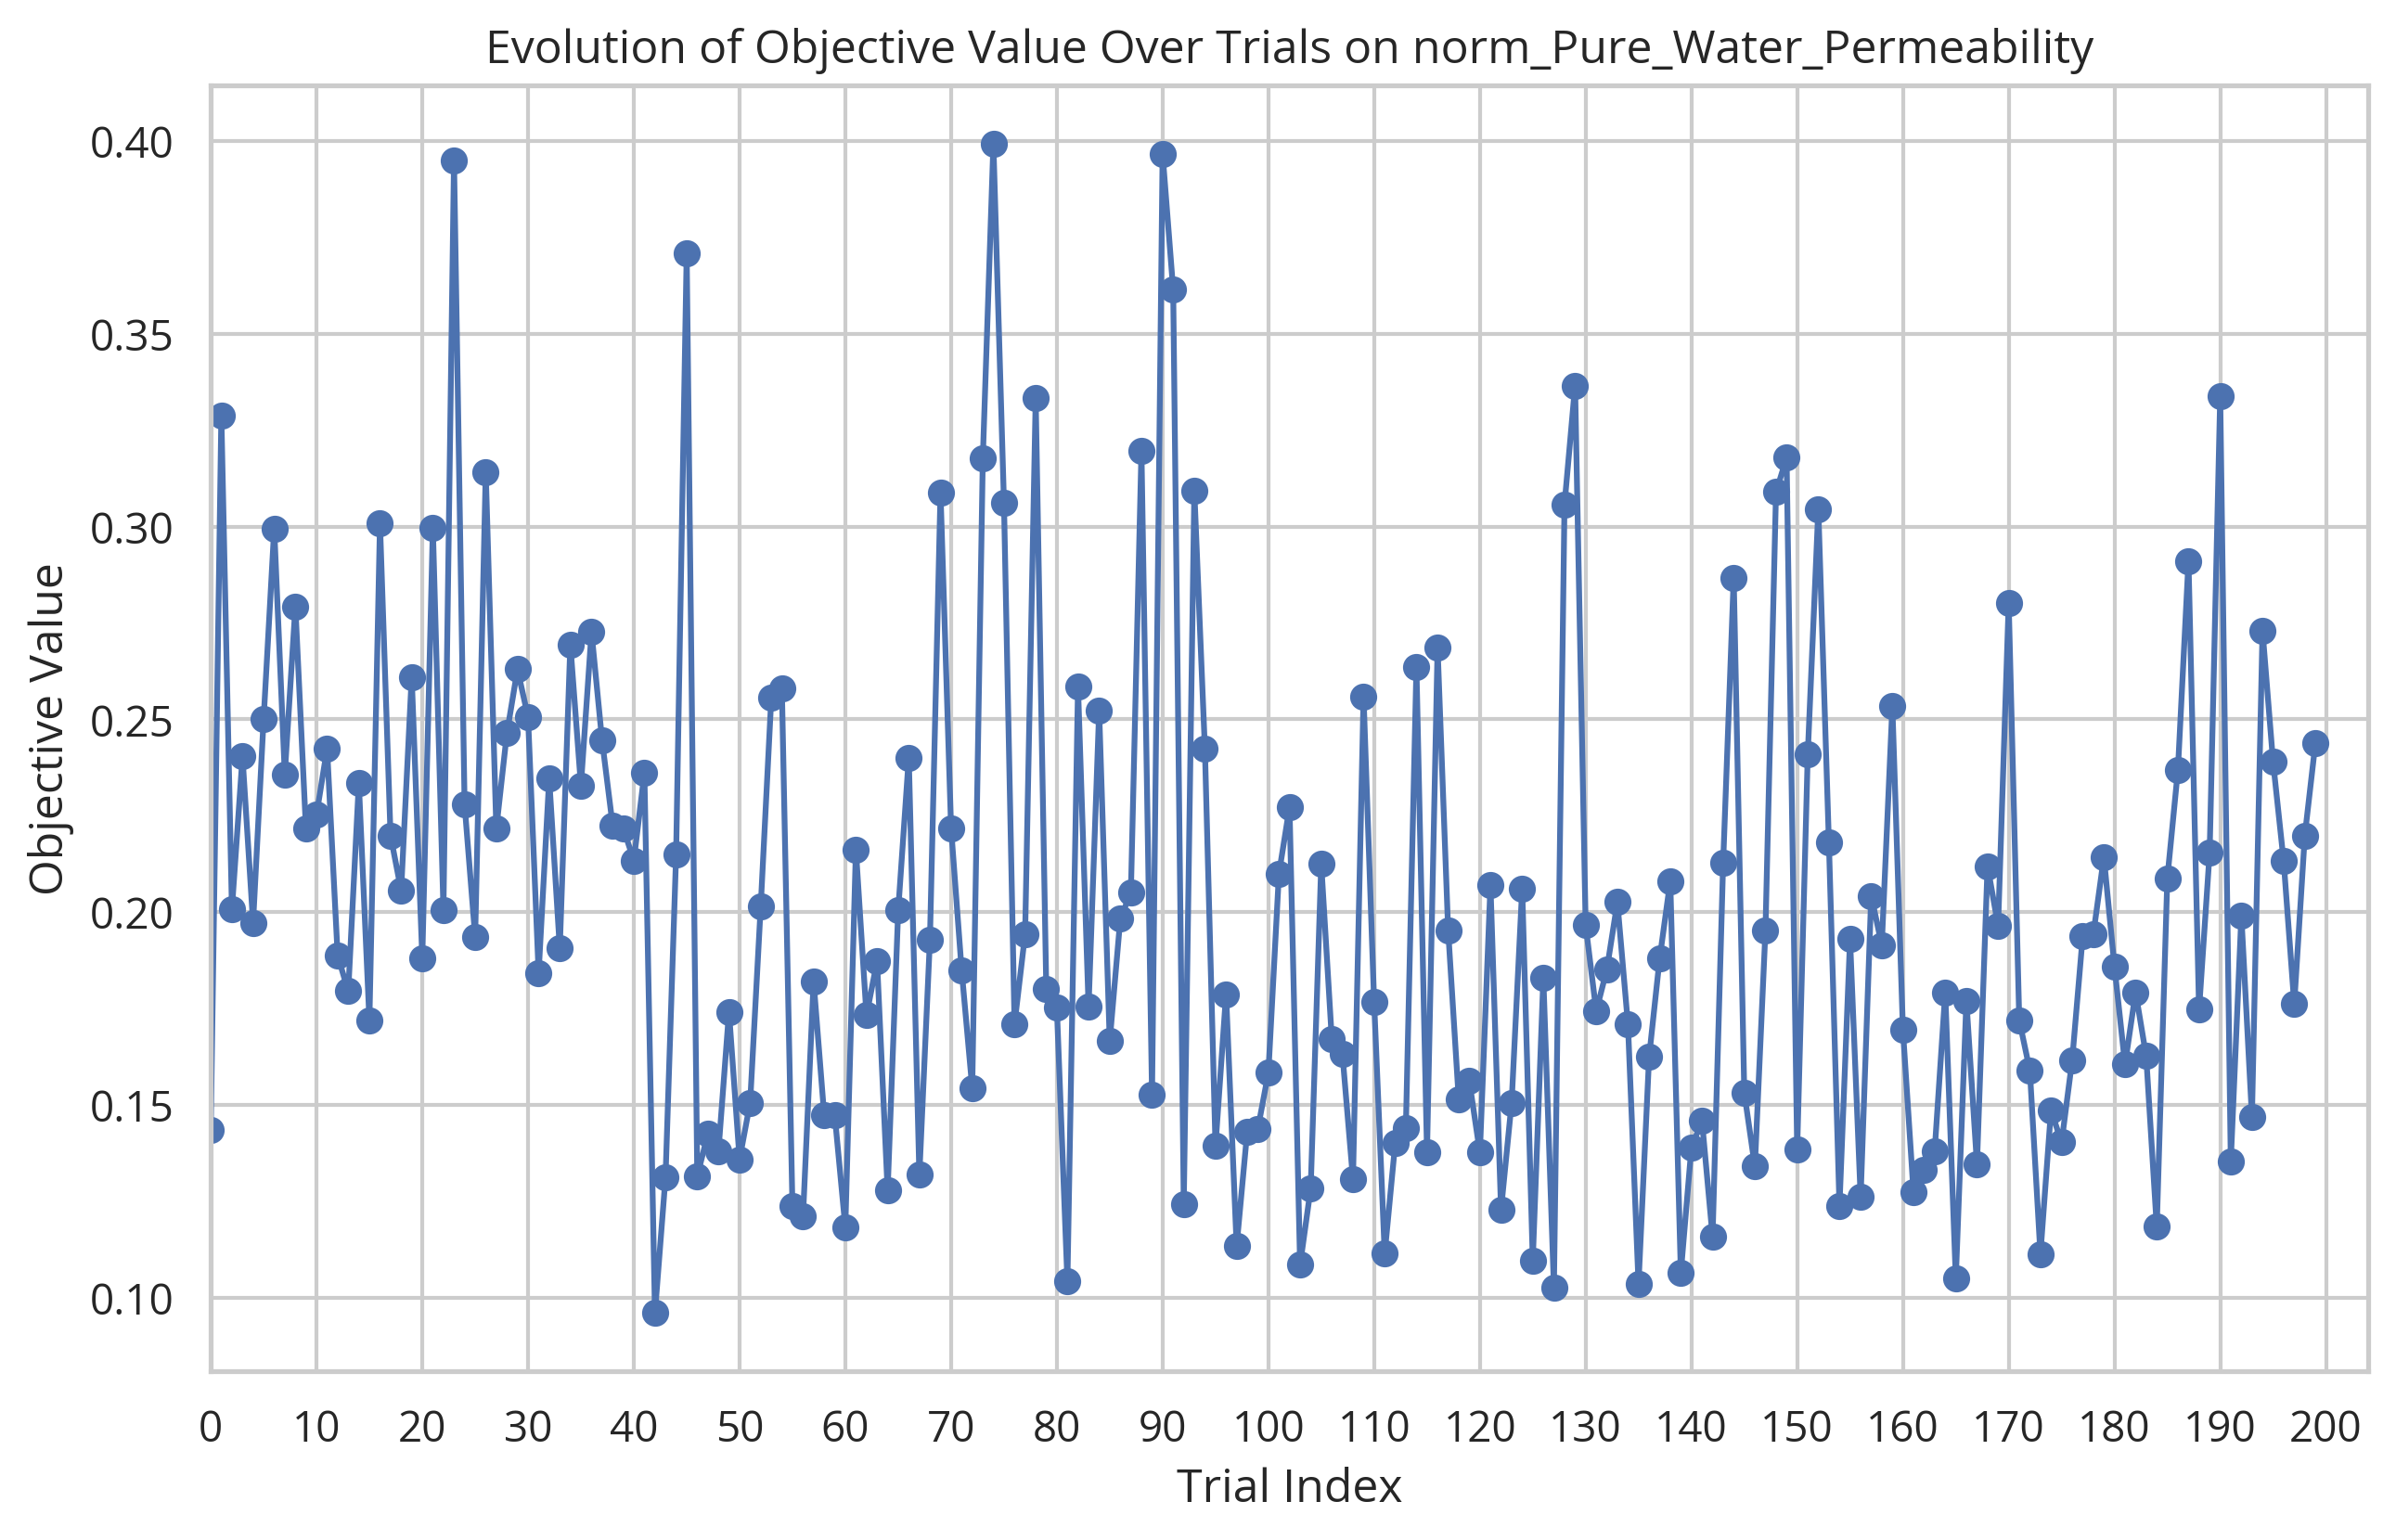

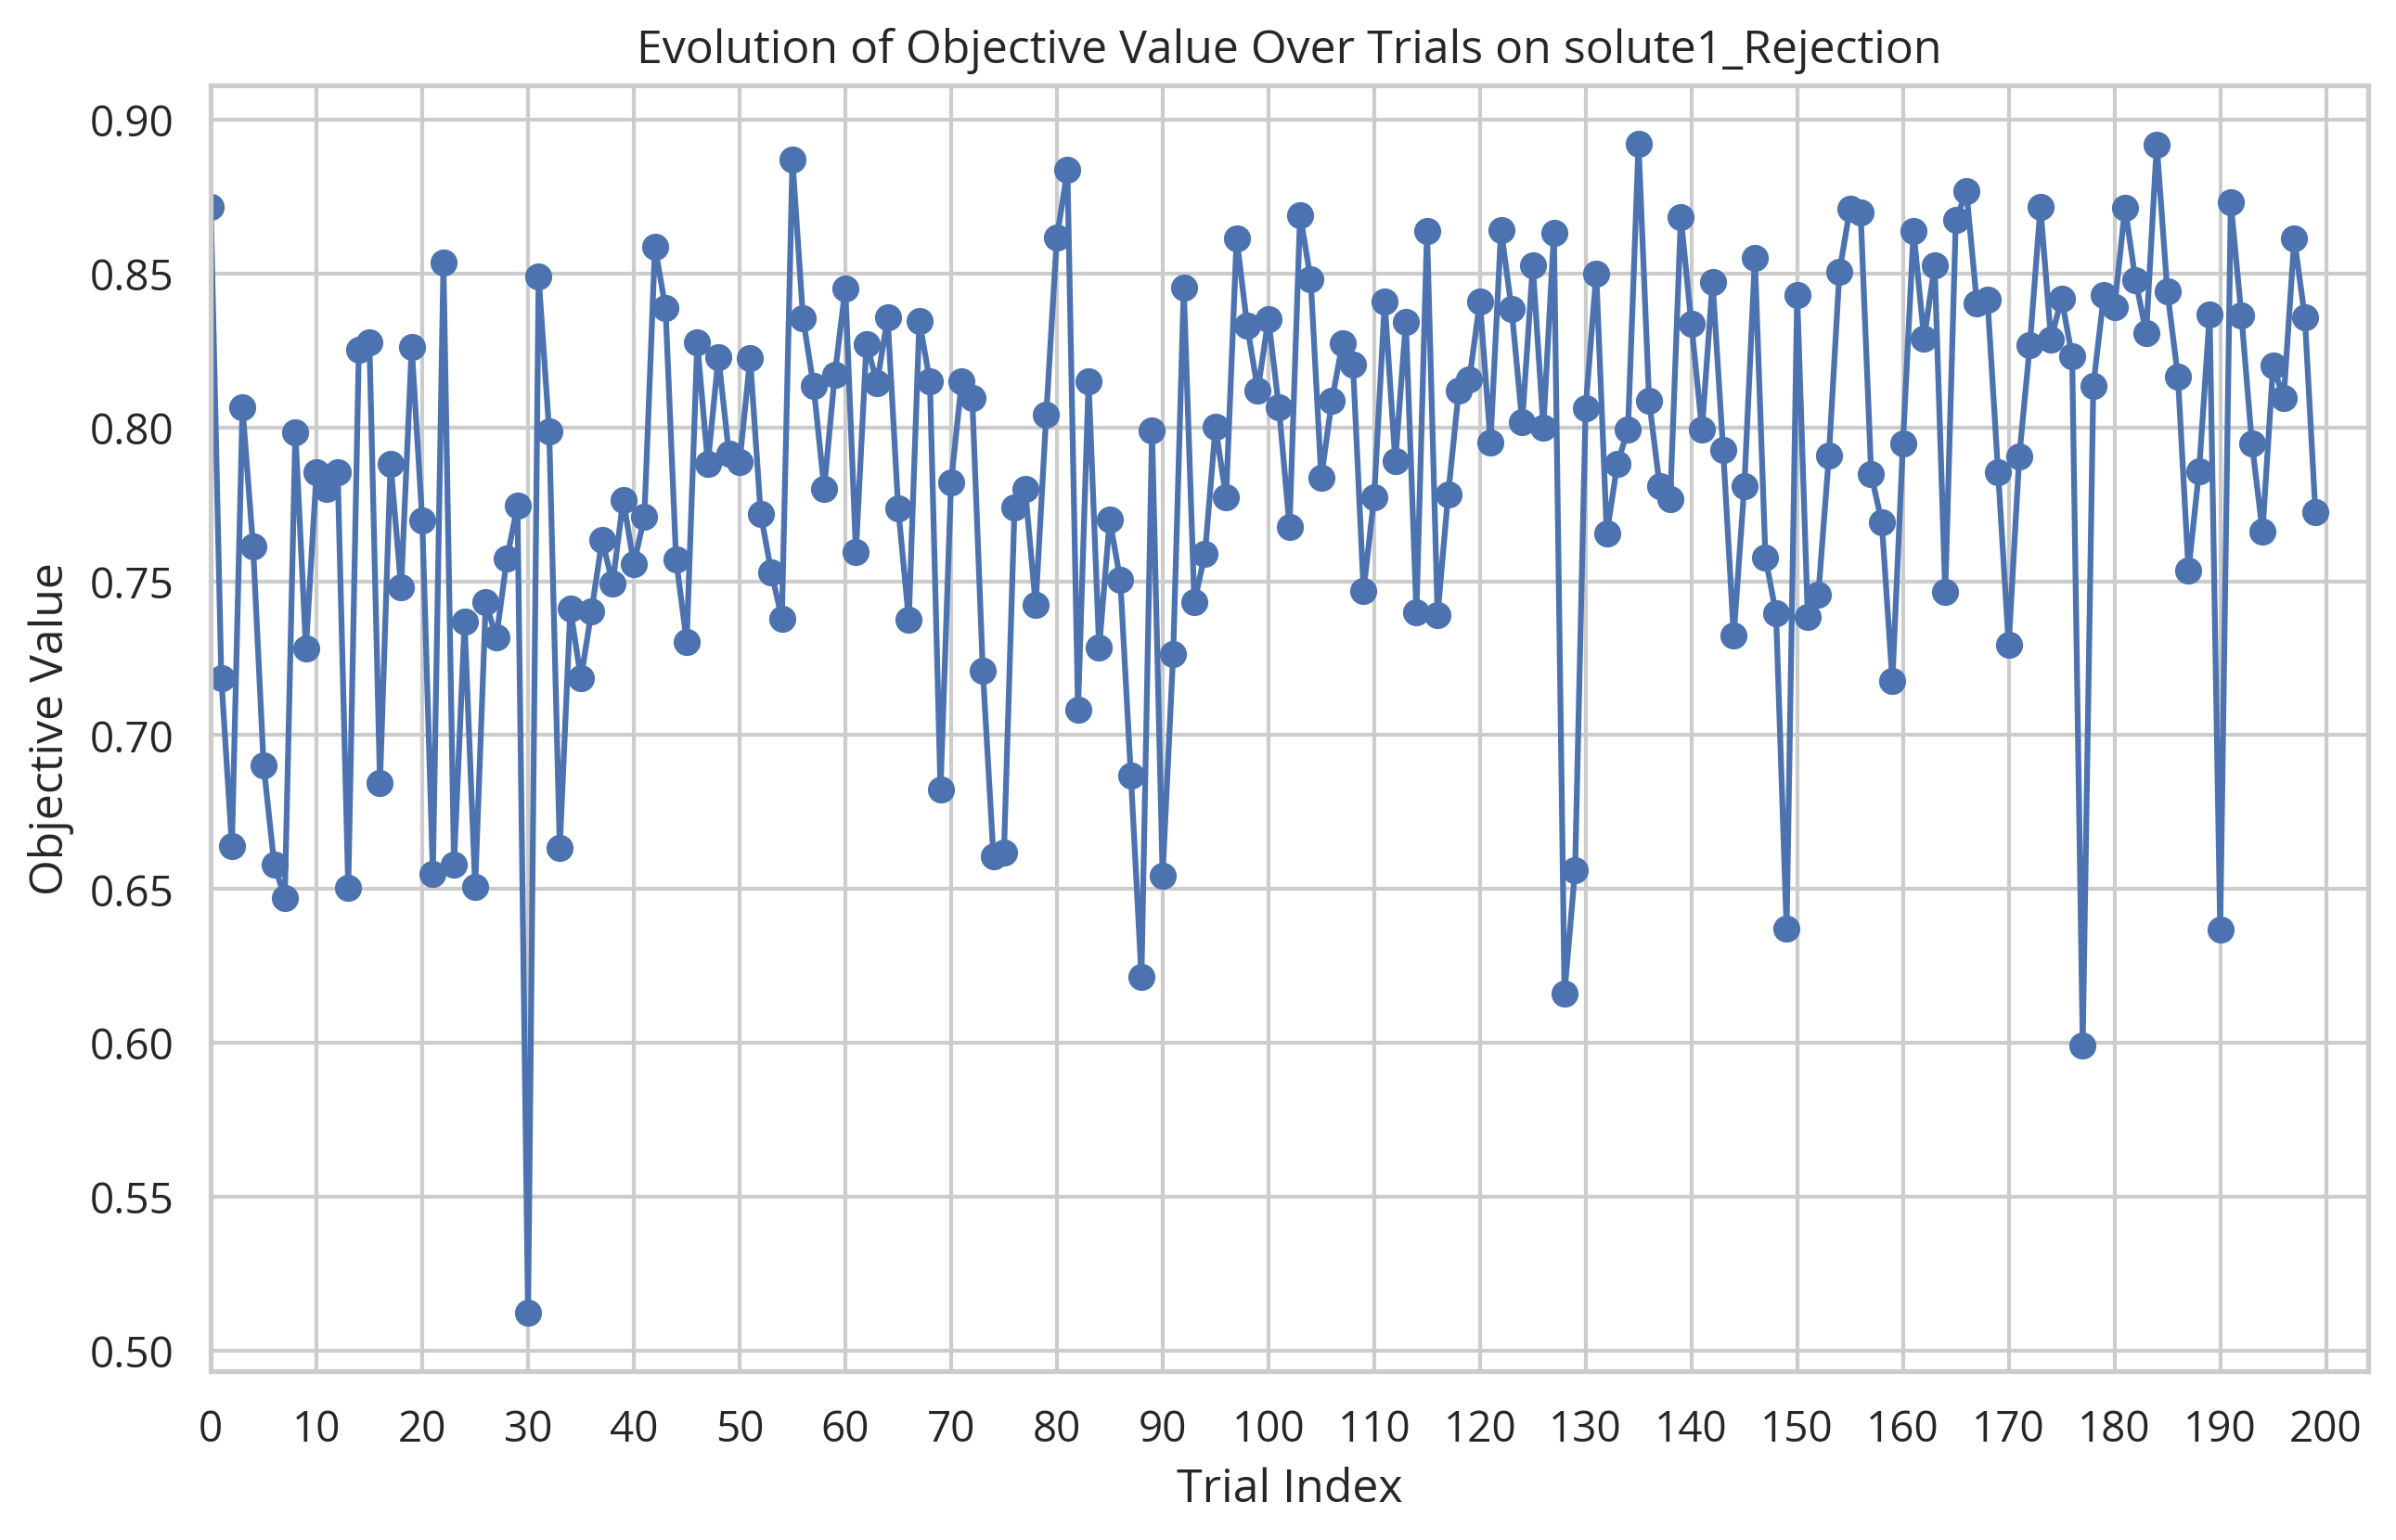

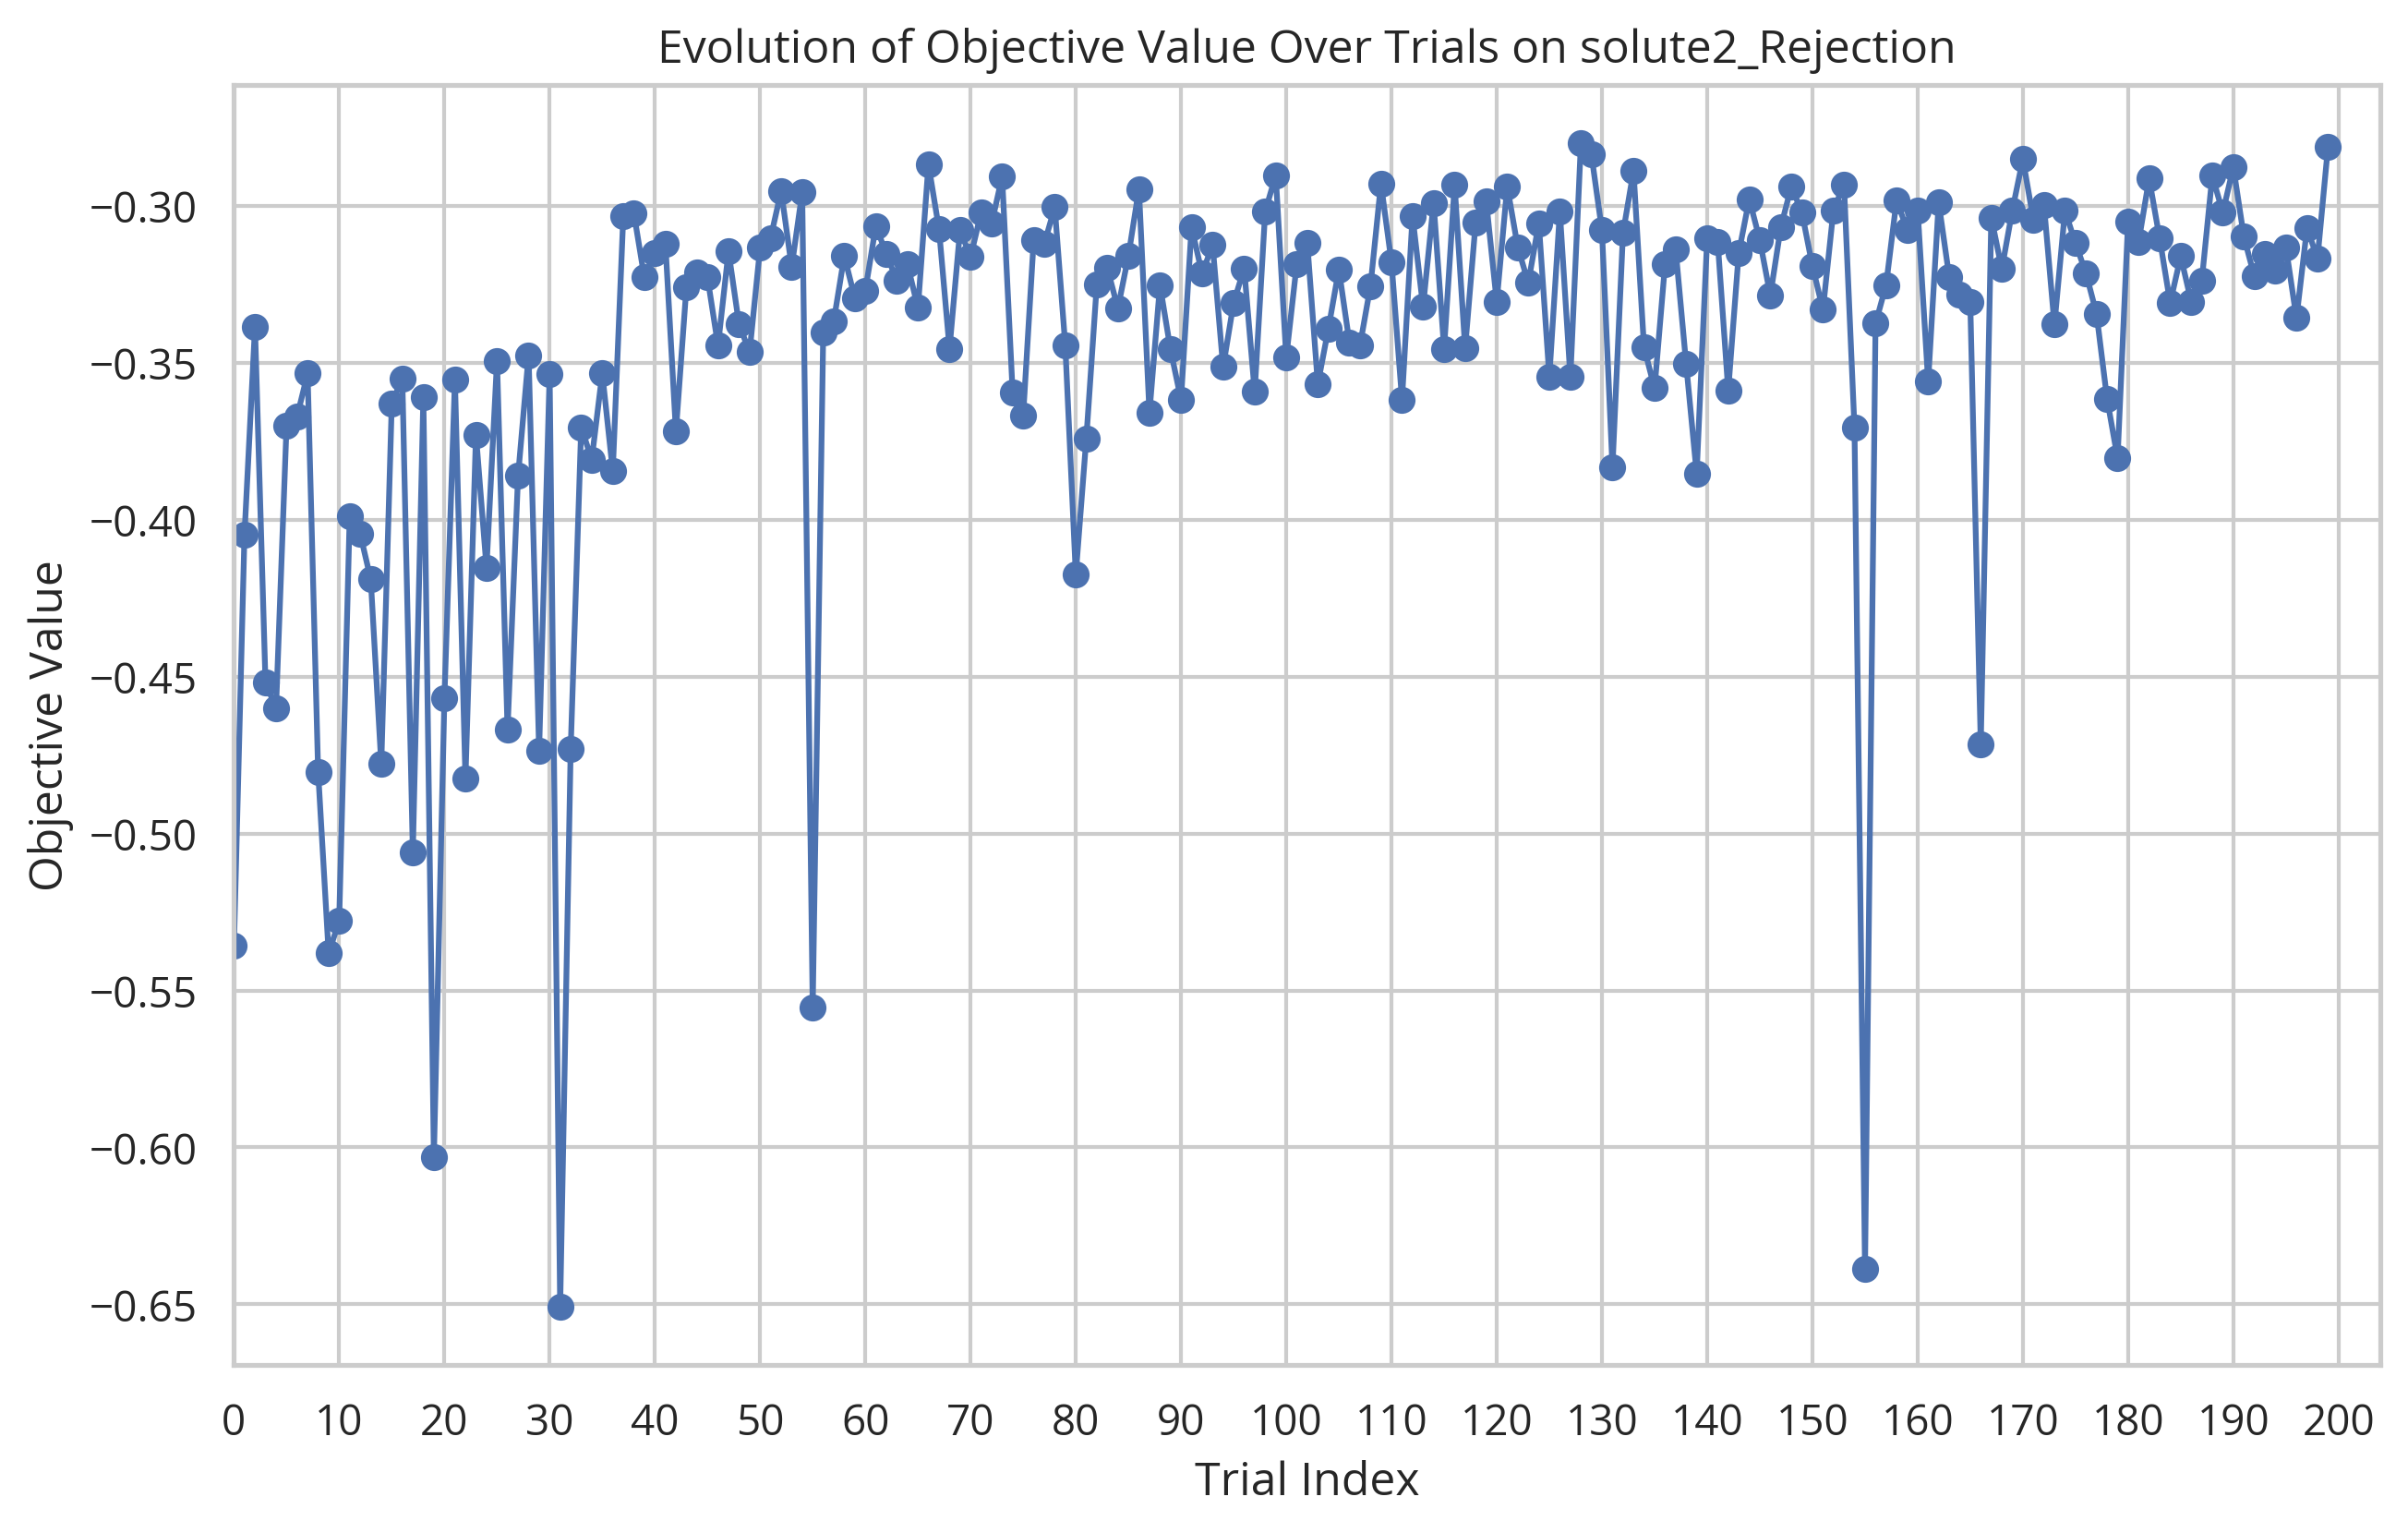

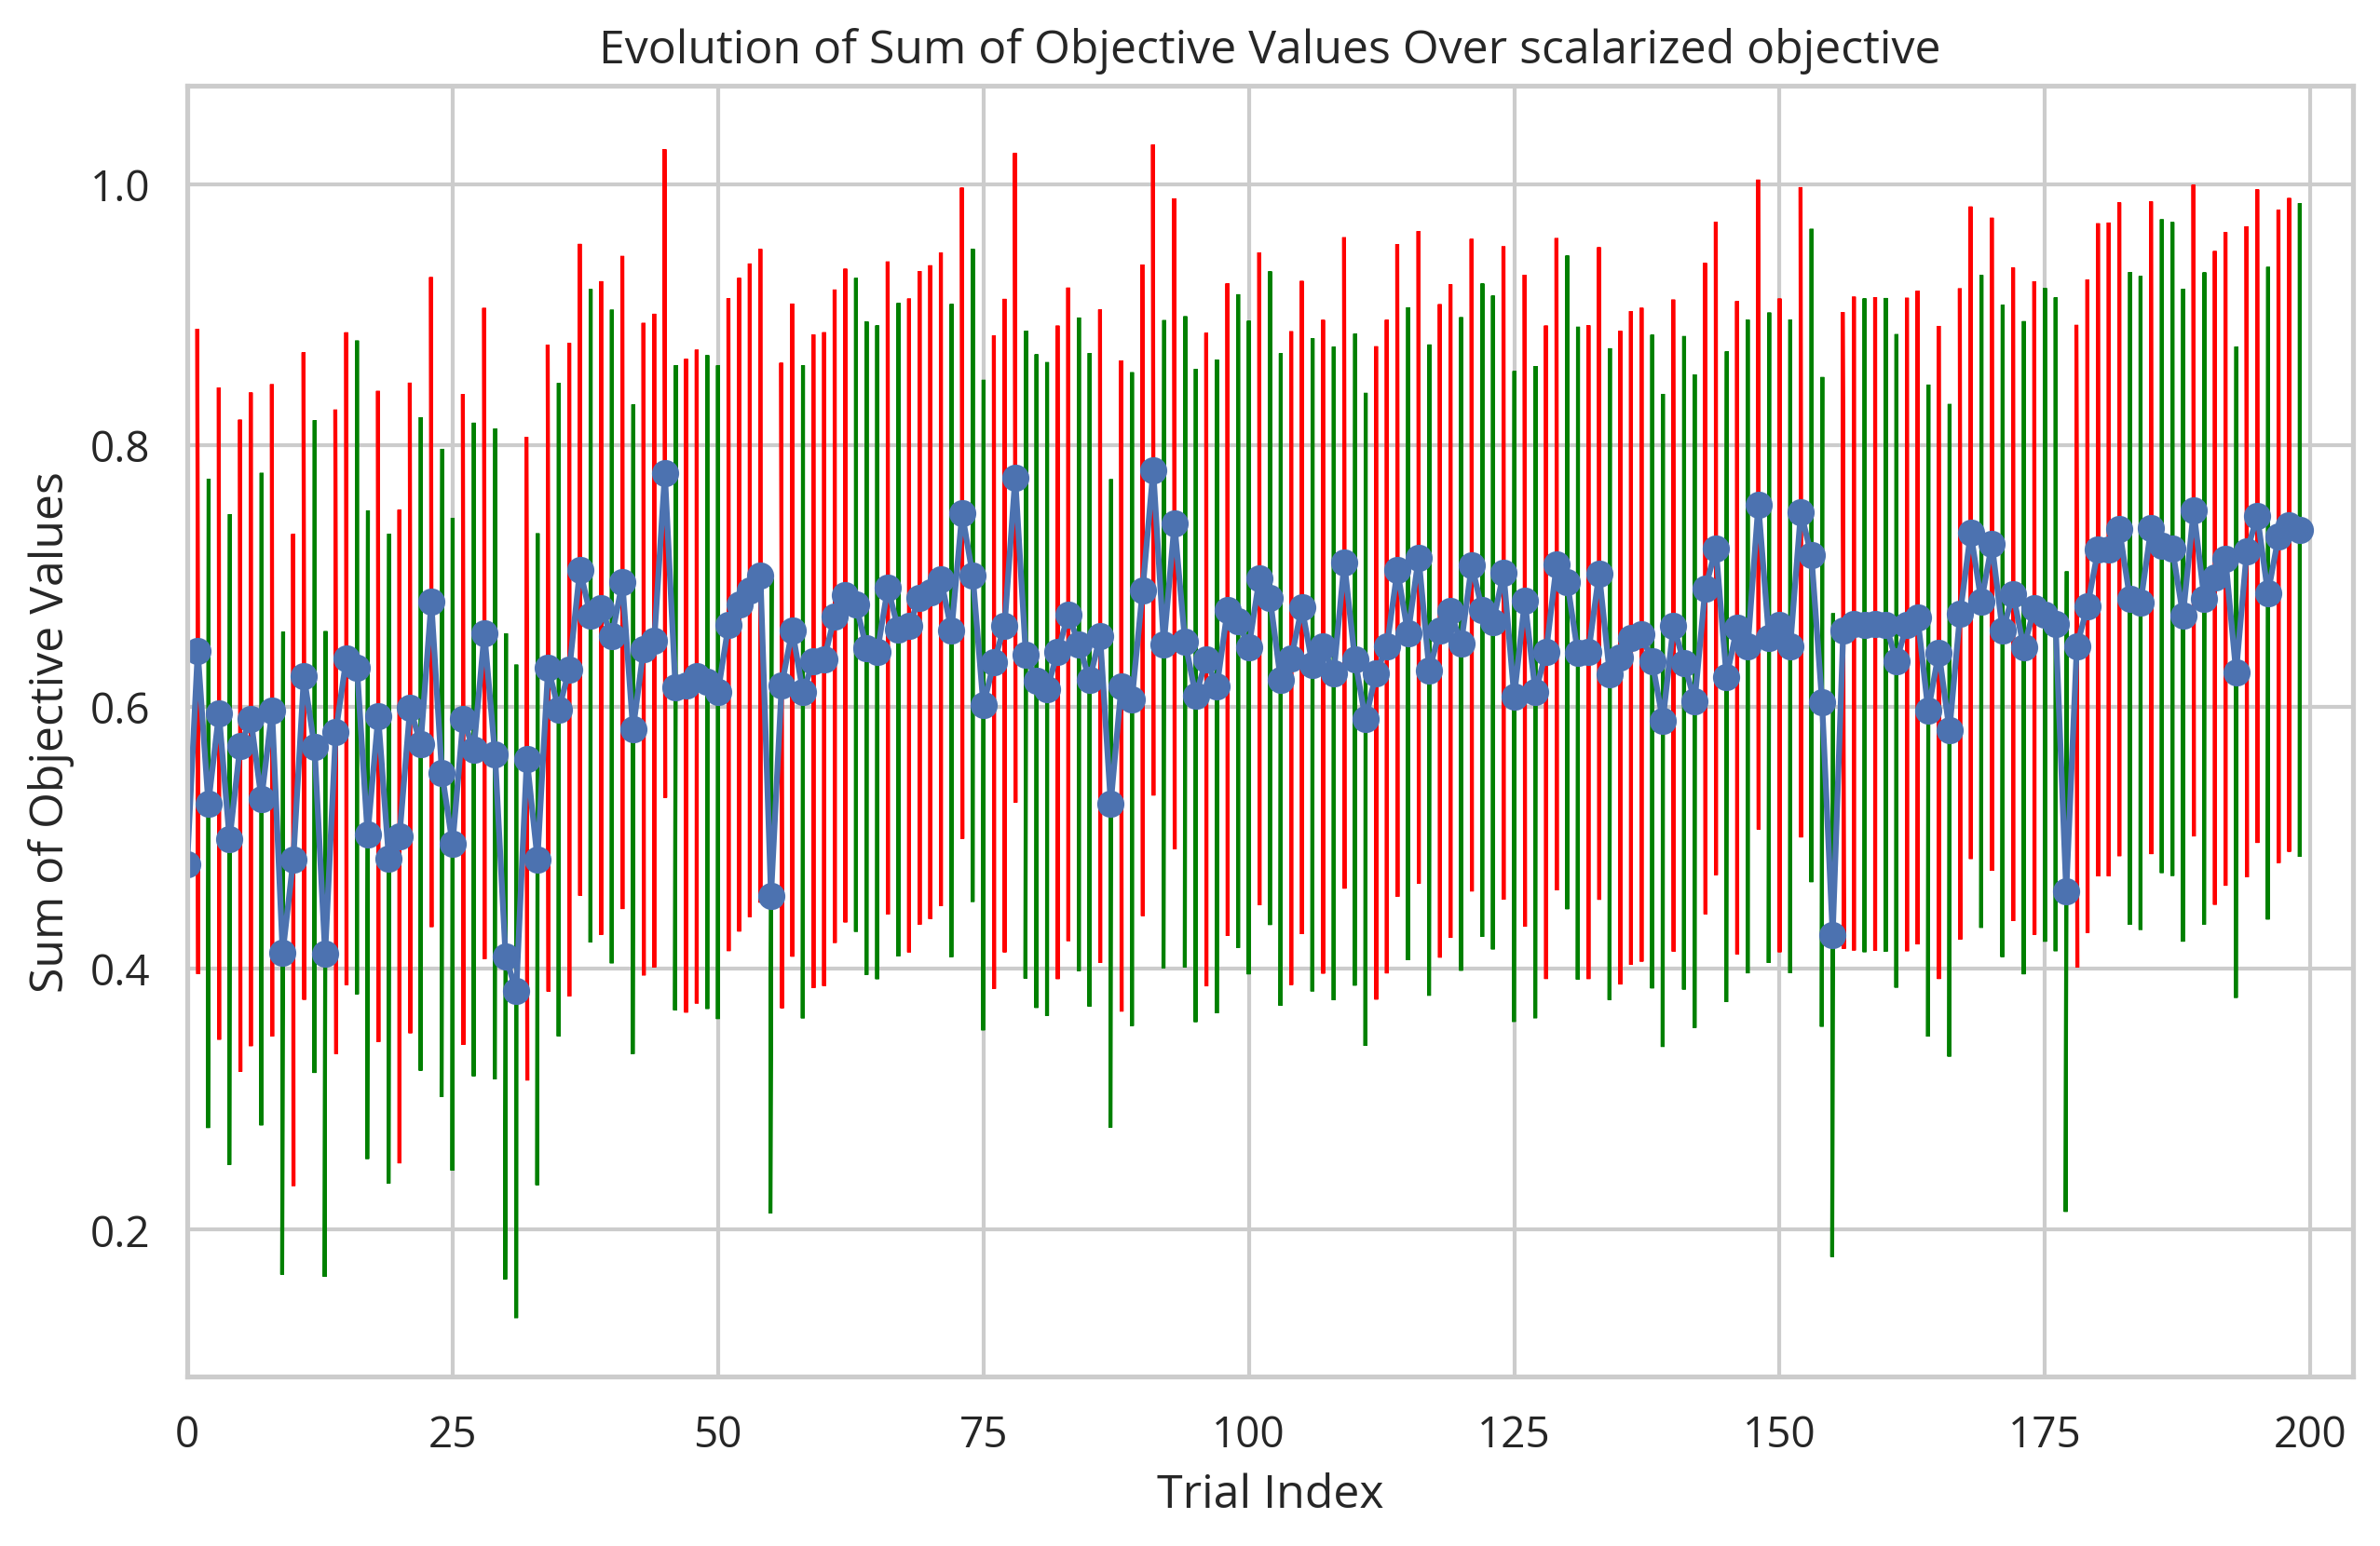

In [ ]:
# plot the evolution of the objective value over trial index
src_ax_path = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))
if src_ax_path not in sys.path:
    sys.path.insert(0, src_ax_path)
from utl_Ax import prepare_objective_history, plot_objective_evolution

objective_name = [
    "norm_Pure_Water_Permeability",
    "solute1_Rejection",
    "solute2_Rejection",
]

obj_func = prepare_objective_history(
    trial_df,
    objective_name,
    minimize_metrics=["solute2_Rejection"],
    trial_index_column="trial_index",
    aggregate_name="obj_sum",
)

plot_objective_evolution(
    obj_func,
    objective_name,
    trial_index_column="trial_index",
    aggregate_name="obj_sum",
    output_dir=".",
    aggregate_title="Evolution of Sum of Objective Values Over scalarized objective",
)

In [56]:
obj_func

,norm_Pure_Water_Permeability,solute1_Rejection,solute2_Rejection,trial_index,obj_sum
0,0.143552,0.871602,-0.535618,0,0.479536
1,0.328857,0.718440,-0.404881,1,0.642416
2,0.200731,0.664048,-0.338578,2,0.526200
3,0.240334,0.806458,-0.451932,3,0.594860
4,0.197193,0.761450,-0.460103,4,0.498541
...,...,...,...,...,...
195,0.238887,0.820126,-0.313183,195,0.745831
196,0.213207,0.809484,-0.335737,196,0.686954
197,0.176157,0.861335,-0.307137,197,0.730355
198,0.219860,0.835989,-0.316621,198,0.739228


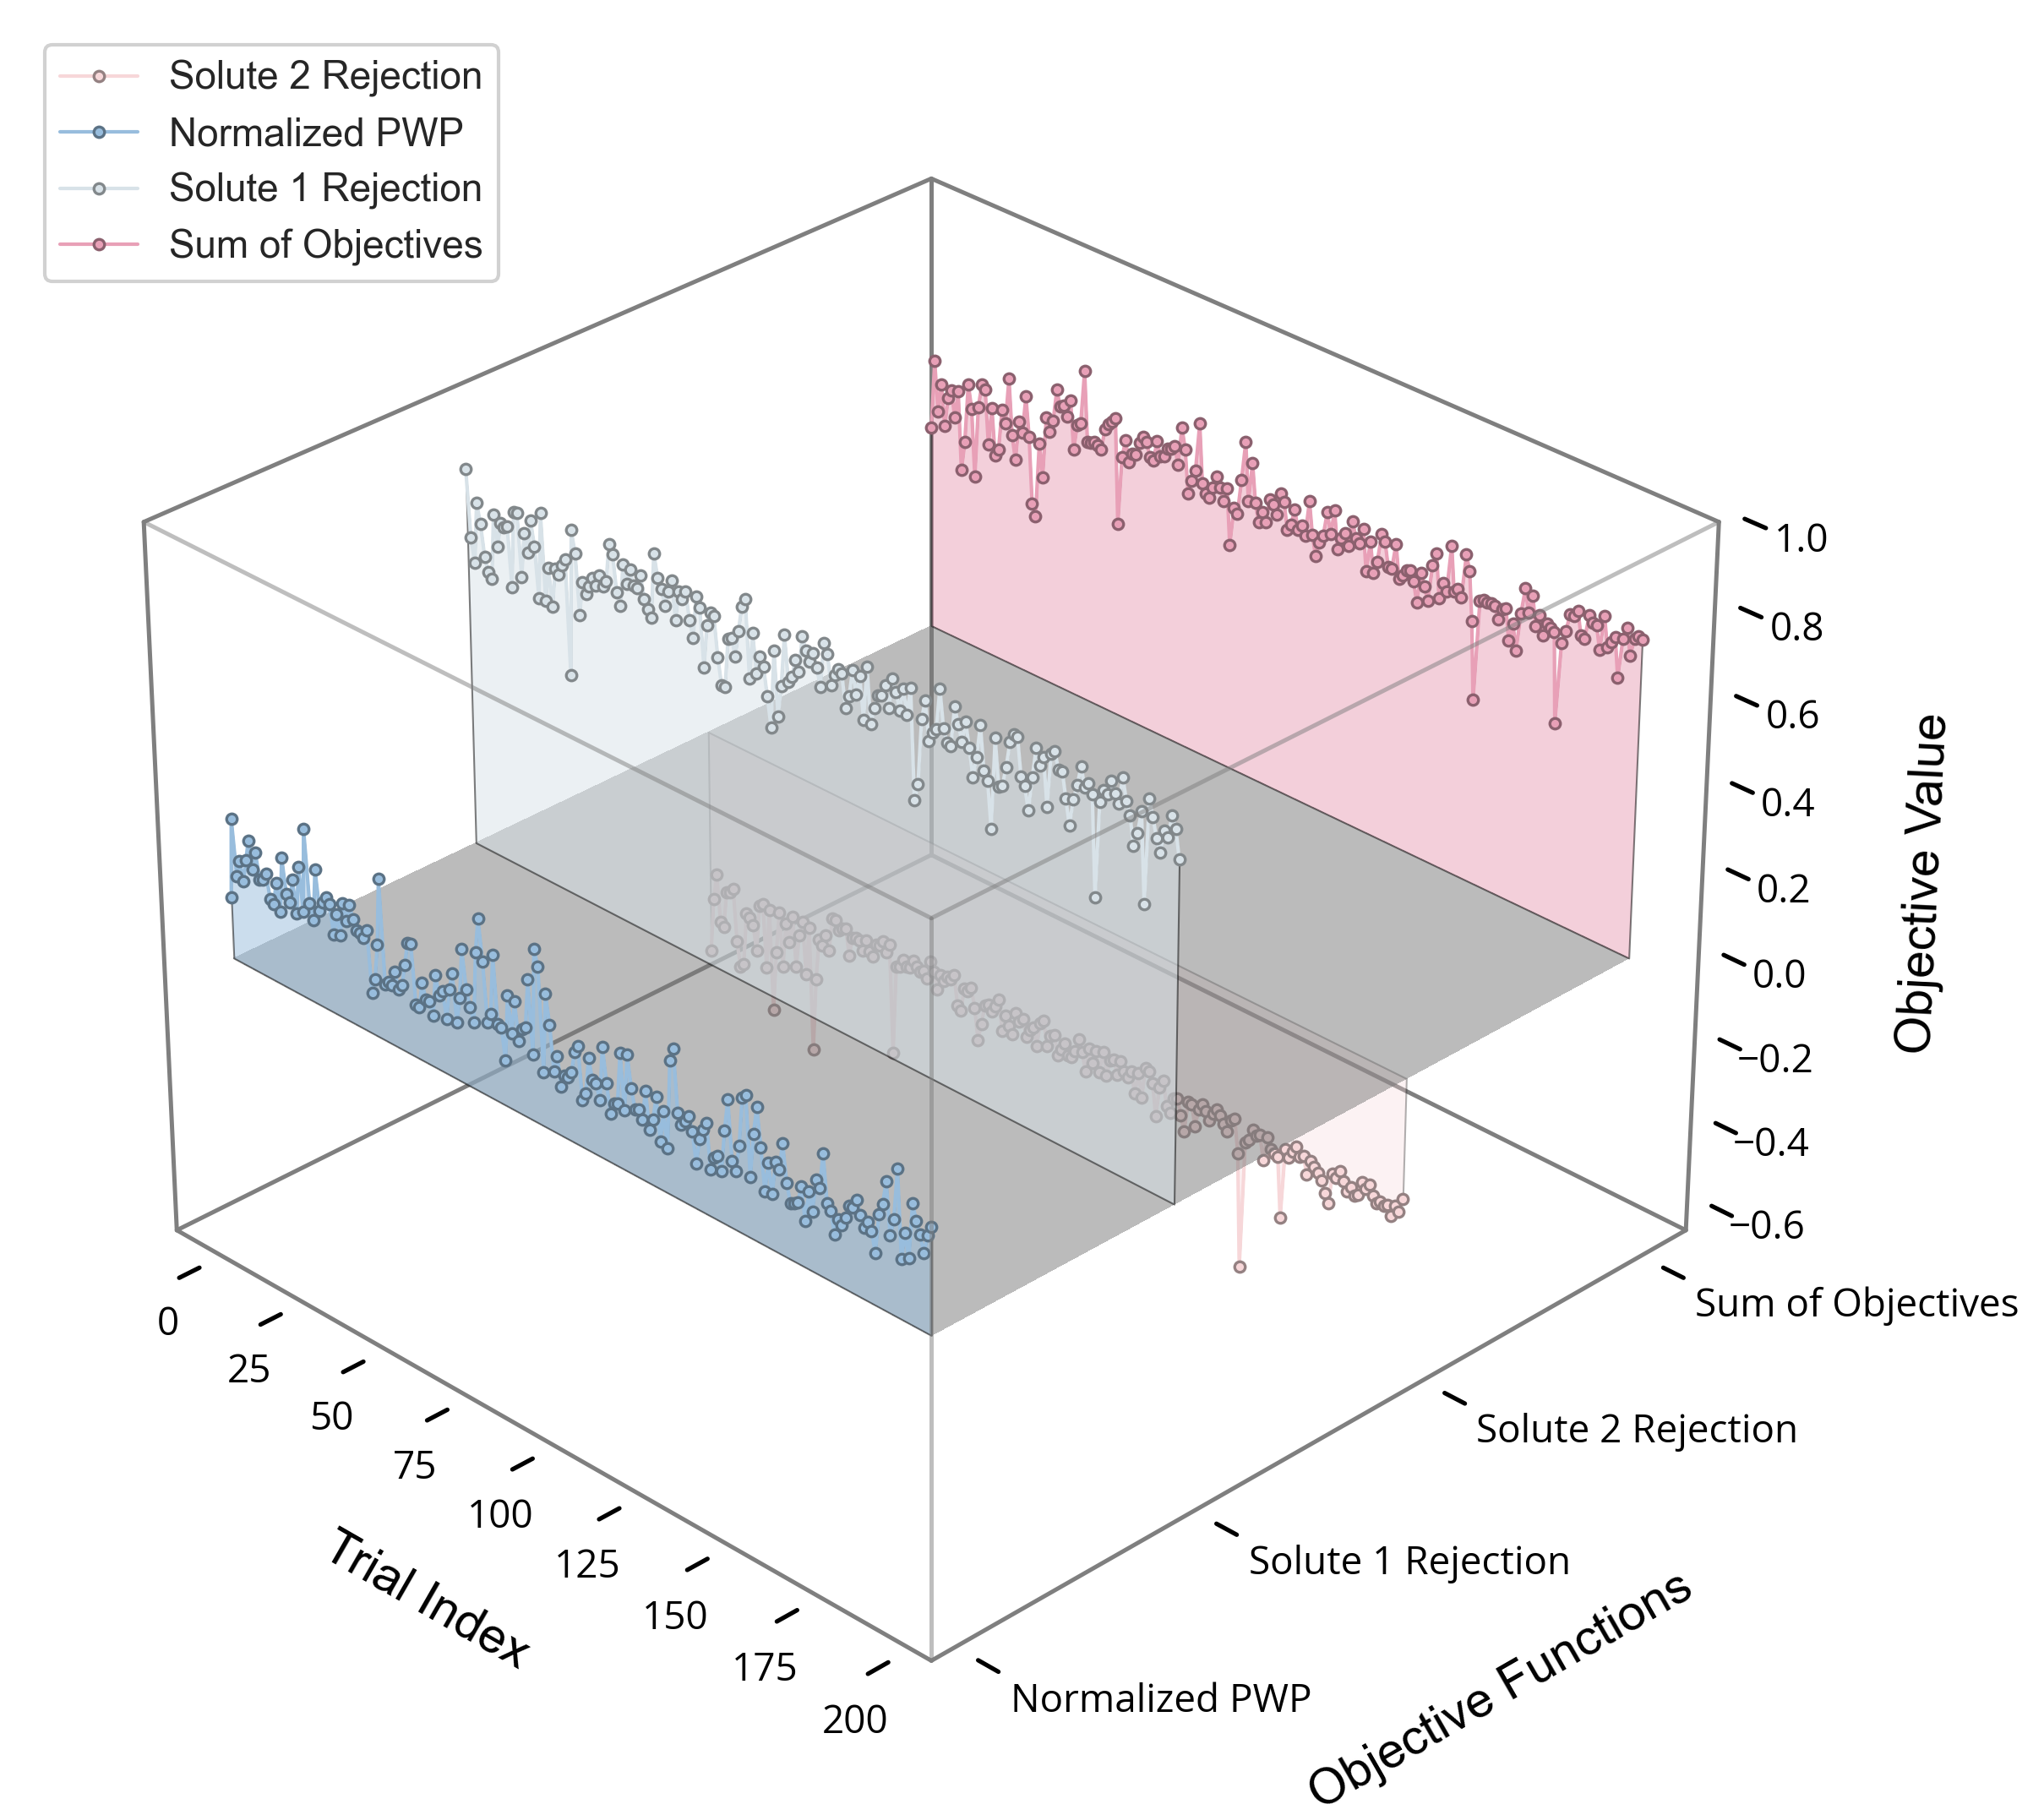

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import colormaps
from matplotlib.colors import to_rgb
from mpl_toolkits.mplot3d.art3d import Line3D, Poly3DCollection

obj_func_for_plot = pd.DataFrame()
# rename the columns for better visualization
obj_func_for_plot["Normalized PWP"] = obj_func["norm_Pure_Water_Permeability"]
obj_func_for_plot["Solute 1 Rejection"] = obj_func["solute1_Rejection"]
obj_func_for_plot["Solute 2 Rejection"] = obj_func["solute2_Rejection"]
obj_func_for_plot["Sum of Objectives"] = obj_func["obj_sum"]




# Define required objective names for plotting
objective_name_for_plot = ["Normalized PWP",
                #   "norm_salt_sol_Permeability",
                  "Solute 1 Rejection", "Solute 2 Rejection", "Sum of Objectives"]

# Plotting the 3D surface
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.computed_zorder = False  # Respect draw order so plane can sit between negative and positive parts
fig.subplots_adjust(left=0.10, right=0.94, bottom=0.08, top=0.95)
# Define a custom c olormap 
colors = [custom_cmap(0.1), custom_cmap(0.35), custom_cmap(0.65), custom_cmap(0.9)]
text_color = "#000000"      # 深灰色/接近黑色，用于文字
line_color = "#7F7F7F"      # 深灰色，用于线条和边框
grid_color = "#B0B0B0"      # 浅灰色，用于网格

def darken_color(color, factor=0.6):
    rgb = np.array(to_rgb(color))
    return tuple(np.clip(rgb * factor, 0, 1))

# Change the position of the y-axis 
y_positions = [0, 1.5, 3, 4.5]

xs = np.asarray(trial_indices)
positive_layers = []

# Create waterfall plot for each objective
for i, obj in enumerate(objective_name_for_plot):
    values = obj_func_for_plot[obj].values.astype(float)
    ys = np.full_like(xs, y_positions[i], dtype=float)
    color = colors[i]
    outline_color = darken_color(color)

    values_neg = np.minimum(values, 0.0)
    values_pos = np.maximum(values, 0.0)
    has_neg = np.any(values_neg < 0)
    has_pos = np.any(values_pos > 0)

    # Draw negative part first (below plane)
    if has_neg:
        verts_neg = [[xs[0], ys[0], 0.0]]
        for j in range(len(xs)):
            verts_neg.append([xs[j], ys[j], values_neg[j]])
        verts_neg.append([xs[-1], ys[-1], 0.0])

        poly_neg = Poly3DCollection([verts_neg], alpha=0.3, facecolor=color,  edgecolor='black', linewidth=0.5)
        poly_neg.set_zorder(1)
        ax.add_collection3d(poly_neg)

        label_neg = obj if not has_pos else None
        ax.plot(
            xs, ys, values_neg,
            color=color, linewidth=1, marker='o', markersize=3,
            markeredgecolor=outline_color, markeredgewidth=0.8,
            alpha=1.0, label=label_neg, zorder=1
        )

    # Store positive part to draw after the z=0 plane
    positive_layers.append((obj, xs.copy(), ys.copy(), values_pos.copy(), color, outline_color, has_pos))

# Add a transparent XY reference plane at z=0 (between negative and positive layers)
x_plane = np.linspace(np.min(xs), np.max(xs), 2)
y_plane = np.linspace(np.min(y_positions), np.max(y_positions), 2)
X_plane, Y_plane = np.meshgrid(x_plane, y_plane)
Z_plane = np.zeros_like(X_plane)
ax.plot_surface(
    X_plane, Y_plane, Z_plane,
    color="#9E9E9E", alpha=0.5,
    edgecolor='none', linewidth=0, antialiased=False, shade=True, zorder=2
)

count = len(positive_layers)
# Draw positive part after plane (above plane)
for obj, xs_pos, ys_pos, values_pos, color, outline_color, has_pos in positive_layers:
    if not has_pos:
        continue

    verts_pos = [[xs_pos[0], ys_pos[0], 0.0]]
    for j in range(len(xs_pos)):
        verts_pos.append([xs_pos[j], ys_pos[j], values_pos[j]])
    verts_pos.append([xs_pos[-1], ys_pos[-1], 0.0])

    poly_pos = Poly3DCollection([verts_pos], alpha=0.5, facecolor=color, edgecolor='black', linewidth=0.5)
    poly_pos.set_zorder(3)
    ax.add_collection3d(poly_pos)
    count += 1
    ax.plot(
        xs_pos, ys_pos, values_pos,
        color=color, linewidth=1, marker='o', markersize=3,
        markeredgecolor=outline_color, markeredgewidth=0.8,
        alpha=1.0, label=obj, zorder=3 + count
    )

# Set labels and title with the custom text color
ax.set_xlabel('Trial Index', fontsize=14, labelpad=10, color=text_color, fontfamily='Arial')
ax.set_ylabel('Objective Functions', fontsize=14, labelpad=30, color=text_color, fontfamily='Arial')
ax.set_zlabel('Objective Value', fontsize=14, labelpad=10, color=text_color, fontfamily='Arial')

# Set y-ticks and labels
ax.set_yticks(y_positions)
ax.set_yticklabels(objective_name_for_plot)
ax.tick_params(axis='y', pad=0)

# Change view angle
ax.view_init(elev=15, azim=-60)

# Keep panes transparent so only the manual box frame is visible
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False

ax.xaxis.pane.set_edgecolor((0, 0, 0, 0))
ax.yaxis.pane.set_edgecolor((0, 0, 0, 0))
ax.zaxis.pane.set_edgecolor((0, 0, 0, 0))
ax.xaxis.pane.set_linewidth(0)
ax.yaxis.pane.set_linewidth(0)
ax.zaxis.pane.set_linewidth(0)

# Hide the built-in 3D axis lines so they do not conflict with the manual box edges
ax.xaxis.line.set_color((0, 0, 0, 0))
ax.yaxis.line.set_color((0, 0, 0, 0))
ax.zaxis.line.set_color((0, 0, 0, 0))
ax.xaxis.line.set_linewidth(1)
ax.yaxis.line.set_linewidth(1)
ax.zaxis.line.set_linewidth(1)

# 设置刻度线和刻度标签颜色为深灰色
ax.tick_params(axis='x', colors=text_color, width=5, pad=0)
ax.tick_params(axis='y', colors=text_color, width=5, pad=0)
ax.tick_params(axis='z', colors=text_color, width=5, pad=0)

for label in ax.get_yticklabels():
    label.set_horizontalalignment('left')
    label.set_verticalalignment('center')
    label.set_rotation(0)

# 设置网格线为浅灰色
ax.xaxis._axinfo["grid"]['color'] = grid_color
ax.yaxis._axinfo["grid"]['color'] = grid_color
ax.zaxis._axinfo["grid"]['color'] = grid_color
ax.xaxis._axinfo["grid"]['linewidth'] = 1
ax.yaxis._axinfo["grid"]['linewidth'] = 1
ax.zaxis._axinfo["grid"]['linewidth'] = 1

# Remove grid lines
ax.grid(False)

xlim = ax.get_xlim()
ylim = ax.get_ylim()
zlim = ax.get_zlim()
ax.view_init(elev= ELEV3D, azim=AZIM3D)

# Split the manual frame so visible front edges draw above the data and back edges stay behind it
front_edges = [
    ([xlim[0], xlim[1]], [ylim[0], ylim[0]], [zlim[1], zlim[1]]),
    ([xlim[1], xlim[1]], [ylim[0], ylim[0]], [zlim[0], zlim[1]]),
    ([xlim[1], xlim[1]], [ylim[0], ylim[1]], [zlim[1], zlim[1]]),
]

back_edges = [
    ([xlim[0], xlim[1]], [ylim[1], ylim[1]], [zlim[0], zlim[0]]),
    ([xlim[0], xlim[1]], [ylim[1], ylim[1]], [zlim[1], zlim[1]]),
    ([xlim[0], xlim[0]], [ylim[0], ylim[1]], [zlim[0], zlim[0]]),
    ([xlim[0], xlim[0]], [ylim[0], ylim[1]], [zlim[1], zlim[1]]),
    ([xlim[0], xlim[0]], [ylim[1], ylim[1]], [zlim[0], zlim[1]]),
    ([xlim[1], xlim[1]], [ylim[1], ylim[1]], [zlim[0], zlim[1]]),
    ([xlim[0], xlim[0]], [ylim[0], ylim[0]], [zlim[0], zlim[1]]),
    ([xlim[1], xlim[1]], [ylim[0], ylim[1]], [zlim[0], zlim[0]]),
    ([xlim[0], xlim[1]], [ylim[0], ylim[0]], [zlim[0], zlim[0]]),
]

for edge in back_edges:
    line = Line3D(
        edge[0], edge[1], edge[2],
        color=line_color, linewidth=1.2, alpha=1.0, zorder=0
    )
    line.set_clip_on(False)
    ax.add_line(line)

for edge in front_edges:
    line = Line3D(
        edge[0], edge[1], edge[2],
        color=line_color, linewidth=1.2, alpha=0.5, zorder=1000
    )
    line.set_clip_on(False)
    ax.add_line(line)

# Add legend with custom text color
legend = ax.legend(loc='upper left', fontsize=14, framealpha=0.9,
                   prop={'family': 'Arial'})



# Scatterplot

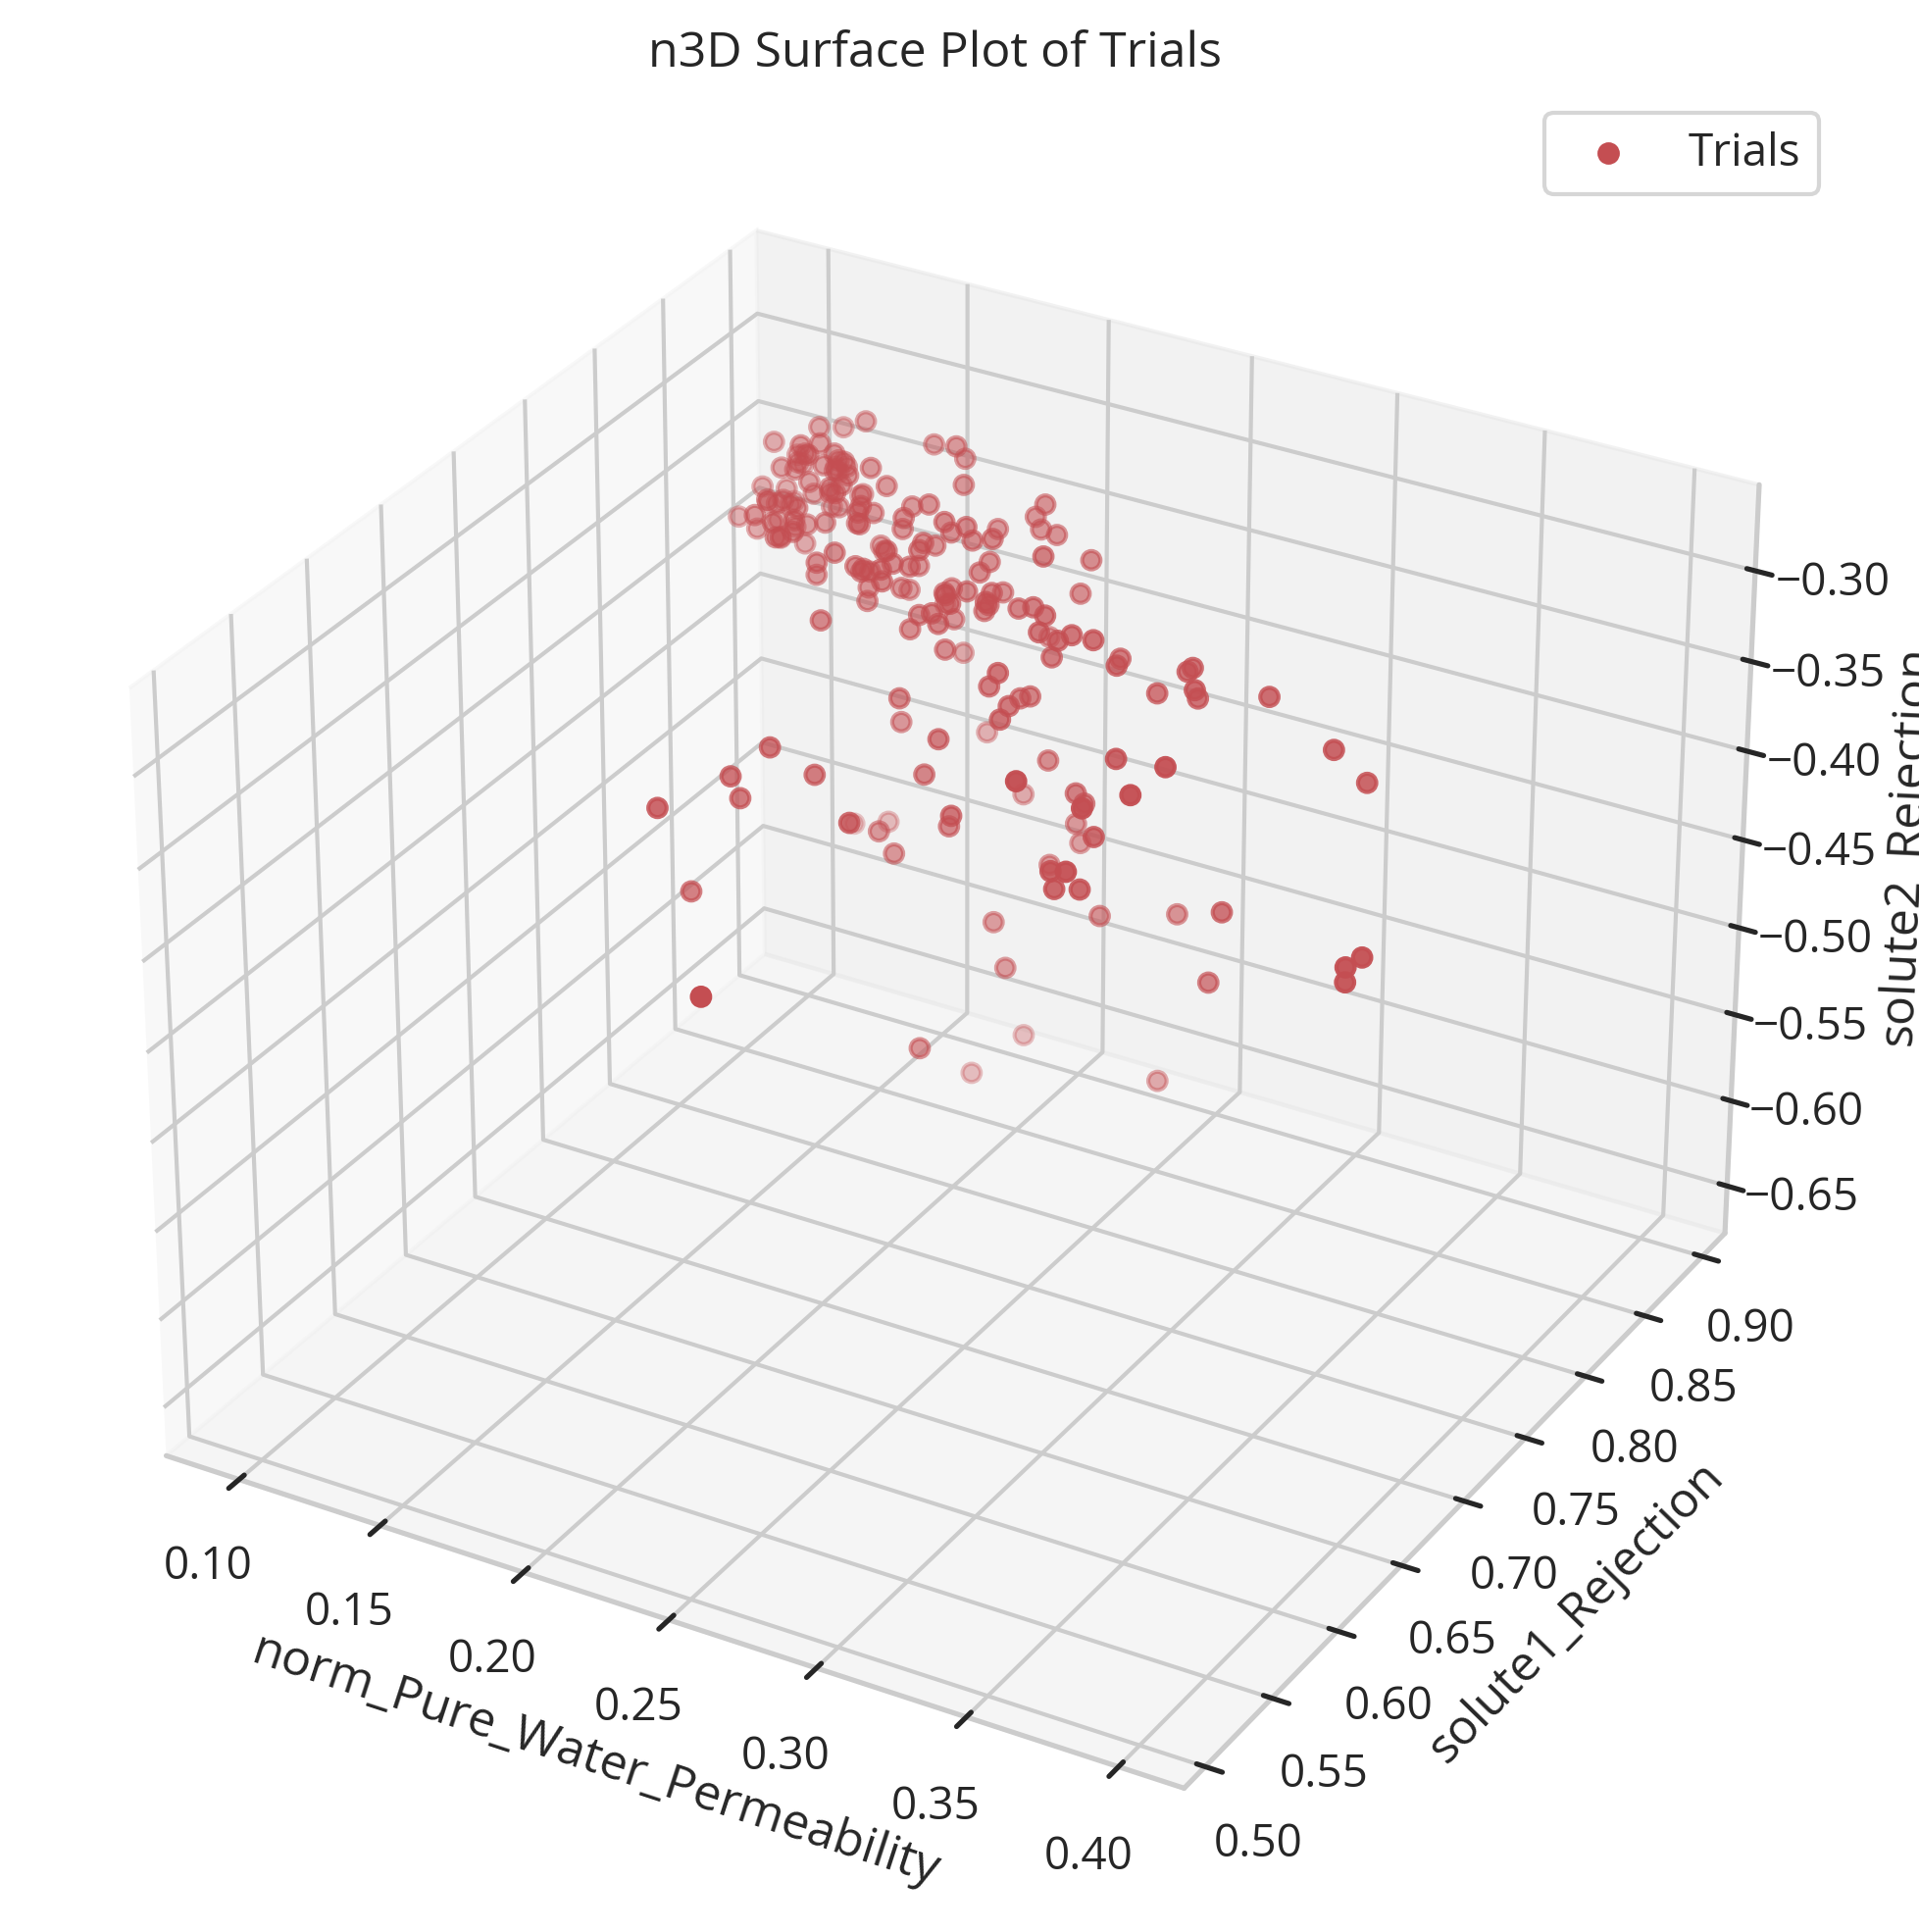

In [58]:
# %matplotlib widget  
# # Enable interactive matplotlib plots in Jupyter

# import matplotlib.pyplot as plt
# from mpl_toolkits.mplot3d import Axes3D

figure = plt.figure(figsize=(10, 8))
ax = figure.add_subplot(111, projection='3d')
ax.scatter(trial_df['norm_Pure_Water_Permeability'], trial_df['solute1_Rejection'], -1*trial_df['solute2_Rejection'], 
           c='r', marker='o', label='Trials')
ax.set_xlabel('norm_Pure_Water_Permeability')
ax.set_ylabel('solute1_Rejection')
ax.set_zlabel('solute2_Rejection')
ax.set_title('n3D Surface Plot of Trials')

# ax.set_xlim([0.1, 1.25*trial_df['norm_Pure_Water_Permeability'].median()])
# ax.set_ylim([0.6, 1.25*trial_df['solute1_Rejection'].median()])
# ax.set_zlim([-0.2, 1.25*trial_df['solute2_Rejection'].median()])


ax.legend()

plt.show()


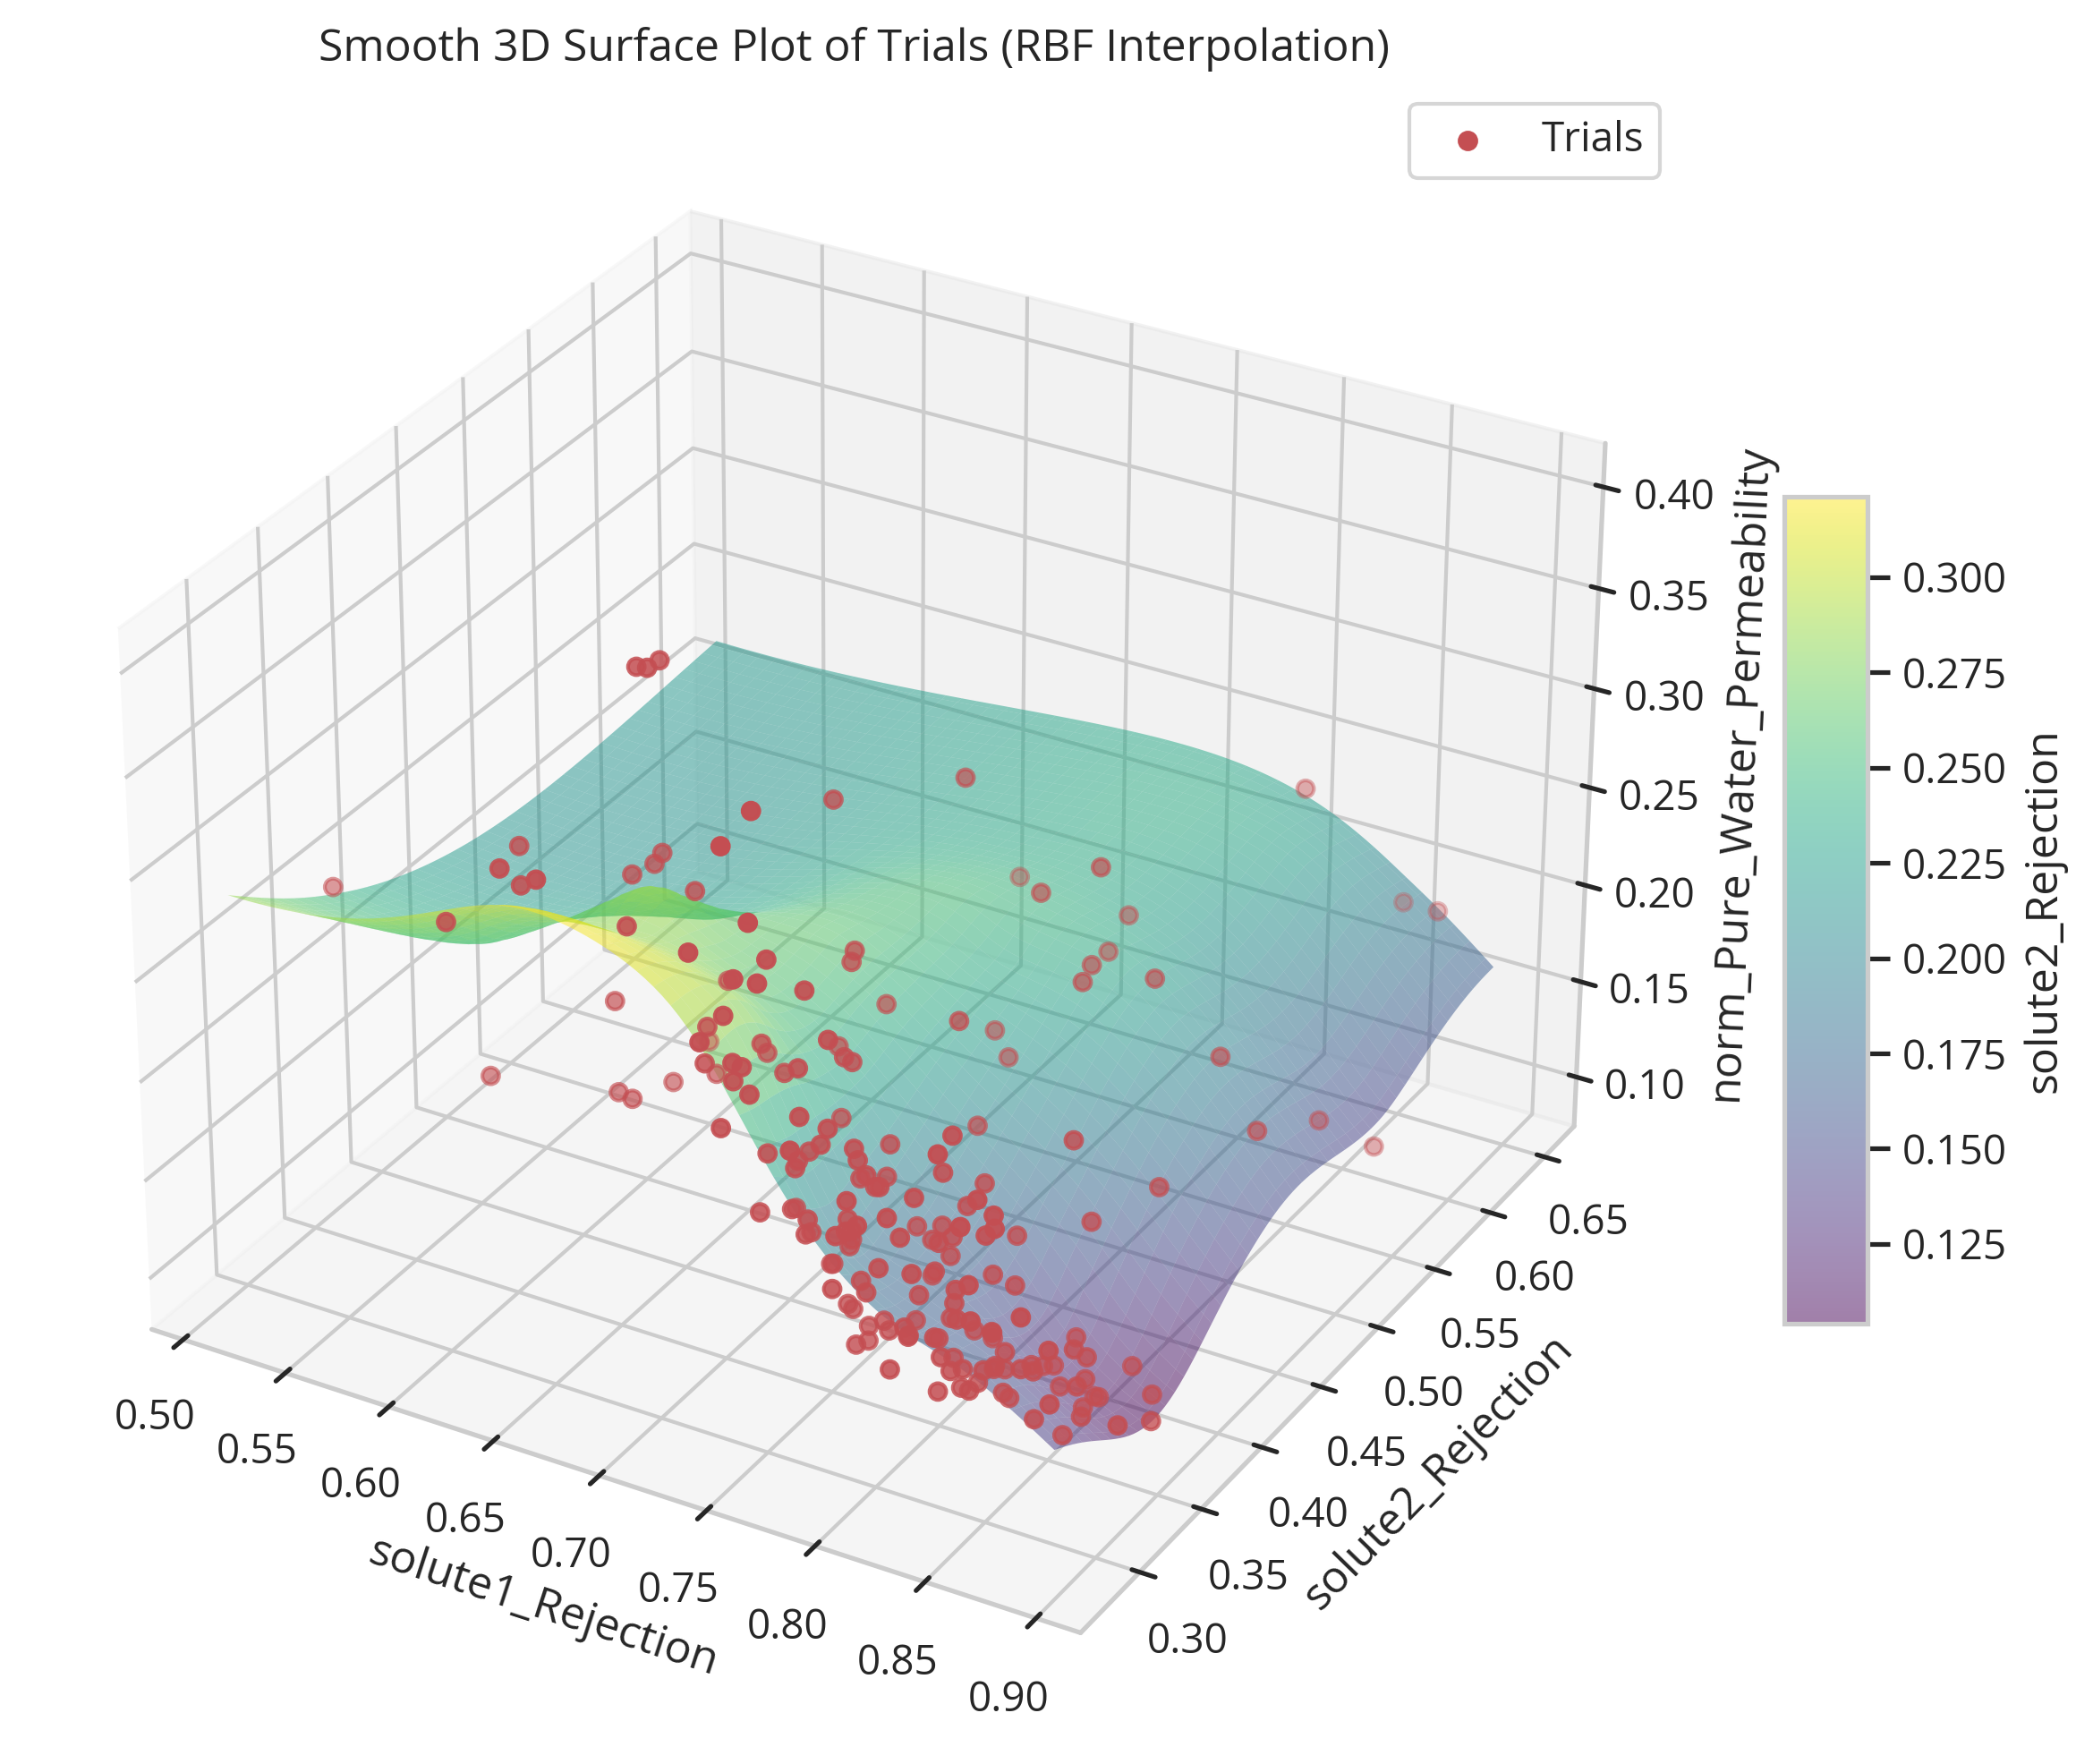

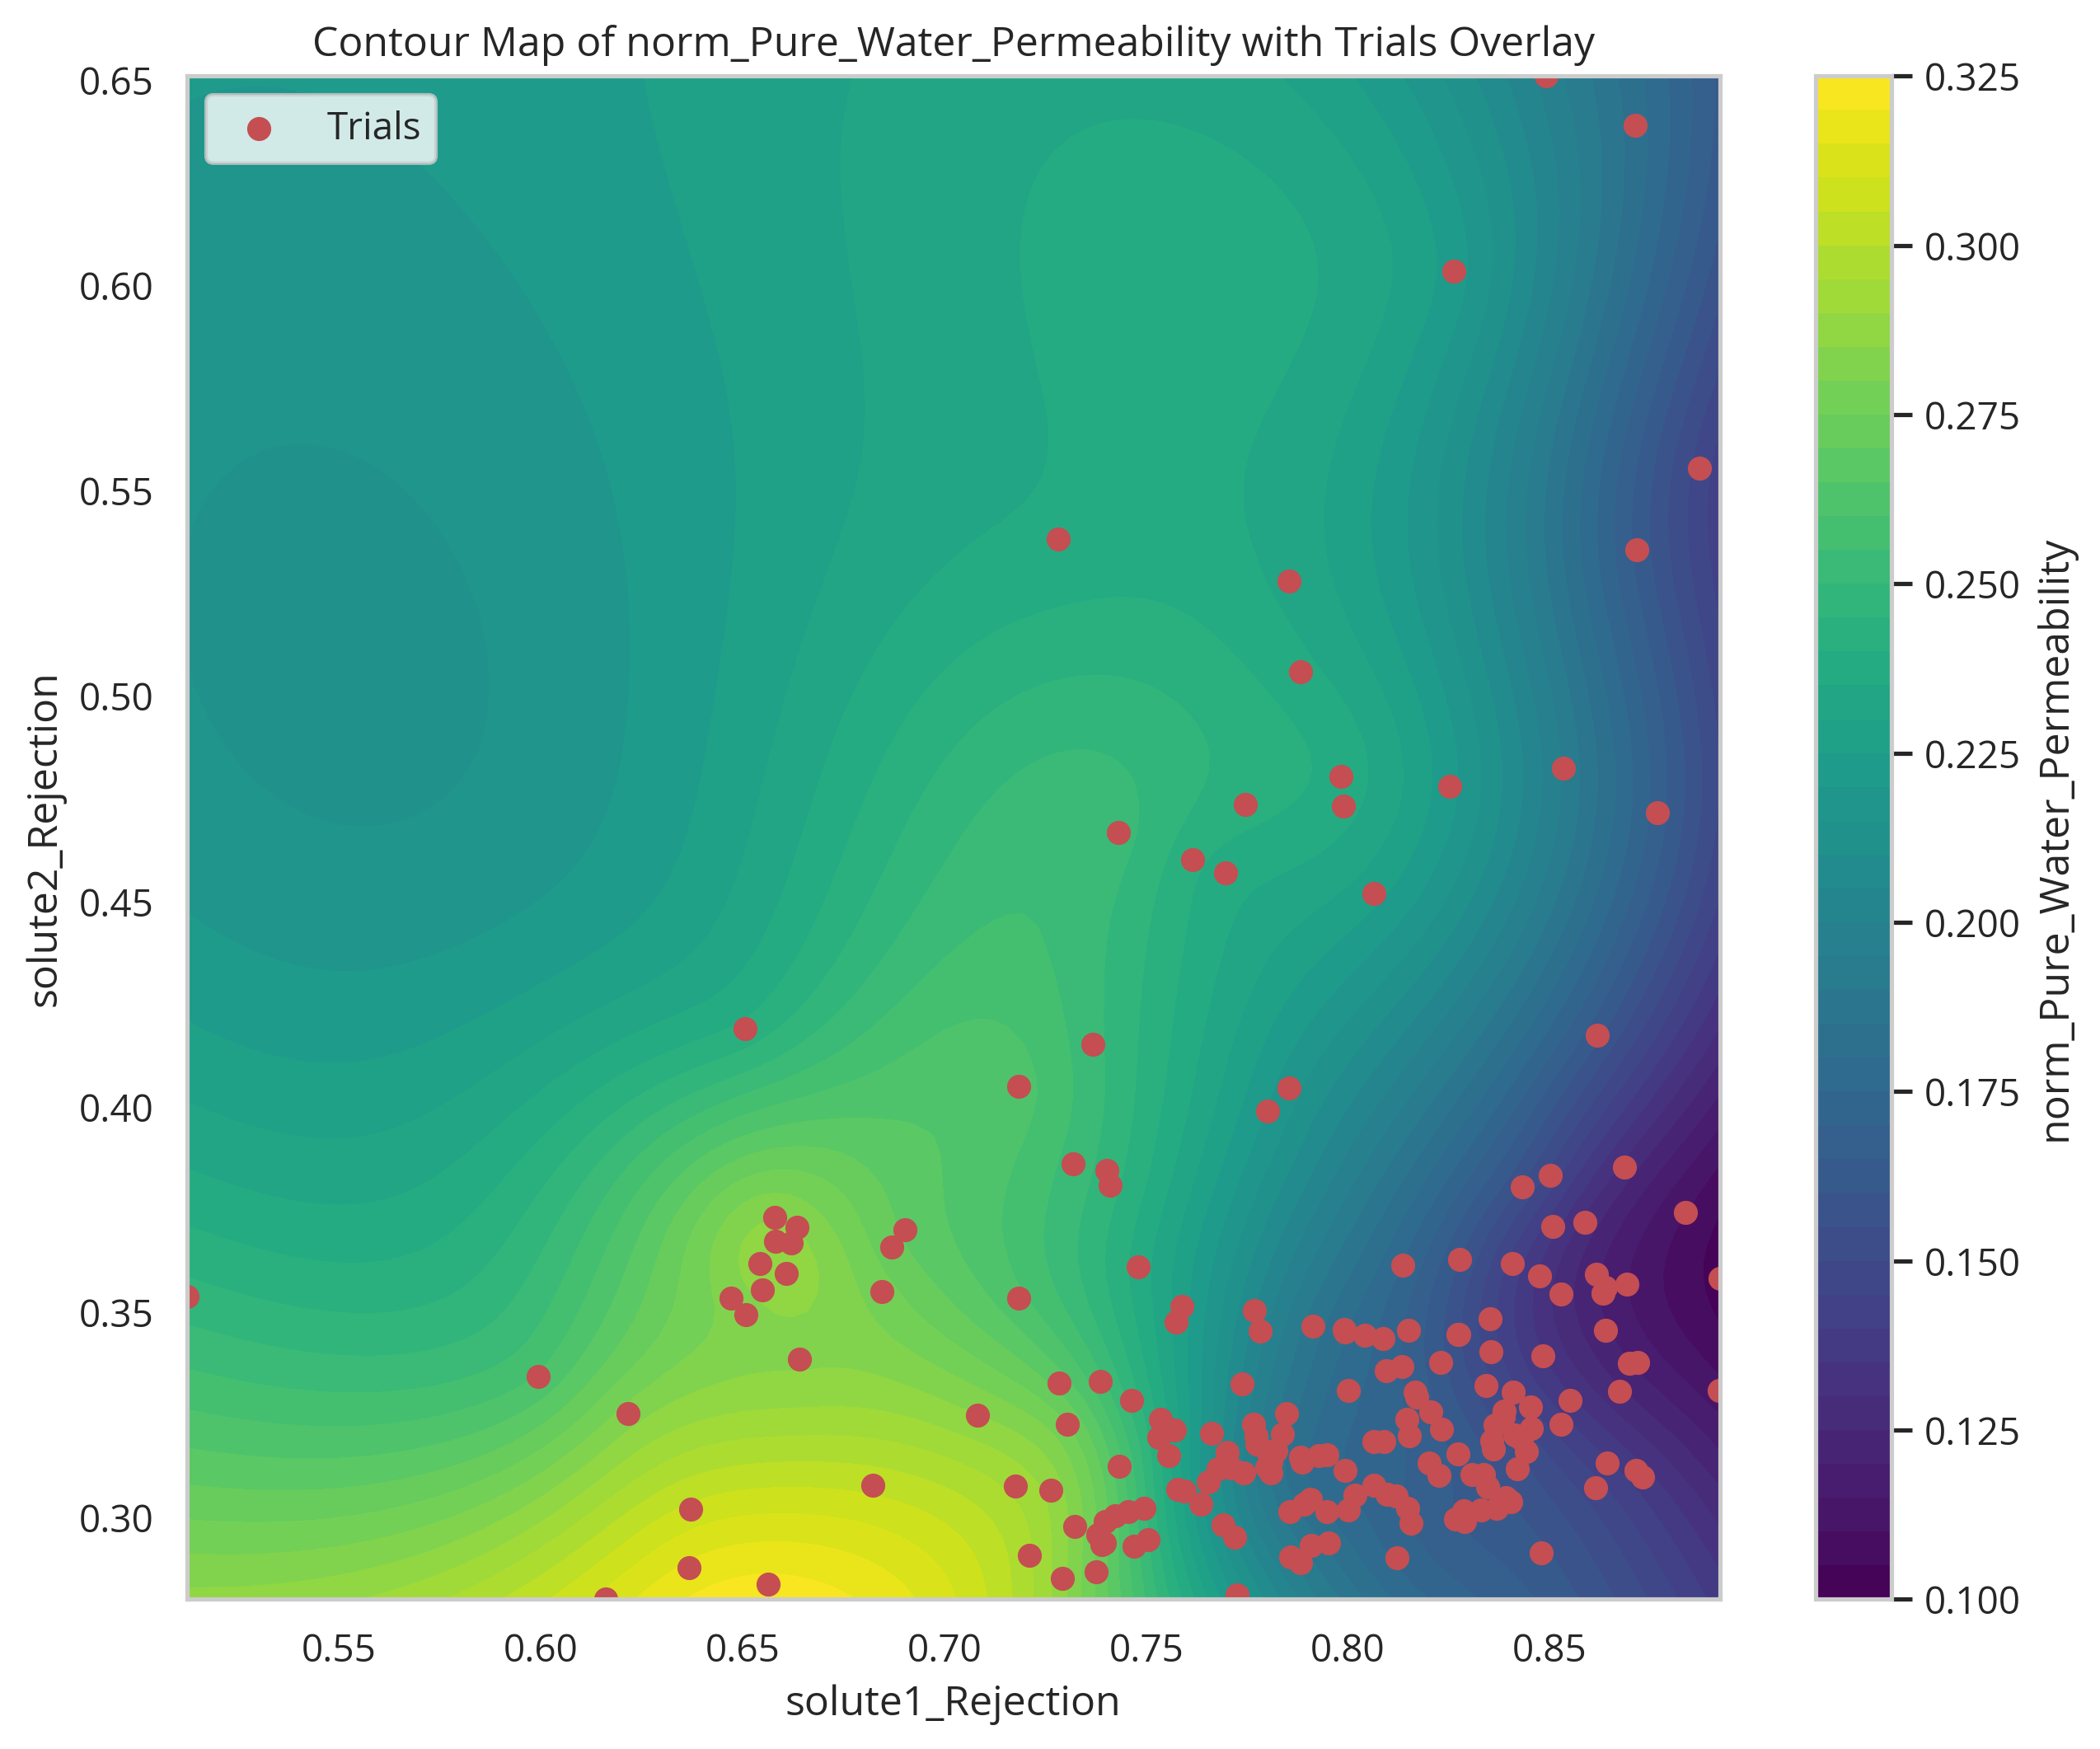

In [75]:
from scipy.interpolate import RBFInterpolator

# remove rows with NaN values in any of the relevant columns
trial_df = trial_df.dropna(subset=['norm_Pure_Water_Permeability', 'solute1_Rejection', 'solute2_Rejection'])

# Extract your data columns as numpy arrays
x = trial_df['solute1_Rejection'].values
y = trial_df['solute2_Rejection'].values 
z = trial_df['norm_Pure_Water_Permeability'].values

# Define the grid for interpolation based on median-scaled limits
x_min=np.min(x)  # or 0.6, depending on your desired range
x_max=np.max(x)  # or 0.9, depending on your desired range
y_min = np.min(y)  # Since we want to flip the y-axis for better visualization
y_max = np.max(y)

xi = np.linspace(x_min, x_max, 100)
yi = np.linspace(y_min, y_max, 100)
X, Y = np.meshgrid(xi, yi)

# Prepare points for RBFInterpolator ??it expects shape (n_points, n_dims)
points = np.column_stack((x, y))

# Create the RBF interpolator using a smooth radial basis function  
rbf = RBFInterpolator(points, z, kernel='thin_plate_spline', smoothing=0.01)

# Interpolate on the grid points, also reshaped to (m*n, 2)
grid_points = np.column_stack((X.ravel(), Y.ravel()))
Z = rbf(grid_points).reshape(X.shape)

# Plotting
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the 3D surface
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.5)

# Overlay original data points
ax.scatter(x, y, z, c='r', marker='o', label='Trials')

# Axis labels and title
ax.set_xlabel('solute1_Rejection')
ax.set_ylabel('solute2_Rejection')
ax.set_zlabel('norm_Pure_Water_Permeability')
ax.set_title('Smooth 3D Surface Plot of Trials (RBF Interpolation)')

# Set axes limits
# ax.set_xlim([0.81, 0.85])
# ax.set_ylim([y_min, y_max])
# ax.set_zlim([0.1, 0.25])

ax.legend()
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='solute2_Rejection')

plt.show()

# plot a contour map of the 3D surface
plt.figure(figsize=(10, 8))
contour = plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(contour, label='norm_Pure_Water_Permeability')
plt.scatter(x, y, c='r', marker='o', label='Trials')
plt.xlabel('solute1_Rejection')
plt.ylabel('solute2_Rejection')
plt.title('Contour Map of norm_Pure_Water_Permeability with Trials Overlay')
plt.xlim([x_min, x_max])
plt.ylim([y_min, y_max])
plt.legend()


In [ ]:
src_ax_path = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))
if src_ax_path not in sys.path:
    sys.path.insert(0, src_ax_path)
from utl_Ax import build_frontier_dataframe

print("Pareto Frontier:")
frontier_df = build_frontier_dataframe(client, use_model_predictions=False)
FRONTIER_PATH = os.path.join(SAVE_DIR, "inverse_design_files", VERSION, f"{OBJECTIVE_NAME}_frontier.csv")
frontier_df.to_csv(FRONTIER_PATH, index=False)
display(frontier_df)

Pareto Frontier:


,Sup_Membrane_Material,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Polymerization_Time_min,Dope2_Monomer1_Name,Dope2_Monomer1_Mass,Dope2_Solvent1_Name,Dope2_Polymerization_Time_min,Heat_Treatment_Temp_degC,Heat_Treatment_Time_min,Mem_Compaction_Pressure_bar,Mem_Compaction_Time_hr,Water_Permeation_Pressure_bar,norm_Pure_Water_Permeability,solute1_Rejection,solute2_Rejection
0,PSF,PEI,0.008321,PEG,0.000317,2.402827,TMC,0.001584,n-Hexane,1.620172,35.860438,1.775147,10.000000,2.396291,4.981047,0.160491,0.871465,0.312091
1,PSF,PEI,0.007271,SLS,0.000306,12.861251,TMC,0.001489,Toluene,6.233449,55.039862,8.063427,5.970382,2.349789,5.244795,0.118500,0.891860,0.330820
2,PSF,PEI,0.006856,SLS,0.000350,10.152702,CFIC,0.002500,Toluene,2.013379,64.608004,5.903420,5.412847,4.140201,5.220375,0.135410,0.873149,0.309843
3,PSF,PIP,0.010000,SLS,0.000288,2.000000,TMC,0.001500,n-Hexane,0.500000,70.000000,2.000000,5.000000,3.000000,5.000000,0.085380,0.970797,0.364128
4,PSF,PIP,0.002000,SLS,0.000288,2.000000,TMC,0.001500,n-Hexane,0.500000,70.000000,2.000000,5.000000,3.000000,5.000000,0.178614,0.860492,0.290365
5,PSF,PEI,0.012898,PEG,0.000286,16.259353,CFIC,0.002500,n-Hexane,9.783225,36.286662,1.000000,4.448930,1.991047,5.047287,0.176244,0.861316,0.307242
6,PSF,PIP,0.010004,SLS,0.000285,17.462463,TMC,0.000901,Toluene,7.745747,63.315688,5.342256,6.207750,3.812508,5.781136,0.103802,0.891913,0.357605


## Overlay with Frontier points, contour map represents only frontier points

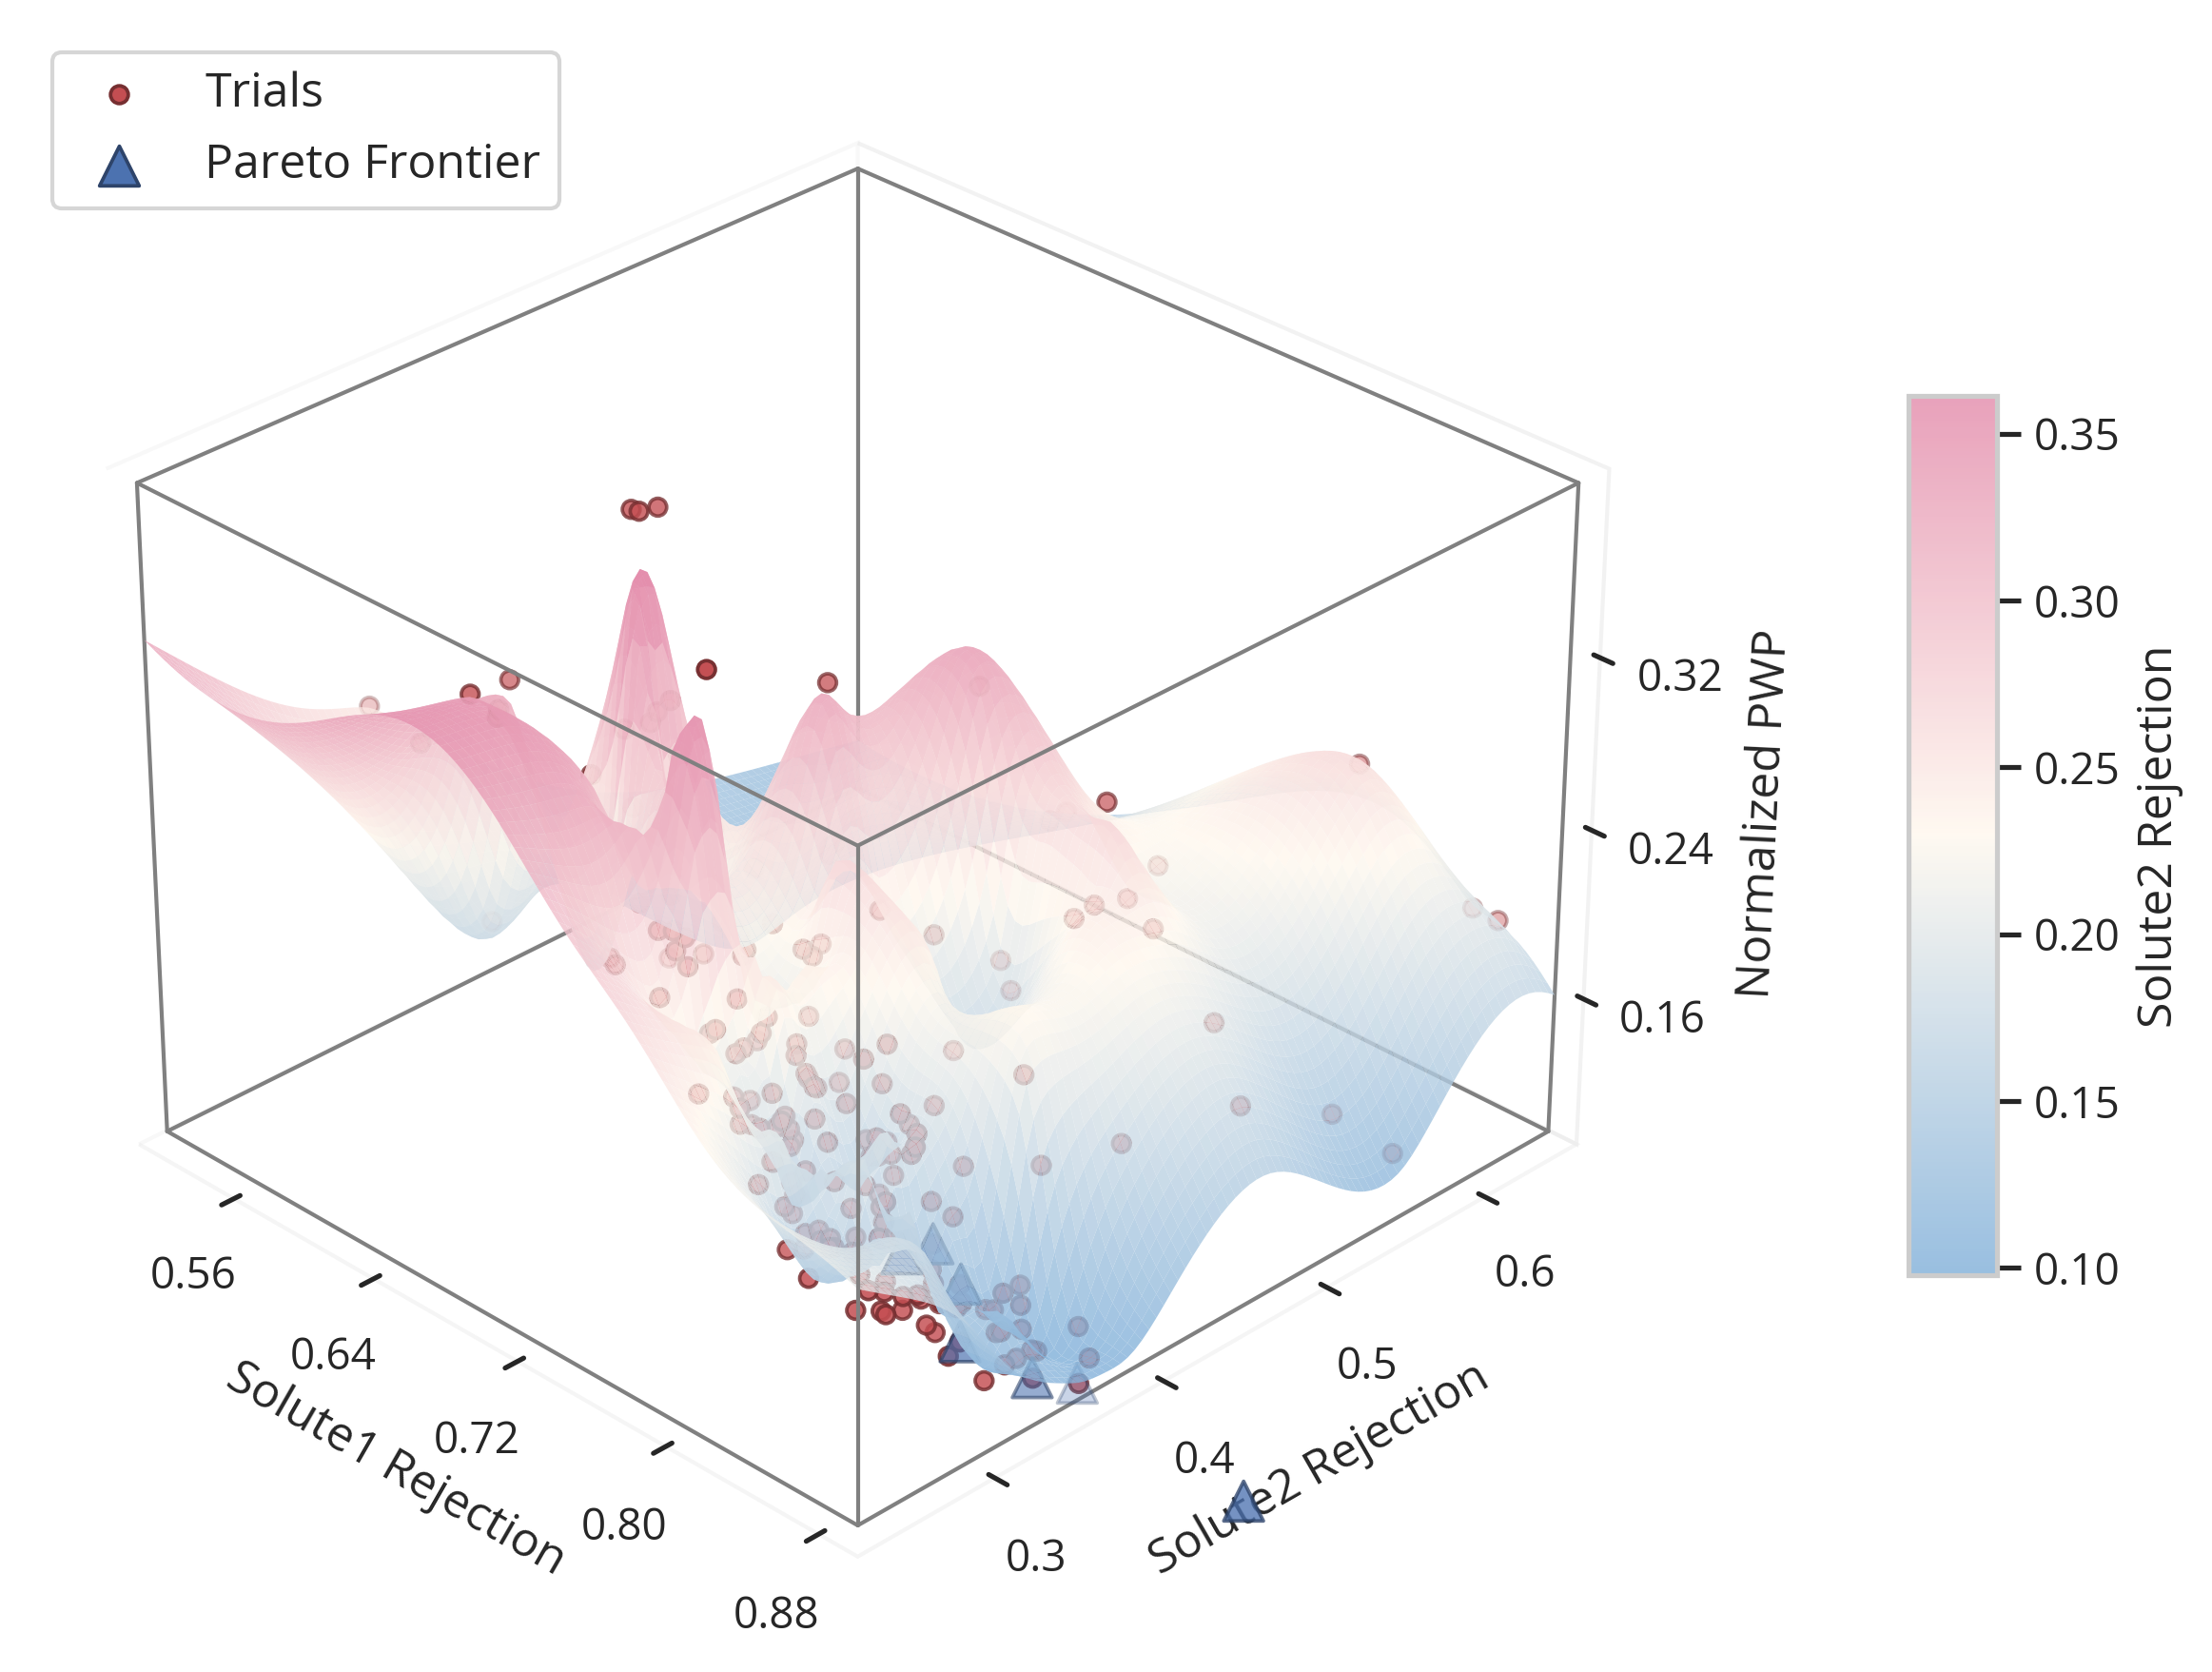

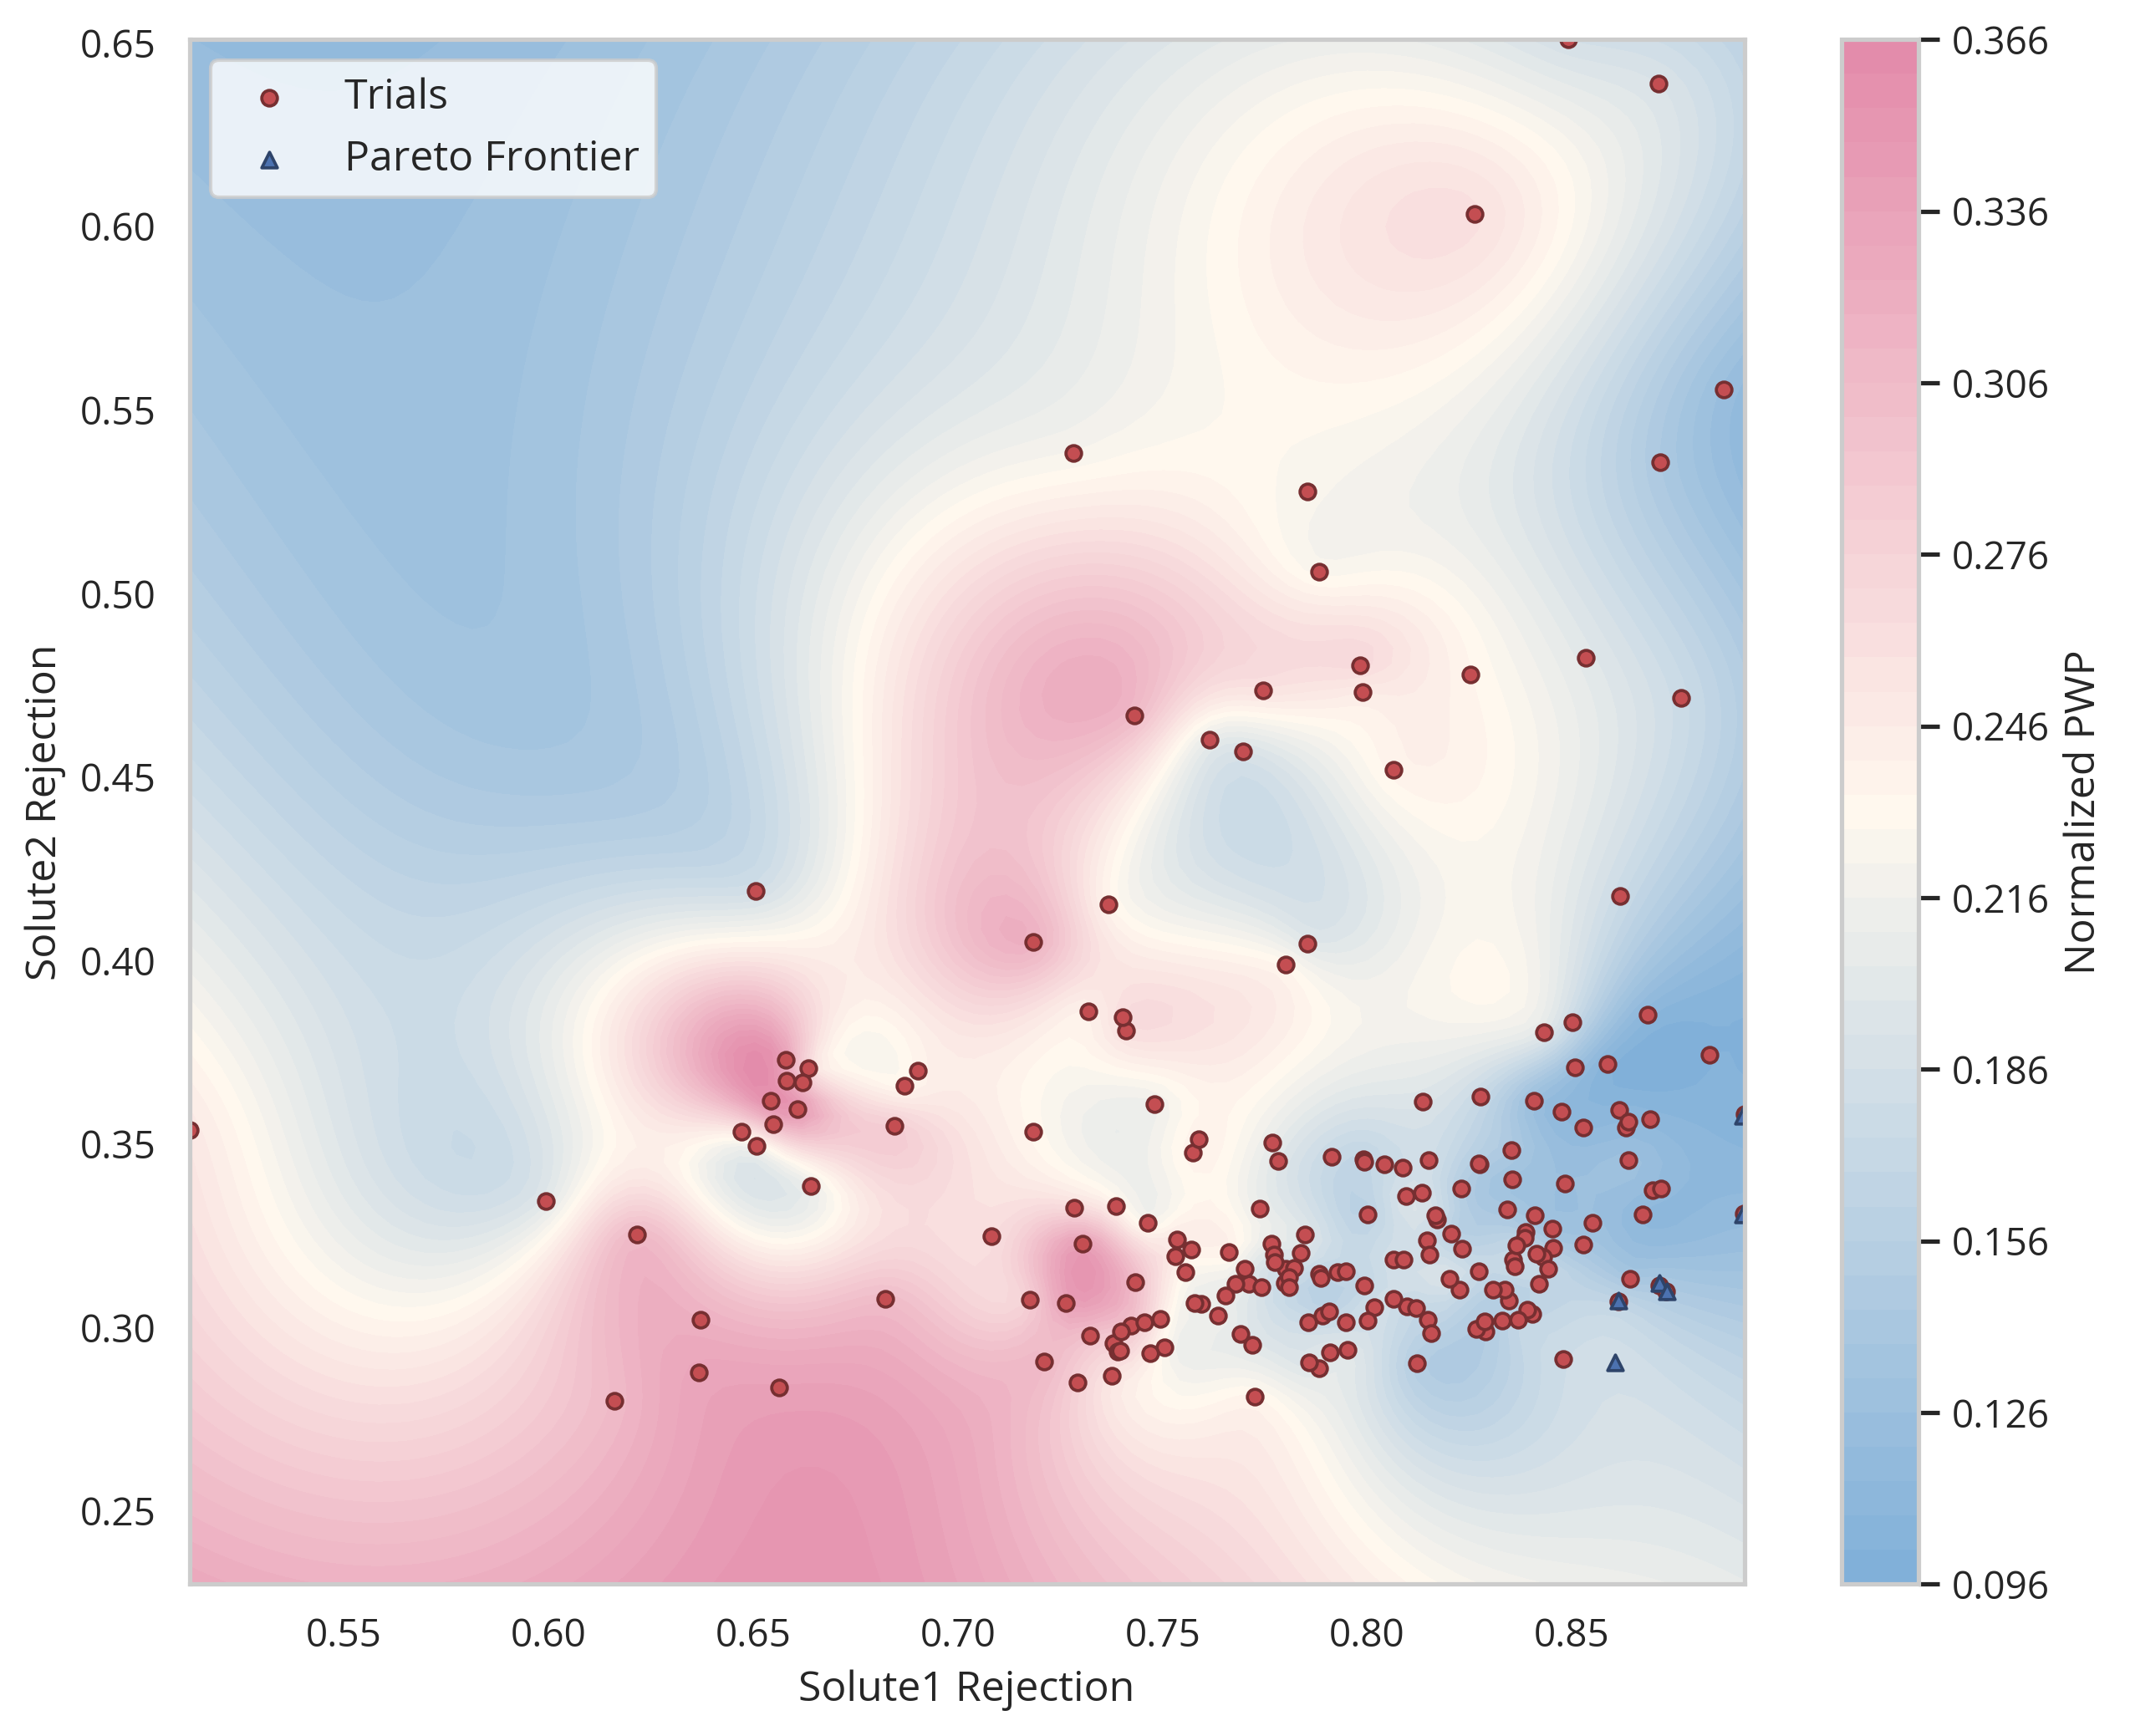

In [ ]:
src_ax_path = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))
if src_ax_path not in sys.path:
    sys.path.insert(0, src_ax_path)
from utl_Ax import build_rbf_surface, plot_inverse_design_surface, plot_inverse_design_contour

trial_df = trial_df.dropna(subset=['norm_Pure_Water_Permeability', 'solute1_Rejection', 'solute2_Rejection'])
surface_data = build_rbf_surface(
    trial_df,
    x_col='solute1_Rejection',
    y_col='solute2_Rejection',
    z_col='norm_Pure_Water_Permeability',
    smoothing=0.0001,
    y_padding=0.05,
)

x = surface_data['x']
y = surface_data['y']
z = surface_data['z']
points = surface_data['points']
rbf = surface_data['rbf']
X = surface_data['X']
Y = surface_data['Y']
Z = surface_data['Z']
x_min = surface_data['x_min']
x_max = surface_data['x_max']
y_min = surface_data['y_min']
y_max = surface_data['y_max']

plot_inverse_design_surface(
    surface_data,
    x_col='solute1_Rejection',
    y_col='solute2_Rejection',
    z_col='norm_Pure_Water_Permeability',
    frontier_df=frontier_df,
    cmap=custom_cmap,
    trial_color='r',
    frontier_color='b',
    marker_size=100,
    elev=ELEV3D,
    azim=AZIM3D,
    y_padding=0.05,
)

plot_inverse_design_contour(
    surface_data,
    x_col='solute1_Rejection',
    y_col='solute2_Rejection',
    z_col='norm_Pure_Water_Permeability',
    frontier_df=frontier_df,
    cmap=custom_cmap,
    trial_color='r',
    frontier_color='b',
    marker_size=MARKER_SIZE,
    y_padding=0.05,
)

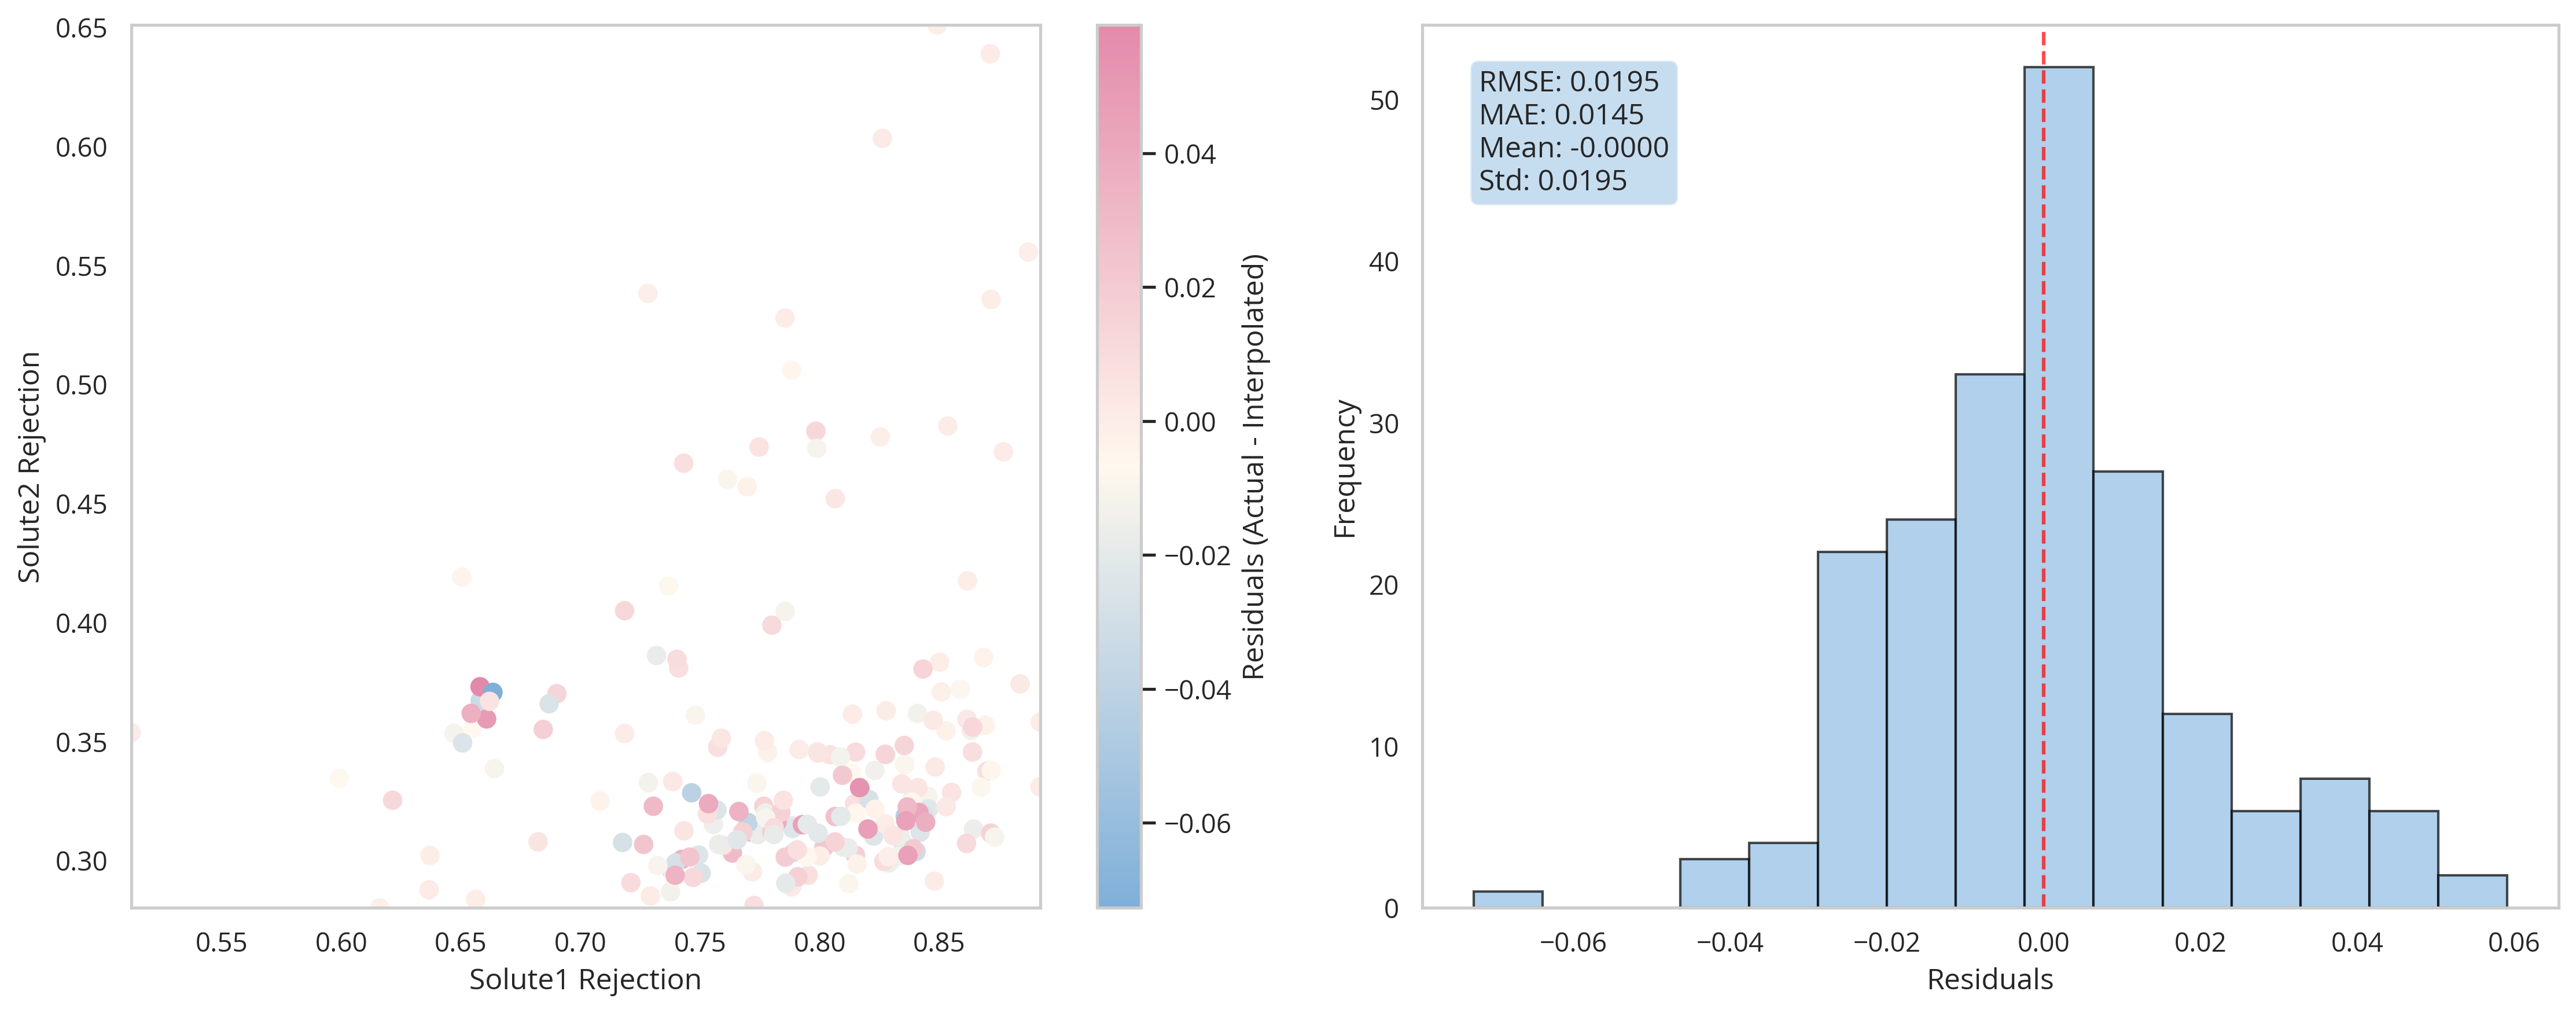

In [102]:
# Plot residuals of RBF interpolation
# Calculate interpolated values at the original data points
interpolated_at_data = rbf(points)
residuals = z - interpolated_at_data

# Create residual plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Residuals scatter plot
scatter = ax1.scatter(x, y, c=residuals, cmap=custom_cmap, s=50)
ax1.set_xlabel('Solute1 Rejection')
ax1.set_ylabel('Solute2 Rejection')
# ax1.set_title('norm_Pure_Water_Permeability Residuals of RBF Interpolation')
ax1.set_xlim([x_min, x_max])
ax1.set_ylim([y_min, y_max])
ax1.grid(False)
plt.colorbar(scatter, ax=ax1, label='Residuals (Actual - Interpolated)')

# Residuals histogram
ax2.hist(residuals, color = "#8fbce3", bins=15, alpha=0.7, edgecolor='black')
ax2.set_xlabel('Residuals')
ax2.set_ylabel('Frequency')
# ax2.set_title('Distribution of RBF Interpolation Residuals')
ax2.axvline(x=0, color='red', linestyle='--', alpha=0.7)
ax2.grid(False)

# Add statistics
rmse = np.sqrt(np.mean(residuals**2))
mae = np.mean(np.abs(residuals))
ax2.text(0.05, 0.95, f'RMSE: {rmse:.4f}\nMAE: {mae:.4f}\nMean: {np.mean(residuals):.4f}\nStd: {np.std(residuals):.4f}', 
         transform=ax2.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='#8fbce3', alpha=0.5))

plt.tight_layout()
plt.show()

# Overlay with Trial and Error data

In [63]:
# Overlay with trial and error data
TANDE_PATH = os.path.join(INPUT_PATH, "TandE_data.xlsx")
tande_df = pd.read_excel(TANDE_PATH)

In [64]:
# keep only the common objective columns
cols = ["norm_Pure_Water_Permeability", "solute1_Rejection", "solute2_Rejection"]
trial_only_df_ = trial_df[cols].copy()
frontier_df_ = frontier_df[cols].copy()
tande_df_ = tande_df[cols].copy()

# # optional: tag source of each row
# trial_only_df_["data_source"] = "trial"
# frontier_df_["data_source"] = "frontier"
# tande_df_["data_source"] = "tande"

all_df = pd.concat([trial_only_df_, frontier_df_, tande_df_], ignore_index=True, sort=False)
all_df

,norm_Pure_Water_Permeability,solute1_Rejection,solute2_Rejection
0,0.143552,0.871602,0.535618
1,0.328857,0.718440,0.404881
2,0.200731,0.664048,0.338578
3,0.240334,0.806458,0.451932
4,0.197193,0.761450,0.460103
...,...,...,...
307,0.042016,0.939718,0.534157
308,0.062821,0.916686,0.559552
309,0.027568,0.966667,0.581516
310,0.051263,0.926608,0.470378


In [65]:
# find the maximum and minimum of each column for later use in normalization
norm_cols = ["norm_Pure_Water_Permeability", "solute1_Rejection", "solute2_Rejection"]
col_mins = all_df[norm_cols].min()  
col_maxs = all_df[norm_cols].max()
print ("Column minimums:\n", col_mins)
print ("Column maximums:\n", col_maxs)

Column minimums:
 norm_Pure_Water_Permeability    0.026412
solute1_Rejection               0.512203
solute2_Rejection               0.169292
dtype: float64
Column maximums:
 norm_Pure_Water_Permeability    0.399219
solute1_Rejection               0.992215
solute2_Rejection               0.907156
dtype: float64


x_range: (0.5122031093, 0.9922146507666099)
y_range: (0.16929177049540012, 0.9071564188695779)
z_range: (0.02641233781744576, 0.3992187029)


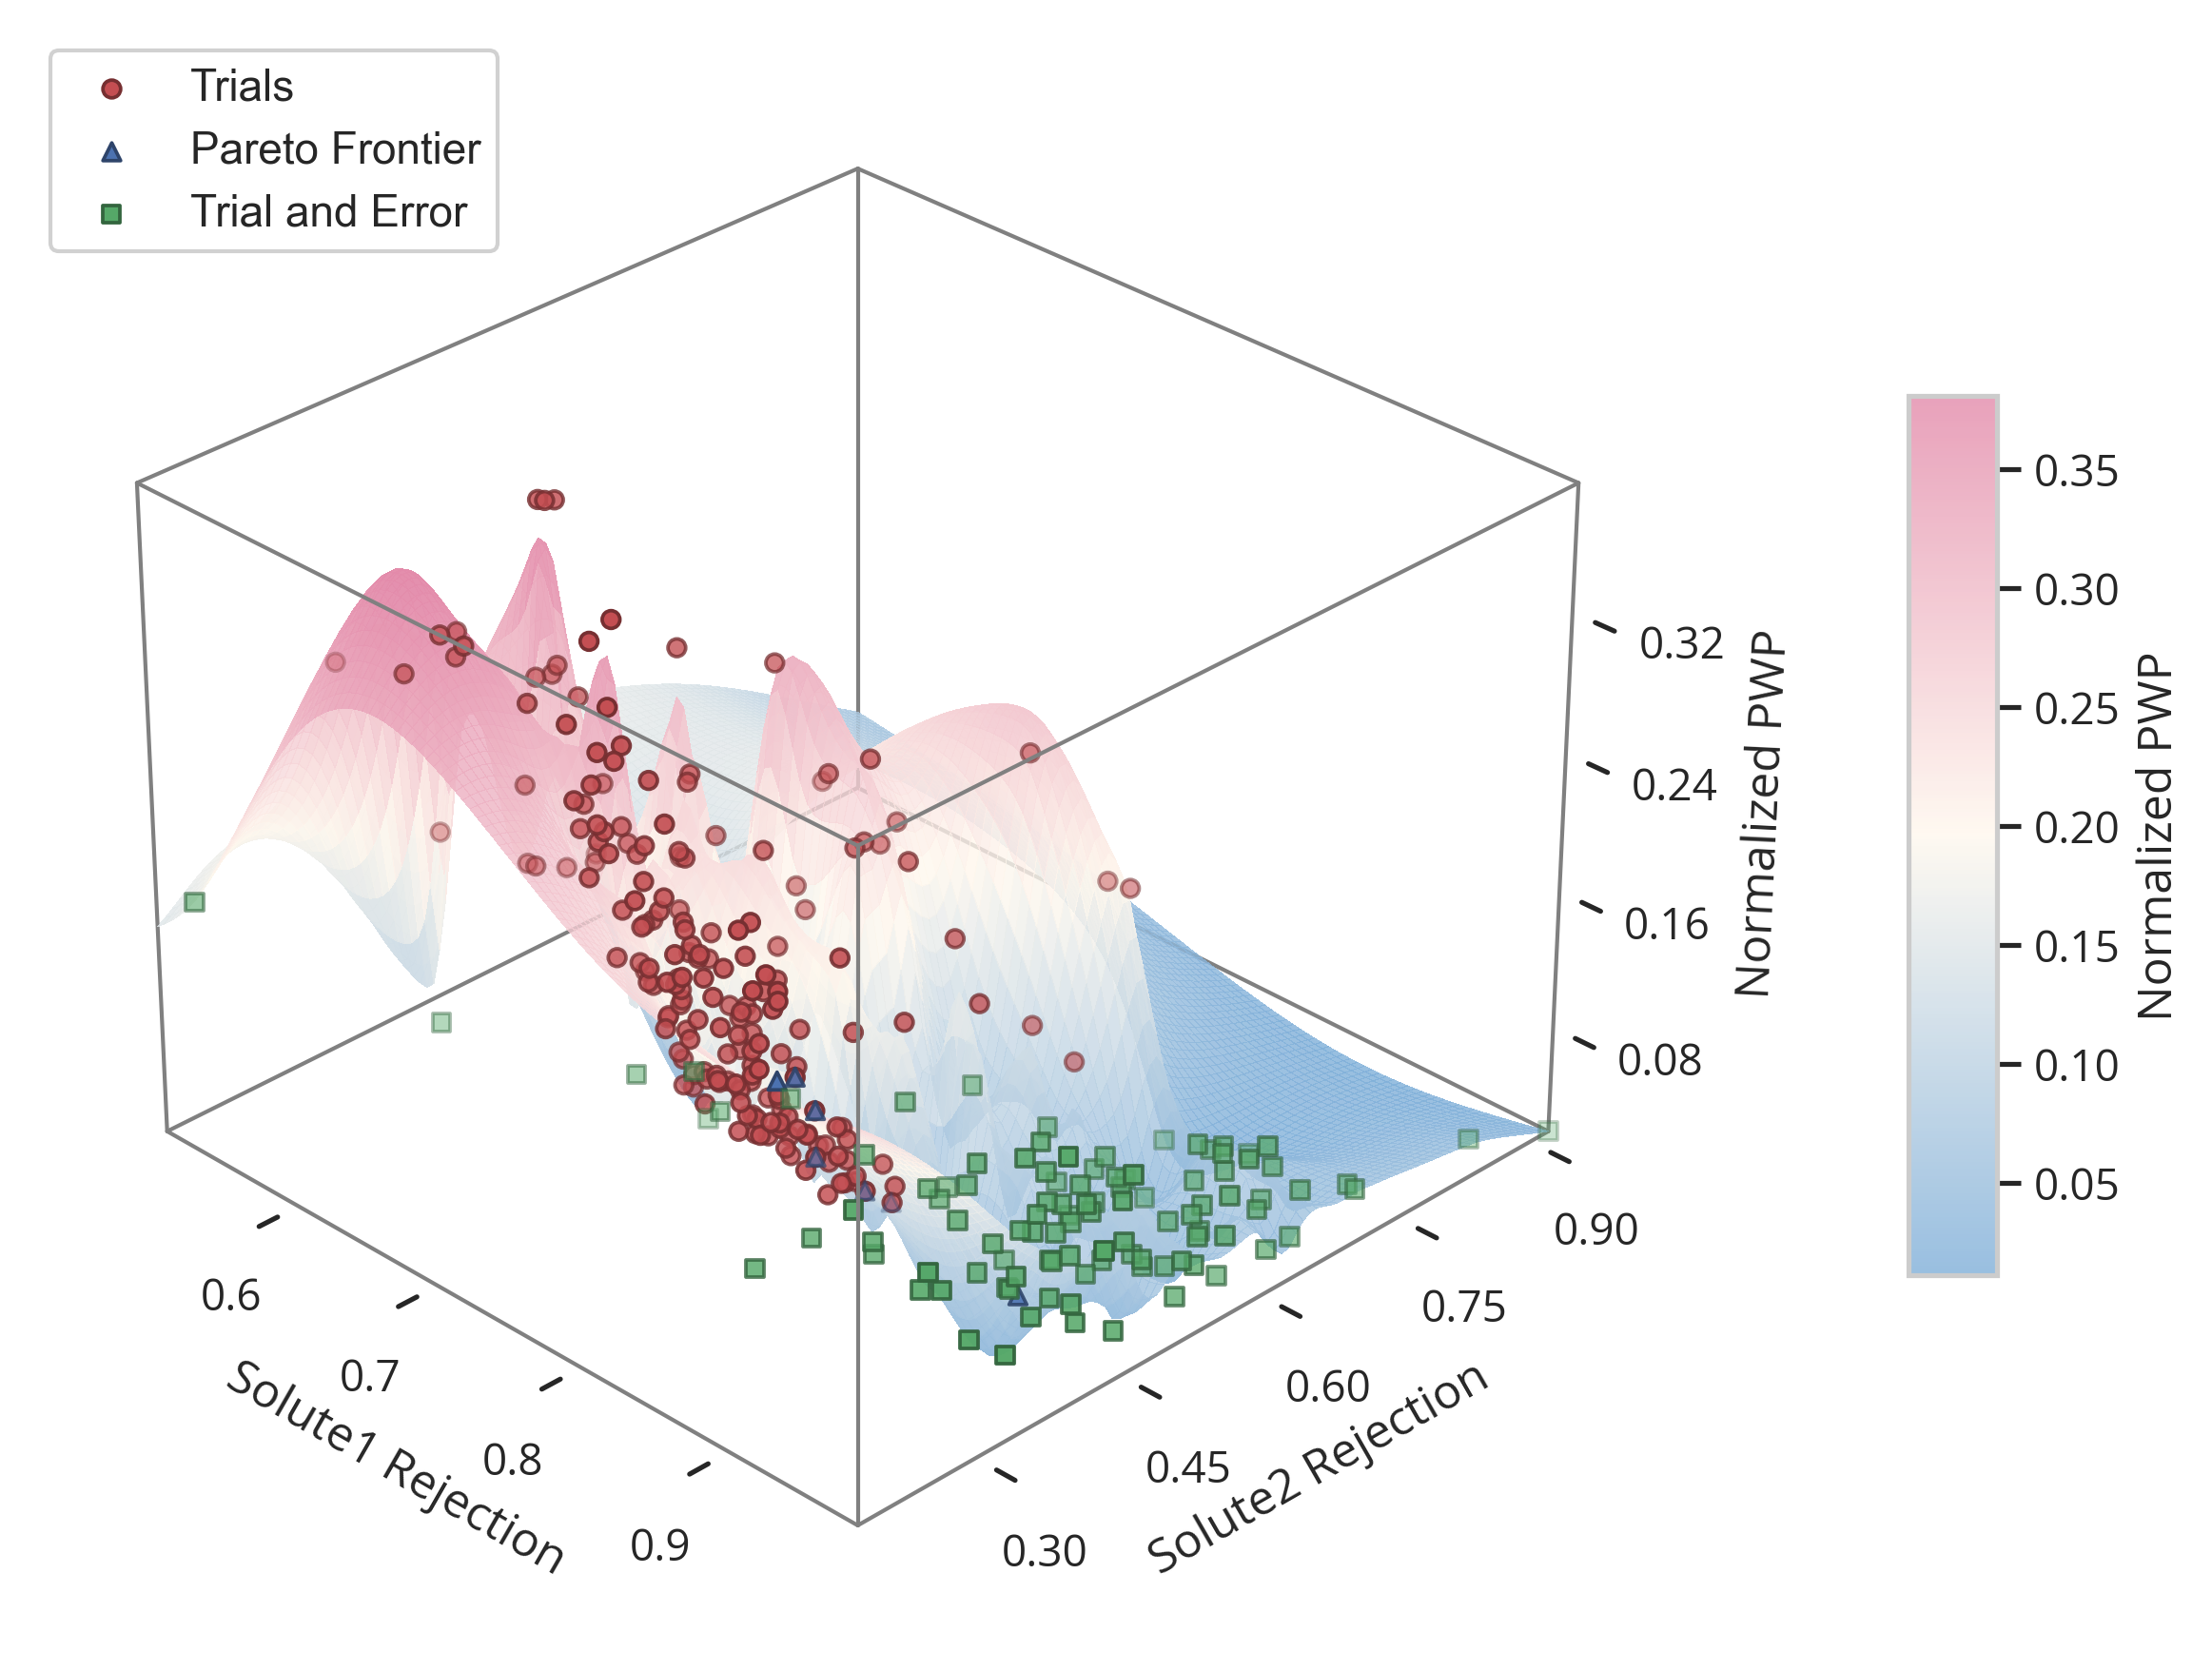

In [98]:
# Extract your data columns as numpy arrays

# All data points
x = all_df["solute1_Rejection"].values
y = all_df["solute2_Rejection"].values
z = all_df["norm_Pure_Water_Permeability"].values

# Trial points 
x_trial = trial_only_df_["solute1_Rejection"].values
y_trial = trial_only_df_["solute2_Rejection"].values 
z_trial = trial_only_df_["norm_Pure_Water_Permeability"].values

# Frontier points
x_front = frontier_df["solute1_Rejection"].values
y_front = frontier_df["solute2_Rejection"].values
z_front = frontier_df["norm_Pure_Water_Permeability"].values

# TandE points
x_tande = tande_df["solute1_Rejection"].values
y_tande = tande_df["solute2_Rejection"].values
z_tande = tande_df["norm_Pure_Water_Permeability"].values

## Plot setting

# Plotting
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.computed_zorder = False  # Respect manual zorder for front/back frame edges
from mpl_toolkits.mplot3d.art3d import Line3D


## Axes settings
# Set axes line width to 0 to hide them, since we will draw custom edges later
ax.xaxis.line.set_linewidth(0)
ax.yaxis.line.set_linewidth(0)
ax.zaxis.line.set_linewidth(0)
# Axis labels and title
ax.set_xlabel('Solute1 Rejection')
ax.set_ylabel('Solute2 Rejection')
ax.set_zlabel('Normalized PWP')
# ax.set_title('Smooth 3D Surface Plot of Trials (RBF Interpolation)')
# Set axes limits to the data range with some padding for better visualization
ax.set_xlim([np.min(x), np.max(x)])
ax.set_ylim([np.min(y), np.max(y)])
ax.set_zlim([np.min(z), np.max(z)])
# ax.set_xlim([0.81, 0.85])
# ax.set_ylim([y_min-0.05, y_max])
# ax.set_zlim([0.026412, 0.25])
ax.view_init(elev=ELEV3D, azim=AZIM3D)
# Axes ticks and grid
ax.xaxis.set_major_locator(MaxNLocator(nbins=5))  
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))  
ax.zaxis.set_major_locator(MaxNLocator(nbins=5))  
ax.grid(False)  # Remove grid lines for a cleaner look
# Remove grid background for a cleaner look
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
# Remove grid background for a cleaner look
ax.xaxis.pane.set_edgecolor((0, 0, 0, 0))
ax.yaxis.pane.set_edgecolor((0, 0, 0, 0))
ax.zaxis.pane.set_edgecolor((0, 0, 0, 0))
ax.xaxis.pane.set_linewidth(0)
ax.yaxis.pane.set_linewidth(0)
ax.zaxis.pane.set_linewidth(0)
# Set axes line width to 0 to hide them, since we will draw custom edges later
ax.xaxis.line.set_linewidth(0)
ax.yaxis.line.set_linewidth(0)
ax.zaxis.line.set_linewidth(0)


# Define the grid for interpolation based on median-scaled limits
x_range = ax.get_xlim()
y_range = ax.get_ylim()
z_range = ax.get_zlim()
x_min=x_range[0]
x_max=x_range[1]
y_min=y_range[0]
y_max=y_range[1]
z_min=z_range[0]
z_max=z_range[1]
print(f"x_range: {x_range}")
print(f"y_range: {y_range}")
print(f"z_range: {z_range}")


## RBF interpolation and plotting
xi = np.linspace(x_min, x_max, 100)
yi = np.linspace(y_min, y_max, 100)
X, Y = np.meshgrid(xi, yi)
# Prepare points for RBFInterpolator ??it expects shape (n_points, n_dims)
points = np.column_stack((x, y))
# Create the RBF interpolator using a smooth radial basis function  
rbf = RBFInterpolator(points, z, kernel='thin_plate_spline', smoothing=0.0001)
# Interpolate on the grid points, also reshaped to (m*n, 2)
grid_points = np.column_stack((X.ravel(), Y.ravel()))
Z = rbf(grid_points).reshape(X.shape)

# Plot the 3D surface
surf = ax.plot_surface(X, Y, Z, cmap=custom_cmap, edgecolor='none', alpha=0.8,rstride=1, cstride=1, shade=True, antialiased=False)

trial_color = 'r'
frontier_color = 'b'
tande_color = 'g'

# Overlay original data points
ax.scatter(
    x_trial, y_trial, z_trial,
    c=trial_color, marker='o', s=MARKER_SIZE, label='Trials',
    edgecolors=[darker_color(trial_color)], linewidths=0.9
)
# Overlay Pareto frontier points
ax.scatter(
    x_front, y_front, z_front,
    c=frontier_color, marker='^', s=MARKER_SIZE, label='Pareto Frontier',
    edgecolors=[darker_color(frontier_color)], linewidths=0.9
)
# Overlay TandE points
ax.scatter(
    x_tande, y_tande, z_tande,
    c=tande_color, marker='s', s=MARKER_SIZE, label='Trial and Error',
    edgecolors=[darker_color(tande_color)], linewidths=0.9
)

# ## Custom box edges split into back and front layers
back_edges = [
    ([x_range[0], x_range[1]], [y_range[1], y_range[1]], [z_range[0], z_range[0]]),
    ([x_range[0], x_range[1]], [y_range[1], y_range[1]], [z_range[1], z_range[1]]),
    ([x_range[0], x_range[0]], [y_range[0], y_range[1]], [z_range[0], z_range[0]]),
    ([x_range[0], x_range[0]], [y_range[0], y_range[1]], [z_range[1], z_range[1]]),
    ([x_range[0], x_range[0]], [y_range[1], y_range[1]], [z_range[0], z_range[1]]),
    ([x_range[1], x_range[1]], [y_range[1], y_range[1]], [z_range[0], z_range[1]]),
    ([x_range[0], x_range[0]], [y_range[0], y_range[0]], [z_range[0], z_range[1]]),
    ([x_range[1], x_range[1]], [y_range[0], y_range[1]], [z_range[0], z_range[0]]),
    ([x_range[0], x_range[1]], [y_range[0], y_range[0]], [z_range[0], z_range[0]]),
]

front_edges = [
    ([x_range[0], x_range[1]], [y_range[0], y_range[0]], [z_range[1], z_range[1]]),
    ([x_range[1], x_range[1]], [y_range[0], y_range[0]], [z_range[0], z_range[1]]),
    ([x_range[1], x_range[1]], [y_range[0], y_range[1]], [z_range[1], z_range[1]]),
]

for edge in back_edges:
    line = Line3D(
        edge[0], edge[1], edge[2],
        color='gray', linewidth=1, alpha=1.0, zorder=-100
    )
    line.set_clip_on(False)
    ax.add_line(line)

for edge in front_edges:
    line = Line3D(
        edge[0], edge[1], edge[2],
        color='gray', linewidth=1, alpha=1.0, zorder=1000
    )
    line.set_clip_on(False)
    ax.add_line(line)

ax.legend(loc='upper left', fontsize=12, framealpha=0.9, prop={'family': 'Arial'})
fig.colorbar(surf, ax=ax, aspect=10, shrink=0.5, pad=0.12, label='Normalized PWP')

plt.show()


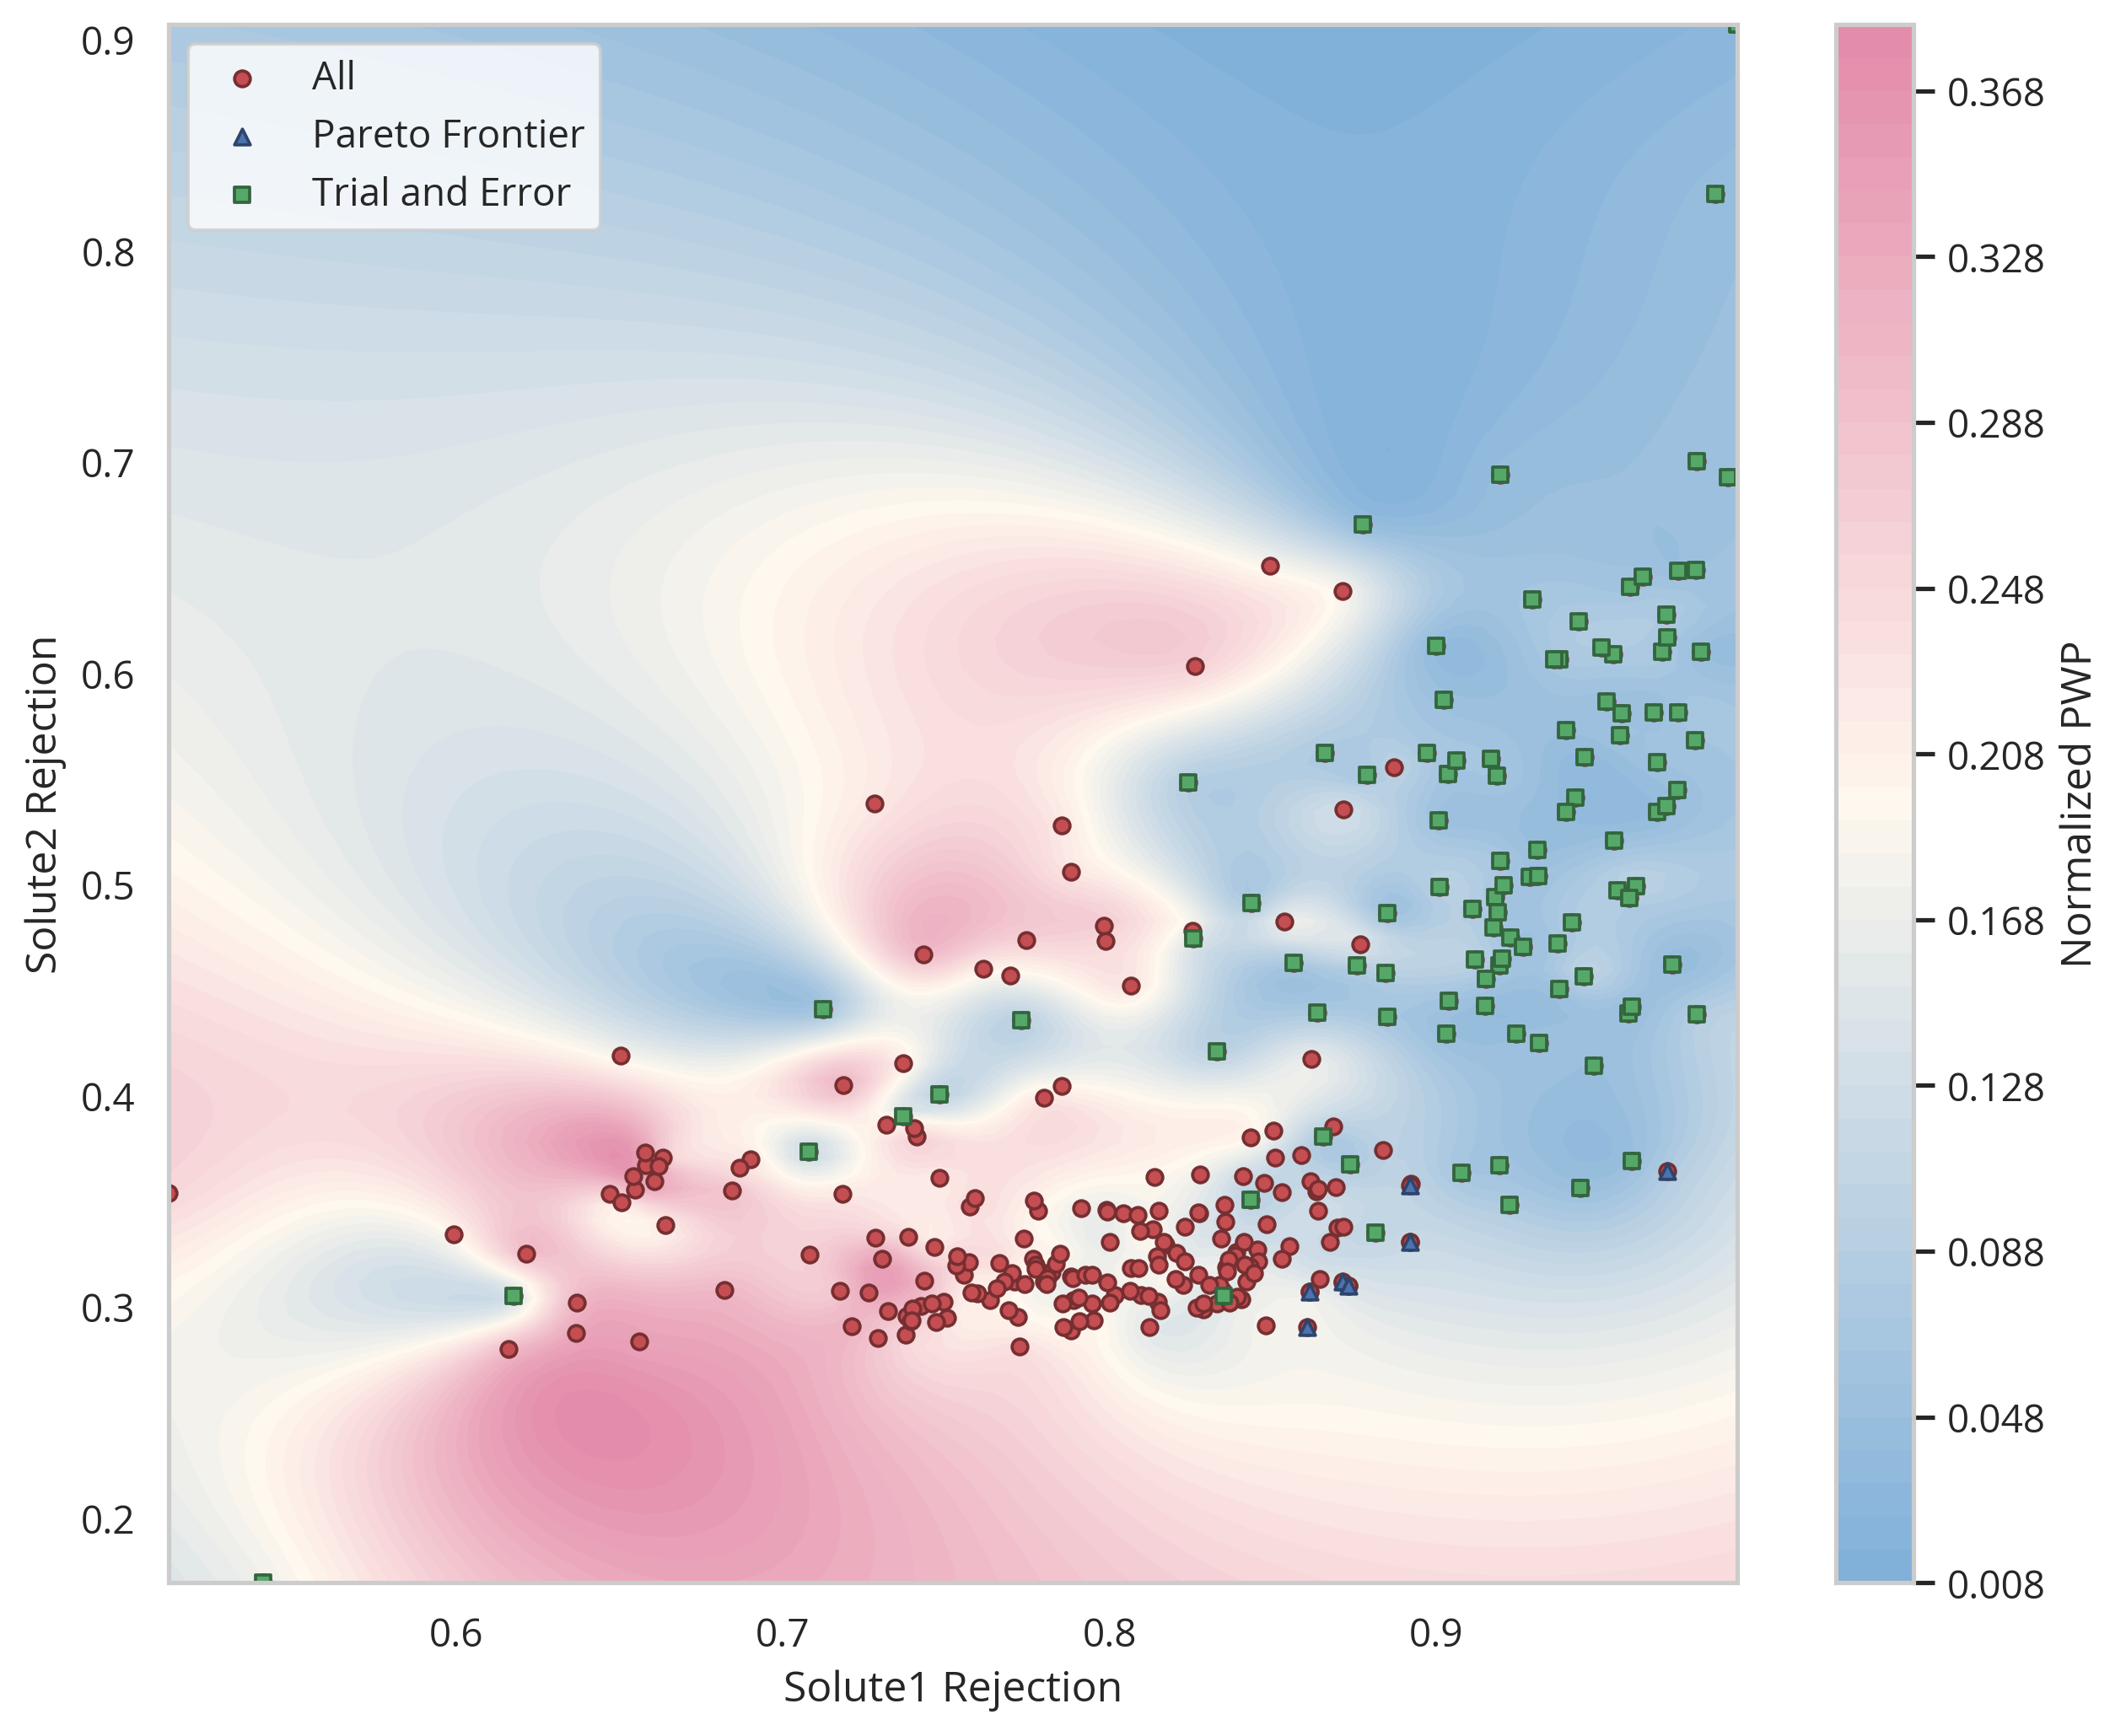

In [99]:
# plot a contour map of the 3D surface
from matplotlib.colors import to_rgb

def darker_color(color, factor=0.6):
    return tuple(np.clip(np.array(to_rgb(color)) * factor, 0, 1))

plt.figure(figsize=(10, 8))
contour = plt.contourf(X, Y, Z, levels=50, cmap=custom_cmap)
plt.colorbar(contour, label='Normalized PWP')

all_color = 'r'
frontier_color = 'b'
tande_color = 'g'

plt.scatter(
    x, y, c=all_color, marker='o', s=MARKER_SIZE, label='All',
    edgecolors=[darker_color(all_color)], linewidths=0.9
)
plt.scatter(
    frontier_df['solute1_Rejection'], frontier_df['solute2_Rejection'],
    c=frontier_color, marker='^', s=MARKER_SIZE, label='Pareto Frontier',
    edgecolors=[darker_color(frontier_color)], linewidths=0.9
)
plt.scatter(
    x_tande, y_tande, c=tande_color, marker='s', s=MARKER_SIZE, label='Trial and Error',
    edgecolors=[darker_color(tande_color)], linewidths=0.9
)
plt.xlabel('Solute1 Rejection')
plt.ylabel('Solute2 Rejection')
# plt.title('Contour Map of norm_Pure_Water_Permeability  with Trials Overlay')
plt.xlim([x_min, x_max])
plt.ylim([y_min, y_max])
plt.legend()

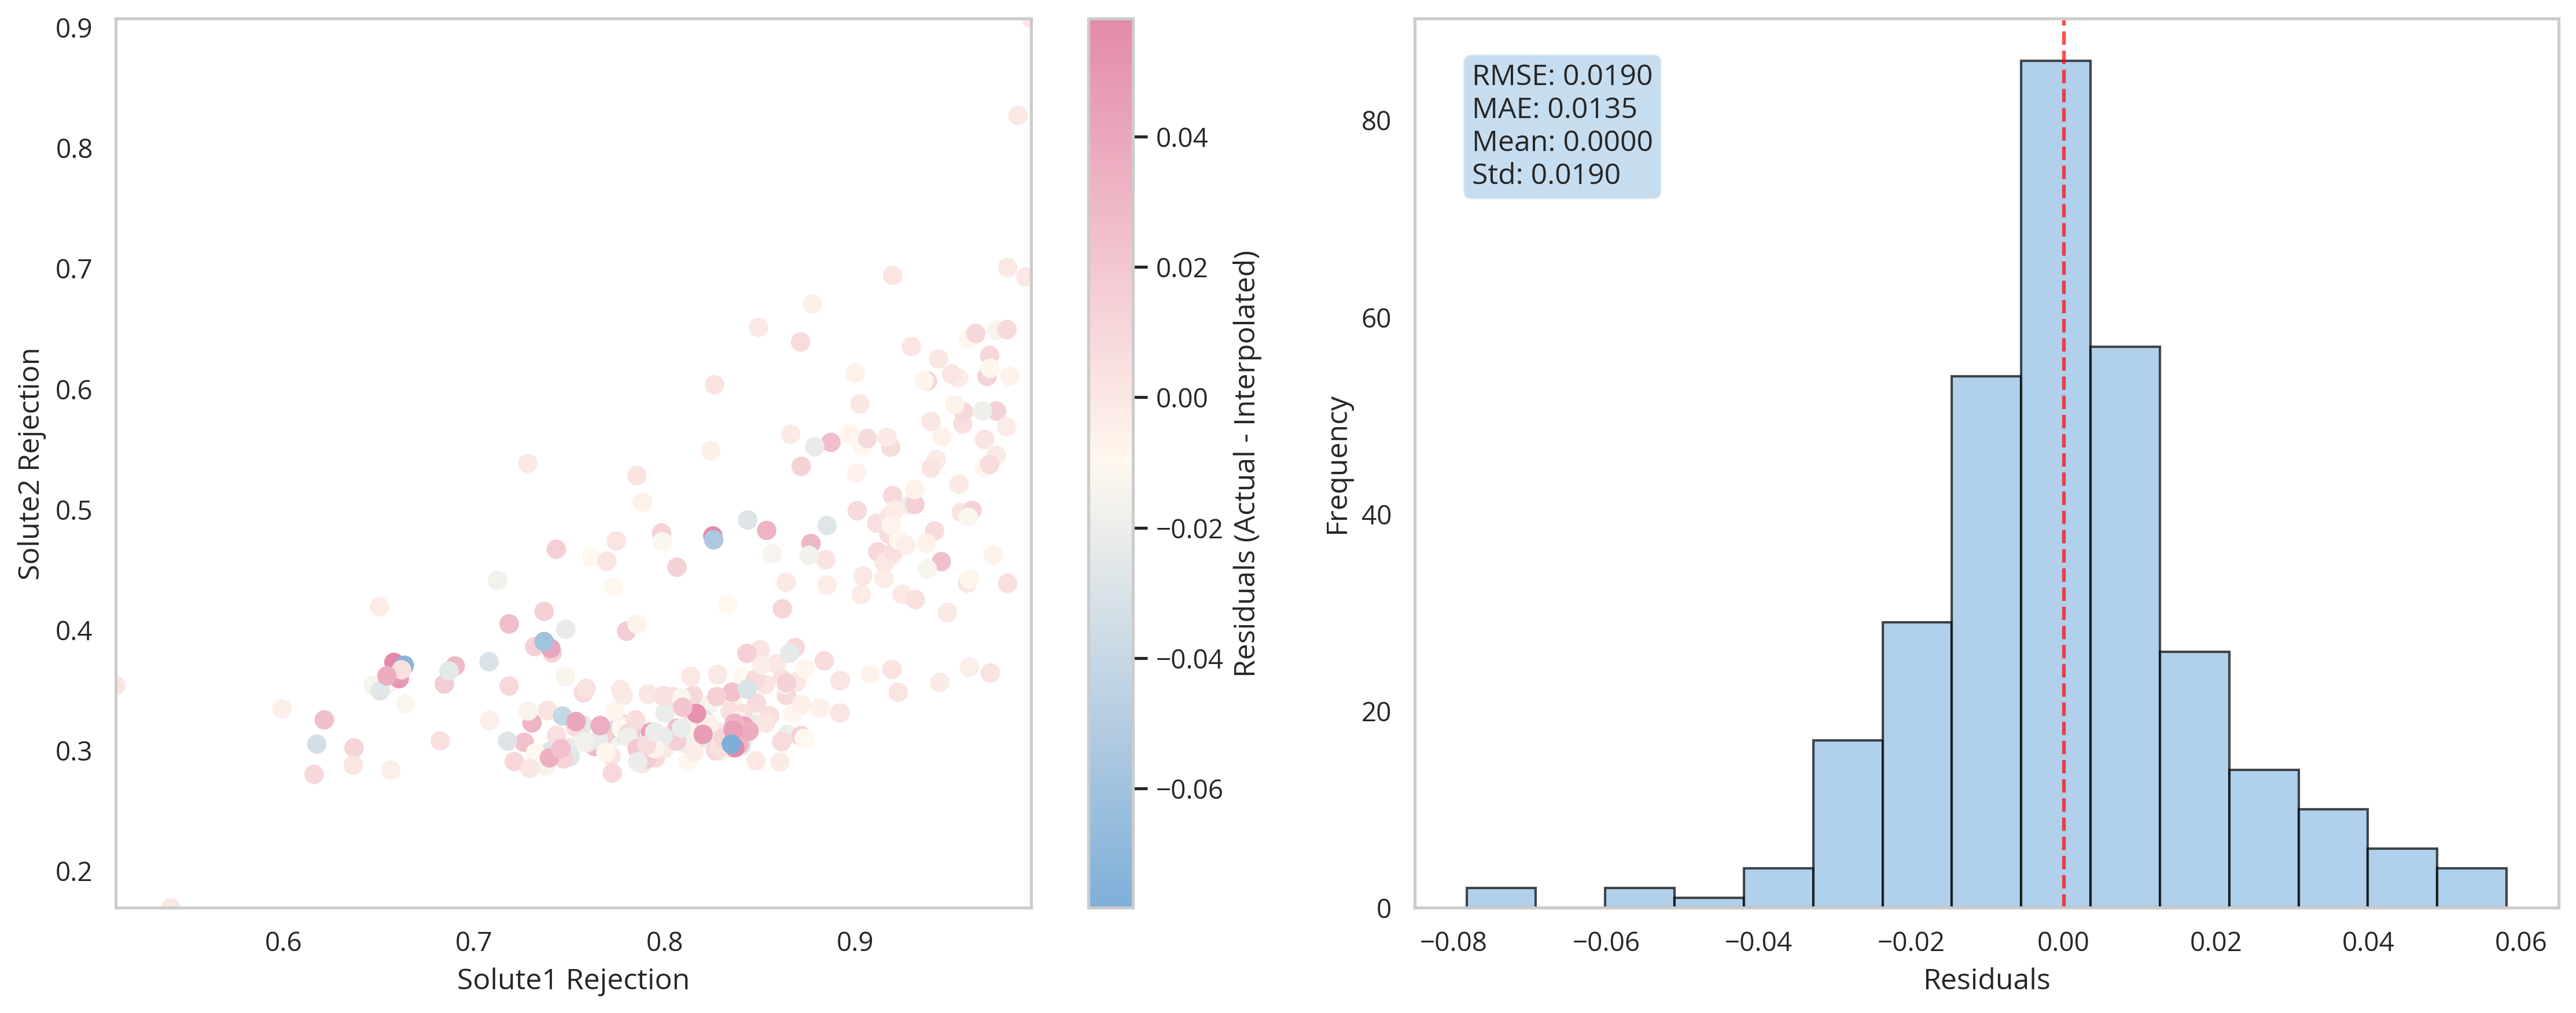

In [100]:
# Plot residuals of RBF interpolation
# Calculate interpolated values at the original data points
interpolated_at_data = rbf(points)
residuals = z - interpolated_at_data

# Create residual plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Residuals scatter plot
scatter = ax1.scatter(x, y, c=residuals, cmap=custom_cmap, s=50)
ax1.set_xlabel('Solute1 Rejection')
ax1.set_ylabel('Solute2 Rejection')
# ax1.set_title('norm_Pure_Water_Permeability Residuals of RBF Interpolation')
ax1.set_xlim([x_min, x_max])
ax1.set_ylim([y_min, y_max])
ax1.grid(False)
plt.colorbar(scatter, ax=ax1, label='Residuals (Actual - Interpolated)')

# Residuals histogram
ax2.hist(residuals, color = "#8fbce3", bins=15, alpha=0.7, edgecolor='black')
ax2.set_xlabel('Residuals')
ax2.set_ylabel('Frequency')
# ax2.set_title('Distribution of RBF Interpolation Residuals')
ax2.axvline(x=0, color='red', linestyle='--', alpha=0.7)
ax2.grid(False)

# Add statistics
rmse = np.sqrt(np.mean(residuals**2))
mae = np.mean(np.abs(residuals))
ax2.text(0.05, 0.95, f'RMSE: {rmse:.4f}\nMAE: {mae:.4f}\nMean: {np.mean(residuals):.4f}\nStd: {np.std(residuals):.4f}', 
         transform=ax2.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='#8fbce3', alpha=0.5))

plt.tight_layout()
plt.show()

In [69]:
# # display=True instructs Ax to sort then render the resulting analyses
# cards = client.compute_analyses(display=True)